# Final project

## 1. Data cleaning and processing

In [132]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [133]:
import os
!ls "/content/drive/MyDrive/uber final project/datasets/"

exercise_driver_state_hours_data.csv  exercise_sessions_data.csv
exercise_jobs_data.csv


In [134]:
import pandas as pd
import numpy as np

hourly_driver_state_duration = pd.read_csv("/content/drive/MyDrive/uber final project/datasets/exercise_driver_state_hours_data.csv")
driver_dispatches = pd.read_csv("/content/drive/MyDrive/uber final project/datasets/exercise_jobs_data.csv")
rider_sessions = pd.read_csv("/content/drive/MyDrive/uber final project/datasets/exercise_sessions_data.csv")

#hourly_driver_state_duration.head()
driver_dispatches.head()
#rider_sessions.head()

,city,job_id,driver_id,job_timestamp_local,offered_eta,dispatch_type,dispatch_length_km,is_accept,is_cancel
0,A,0001e-f2de-422d-9e8f-f2815a9c8c2dae4,cf528-5c14-40b9-8716-f9dc4c7ab742b64,2023-04-21 18:38:30.000,42,REGULAR,0.145,True,False
1,A,0001f-a859-484e-88d2-d4e997ad2425b0a,2421a-7dbb-4cad-aa5c-9f642a7472ba87f,2023-04-20 19:54:27.000,59,REGULAR,0.568,True,False
2,A,00022-dc17-42ee-b8e4-fe407bc2a0a5c8f,a5426-09b7-4d88-a026-7c748b752dfda46,2023-04-15 10:25:38.000,65,REGULAR,0.350,True,False
3,A,00058-e9aa-4b17-88e2-ccfa1e8f5ee4aec,b0610-0d80-475a-94b6-20c449bf7c96c8b,2023-04-06 16:32:43.000,113,REGULAR,0.663,True,False
4,A,0008e-5254-4bc0-824d-9cea72c928f250c,61a25-a9d6-45da-bcb1-7692b470dfc0078,2023-04-05 15:23:26.000,194,REGULAR,1.634,True,False


In [135]:
hourly_driver_state_duration = hourly_driver_state_duration.replace(r'\\N', np.nan, regex=True)
driver_dispatches =driver_dispatches.replace(r'\\N', np.nan, regex=True)
rider_sessions = rider_sessions.replace(r'\\N', np.nan, regex=True)

In [136]:
hourly_driver_state_duration.info()
driver_dispatches.info()
rider_sessions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64812 entries, 0 to 64811
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   city                 64812 non-null  object
 1   driver_id            64812 non-null  object
 2   hour                 64812 non-null  object
 3   active_time_ms       64812 non-null  int64 
 4   enroute_time_ms      64812 non-null  int64 
 5   ontrip_time_ms       64812 non-null  int64 
 6   open_time_ms         64812 non-null  int64 
 7   unavailable_time_ms  64812 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 4.0+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157285 entries, 0 to 157284
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   city                 157285 non-null  object 
 1   job_id               157285 non-null  object 
 2   driver_id            157285 non-n

In [137]:
hourly_driver_state_duration['hour'] = pd.to_datetime(hourly_driver_state_duration['hour'])

hourly_driver_state_duration.hour
hourly_driver_state_duration.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64812 entries, 0 to 64811
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   city                 64812 non-null  object        
 1   driver_id            64812 non-null  object        
 2   hour                 64812 non-null  datetime64[ns]
 3   active_time_ms       64812 non-null  int64         
 4   enroute_time_ms      64812 non-null  int64         
 5   ontrip_time_ms       64812 non-null  int64         
 6   open_time_ms         64812 non-null  int64         
 7   unavailable_time_ms  64812 non-null  int64         
dtypes: datetime64[ns](1), int64(5), object(2)
memory usage: 4.0+ MB


In [138]:


driver_dispatches['job_timestamp_local'] = pd.to_datetime(driver_dispatches['job_timestamp_local'])

driver_dispatches.job_timestamp_local
driver_dispatches.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157285 entries, 0 to 157284
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   city                 157285 non-null  object        
 1   job_id               157285 non-null  object        
 2   driver_id            157285 non-null  object        
 3   job_timestamp_local  157285 non-null  datetime64[ns]
 4   offered_eta          157285 non-null  int64         
 5   dispatch_type        157285 non-null  object        
 6   dispatch_length_km   157285 non-null  float64       
 7   is_accept            157285 non-null  bool          
 8   is_cancel            157285 non-null  bool          
dtypes: bool(2), datetime64[ns](1), float64(1), int64(1), object(4)
memory usage: 8.7+ MB


In [139]:


date_cols = ['session_start_timestamp_local', 'request_timestamp_local']


for col in date_cols:
    rider_sessions[col] = pd.to_datetime(rider_sessions[col])
    print(rider_sessions[col].head(5))

rider_sessions.info()



0   2023-04-05 21:43:31
1   2023-04-02 14:41:58
2   2023-04-07 22:26:57
3   2023-04-18 14:18:22
4   2023-04-02 16:25:43
Name: session_start_timestamp_local, dtype: datetime64[ns]
0                   NaT
1                   NaT
2                   NaT
3   2023-04-18 14:20:00
4                   NaT
Name: request_timestamp_local, dtype: datetime64[ns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145447 entries, 0 to 145446
Data columns (total 31 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   rider_session_id                     145447 non-null  object        
 1   session_start_timestamp_local        142822 non-null  datetime64[ns]
 2   rider_id                             145447 non-null  object        
 3   city                                 145447 non-null  object        
 4   app_version                          145447 non-null  object        
 5   duration_ms   

In [140]:
num_cols = [ 'session_last_eta','session_last_surge_multiplier', 'session_last_fare_local',
       'request_client_fare_local', 'request_surge_multiplier',
        'post_dispatch_eta', 'ata', 'est_rider_fare_distance_miles', 'trip_distance_miles',
       'trip_duration_seconds', 'cancellation_fee_local']

for col in num_cols:
  rider_sessions[col] = pd.to_numeric(rider_sessions[col], errors='coerce')



In [141]:
rider_sessions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145447 entries, 0 to 145446
Data columns (total 31 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   rider_session_id                     145447 non-null  object        
 1   session_start_timestamp_local        142822 non-null  datetime64[ns]
 2   rider_id                             145447 non-null  object        
 3   city                                 145447 non-null  object        
 4   app_version                          145447 non-null  object        
 5   duration_ms                          145447 non-null  float64       
 6   session_last_eta                     130958 non-null  float64       
 7   session_last_surge_multiplier        134118 non-null  float64       
 8   session_last_fare_local              132932 non-null  float64       
 9   session_average_trip_distance_miles  145447 non-null  float64       
 

In [142]:
rider_sessions.is_airport_trip.unique()

array([nan, 'false', 'true'], dtype=object)

In [143]:

bool_columns = ['is_airport_trip', 'is_business_trip', 'is_cash_trip' ,'is_scheduled_trip', 'is_multidestination']

for col in bool_columns:
    print(rider_sessions[col].head(10))

    if rider_sessions[col].dtype == object:

        rider_sessions[col] = rider_sessions[col].replace({
            'true': True,
            'false': False,
            'True': True,
            'False': False
        })
        rider_sessions[col]=rider_sessions[col].astype('boolean')
        print(rider_sessions[col].head(10))




0      NaN
1      NaN
2      NaN
3    false
4      NaN
5    false
6      NaN
7    false
8      NaN
9    false
Name: is_airport_trip, dtype: object
0     <NA>
1     <NA>
2     <NA>
3    False
4     <NA>
5    False
6     <NA>
7    False
8     <NA>
9    False
Name: is_airport_trip, dtype: boolean
0      NaN
1      NaN
2      NaN
3    false
4      NaN
5    false
6      NaN
7    false
8      NaN
9    false
Name: is_business_trip, dtype: object
0     <NA>
1     <NA>
2     <NA>
3    False
4     <NA>
5    False
6     <NA>
7    False
8     <NA>
9    False
Name: is_business_trip, dtype: boolean
0      NaN
1      NaN
2      NaN
3    false
4      NaN
5    false
6      NaN
7    false
8      NaN
9    false
Name: is_cash_trip, dtype: object
0     <NA>
1     <NA>
2     <NA>
3    False
4     <NA>
5    False
6     <NA>
7    False
8     <NA>
9    False
Name: is_cash_trip, dtype: boolean
0      NaN
1      NaN
2      NaN
3    false
4      NaN
5    false
6      NaN
7    false
8      NaN
9    false
Name: is_

In [144]:
rider_sessions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145447 entries, 0 to 145446
Data columns (total 31 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   rider_session_id                     145447 non-null  object        
 1   session_start_timestamp_local        142822 non-null  datetime64[ns]
 2   rider_id                             145447 non-null  object        
 3   city                                 145447 non-null  object        
 4   app_version                          145447 non-null  object        
 5   duration_ms                          145447 non-null  float64       
 6   session_last_eta                     130958 non-null  float64       
 7   session_last_surge_multiplier        134118 non-null  float64       
 8   session_last_fare_local              132932 non-null  float64       
 9   session_average_trip_distance_miles  145447 non-null  float64       
 

## 2. Market balance or imbalance

In [145]:
requested_rides = rider_sessions[rider_sessions['request_id'].notna()]

requested_rides.info()

requested_rides[['request_id', 'request_status', 'driver_id']].head(10)

<class 'pandas.core.frame.DataFrame'>
Index: 82624 entries, 3 to 145445
Data columns (total 31 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   rider_session_id                     82624 non-null  object        
 1   session_start_timestamp_local        82554 non-null  datetime64[ns]
 2   rider_id                             82624 non-null  object        
 3   city                                 82624 non-null  object        
 4   app_version                          82624 non-null  object        
 5   duration_ms                          82624 non-null  float64       
 6   session_last_eta                     76418 non-null  float64       
 7   session_last_surge_multiplier        77709 non-null  float64       
 8   session_last_fare_local              77121 non-null  float64       
 9   session_average_trip_distance_miles  82624 non-null  float64       
 10  pickup_geo    

,request_id,request_status,driver_id
3,005bd-f907-4fae-bd42-7ddee928e7f1885,completed,16456-50b2-44af-a869-500dfc2f4a0288c
5,8f0d5-8922-4d1d-aeb7-e0a77ddc49b297e,completed,0b95b-46cb-474b-8c0a-d900b90d20d994b
7,79dd5-d072-47bc-bec7-a1954208b55be2e,completed,84b22-2d16-47b0-b448-990f2dfcd86cbd9
9,2cce2-5ab7-4ee9-b920-f21f2f4e729e040,completed,5f097-28cc-4fbb-bb99-5babf8aa42499b5
10,75da0-eede-4e4a-9ded-412ceea08ae8f04,completed,9a9c0-4ca5-4468-a58b-52d68c4a9249b6a
13,45e2b-e2c0-41af-9efa-b1de8ade24f0c17,unfulfilled,NaN
14,0a1be-0e5e-4e1f-9c24-eaa57e4be1277d4,completed,c2290-082b-44c4-ad78-a1c4024b159b10c
15,94251-b815-427b-92de-eec2e4b495558ca,rider_canceled,NaN
16,ea80d-ab59-4dee-9950-282470b91e2df0e,completed,42b47-f20c-425a-8487-c2d274442f849d4
20,22f1d-40e5-4baa-9224-af0f52b924f0b54,completed,7c2fc-db0a-4ab4-905c-84924bf55484260


In [146]:
# For Rider Sessions (request_timestamp_local)
requested_rides['hour_bin'] = requested_rides['request_timestamp_local'].dt.floor('H')  # Truncate to hour

requested_rides[['request_timestamp_local', 'hour_bin']]


<ipython-input-146-0b3a1a474e10>:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  requested_rides['hour_bin'] = requested_rides['request_timestamp_local'].dt.floor('H')  # Truncate to hour
<ipython-input-146-0b3a1a474e10>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  requested_rides['hour_bin'] = requested_rides['request_timestamp_local'].dt.floor('H')  # Truncate to hour


,request_timestamp_local,hour_bin
3,2023-04-18 14:20:00,2023-04-18 14:00:00
5,2023-04-08 15:16:01,2023-04-08 15:00:00
7,2023-04-05 14:32:07,2023-04-05 14:00:00
9,2023-04-20 07:53:12,2023-04-20 07:00:00
10,2023-04-08 16:53:06,2023-04-08 16:00:00
...,...,...
145436,2023-04-02 02:26:31,2023-04-02 02:00:00
145438,2023-04-04 16:40:57,2023-04-04 16:00:00
145441,2023-04-04 15:21:13,2023-04-04 15:00:00
145444,2023-04-01 09:32:57,2023-04-01 09:00:00


In [147]:
hourly_driver_state_duration['hour']


,hour
0,2023-04-04 16:00:00
1,2023-04-04 17:00:00
2,2023-04-04 18:00:00
3,2023-04-01 11:00:00
4,2023-04-01 12:00:00
...,...
64807,2023-04-10 17:00:00
64808,2023-04-21 13:00:00
64809,2023-04-21 15:00:00
64810,2023-04-06 12:00:00


In [148]:
hourly_driver_state_duration = hourly_driver_state_duration.rename(columns={'hour': 'hour_bin'})
hourly_driver_state_duration['hour_bin']

,hour_bin
0,2023-04-04 16:00:00
1,2023-04-04 17:00:00
2,2023-04-04 18:00:00
3,2023-04-01 11:00:00
4,2023-04-01 12:00:00
...,...
64807,2023-04-10 17:00:00
64808,2023-04-21 13:00:00
64809,2023-04-21 15:00:00
64810,2023-04-06 12:00:00


In [149]:
# Active Drivers (open_time_ms > 0)
active_drivers = hourly_driver_state_duration[hourly_driver_state_duration['open_time_ms'] > 0] \
    .groupby(['city', 'hour_bin']) \
    .size() \
    .reset_index(name='active_drivers')

# Rider Requests
rider_requests = requested_rides.groupby(['city', 'hour_bin']) \
    .size() \
    .reset_index(name='requests')


active_drivers
rider_requests

,city,hour_bin,requests
0,A,2023-04-01 01:00:00,77
1,A,2023-04-01 02:00:00,53
2,A,2023-04-01 03:00:00,38
3,A,2023-04-01 04:00:00,58
4,A,2023-04-01 05:00:00,37
...,...,...,...
1501,C,2023-04-21 23:00:00,43
1502,C,2023-04-22 00:00:00,61
1503,C,2023-04-22 01:00:00,72
1504,C,2023-04-22 03:00:00,1


In [150]:
active_drivers

,city,hour_bin,active_drivers
0,A,2023-04-01 01:00:00,52
1,A,2023-04-01 02:00:00,41
2,A,2023-04-01 03:00:00,29
3,A,2023-04-01 04:00:00,27
4,A,2023-04-01 05:00:00,29
...,...,...,...
1495,C,2023-04-21 21:00:00,21
1496,C,2023-04-21 22:00:00,19
1497,C,2023-04-21 23:00:00,25
1498,C,2023-04-22 00:00:00,21


In [151]:
supply_state = pd.merge(
    active_drivers,
    rider_requests,
    on=['city', 'hour_bin'],
    how='outer'
).fillna(0)

supply_state


,city,hour_bin,active_drivers,requests
0,A,2023-04-01 01:00:00,52.0,77.0
1,A,2023-04-01 02:00:00,41.0,53.0
2,A,2023-04-01 03:00:00,29.0,38.0
3,A,2023-04-01 04:00:00,27.0,58.0
4,A,2023-04-01 05:00:00,29.0,37.0
...,...,...,...,...
1508,C,2023-04-21 23:00:00,25.0,43.0
1509,C,2023-04-22 00:00:00,21.0,61.0
1510,C,2023-04-22 01:00:00,19.0,72.0
1511,C,2023-04-22 03:00:00,0.0,1.0


In [152]:
supply_state.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   city            1513 non-null   object        
 1   hour_bin        1513 non-null   datetime64[ns]
 2   active_drivers  1513 non-null   float64       
 3   requests        1513 non-null   float64       
dtypes: datetime64[ns](1), float64(2), object(1)
memory usage: 47.4+ KB


In [153]:
supply_state['SDIR'] = supply_state['active_drivers'] / supply_state['requests']
supply_state

,city,hour_bin,active_drivers,requests,SDIR
0,A,2023-04-01 01:00:00,52.0,77.0,0.675325
1,A,2023-04-01 02:00:00,41.0,53.0,0.773585
2,A,2023-04-01 03:00:00,29.0,38.0,0.763158
3,A,2023-04-01 04:00:00,27.0,58.0,0.465517
4,A,2023-04-01 05:00:00,29.0,37.0,0.783784
...,...,...,...,...,...
1508,C,2023-04-21 23:00:00,25.0,43.0,0.581395
1509,C,2023-04-22 00:00:00,21.0,61.0,0.344262
1510,C,2023-04-22 01:00:00,19.0,72.0,0.263889
1511,C,2023-04-22 03:00:00,0.0,1.0,0.000000


In [154]:
supply_state['SDIR'].describe()

,SDIR
count,1513.000000
mean,inf
std,NaN
min,0.000000
25%,0.593407
50%,0.812500
75%,1.071429
max,inf


In [155]:
supply_state[np.isinf(supply_state['SDIR'])]

,city,hour_bin,active_drivers,requests,SDIR
577,B,2023-04-04 03:00:00,1.0,0.0,inf
768,B,2023-04-12 03:00:00,1.0,0.0,inf
791,B,2023-04-13 02:00:00,1.0,0.0,inf
792,B,2023-04-13 03:00:00,2.0,0.0,inf
910,B,2023-04-18 02:00:00,2.0,0.0,inf
911,B,2023-04-18 03:00:00,4.0,0.0,inf
983,B,2023-04-21 03:00:00,2.0,0.0,inf


In [156]:
supply_state['supply_state'] = np.where(
    supply_state['active_drivers'] > supply_state['requests'],
    'over-supply',
    np.where(
        supply_state['active_drivers'] < supply_state['requests'],
        'under-supply',
        'balanced'
    )
)

In [157]:
supply_state['hour_bin'].describe()

,hour_bin
count,1513
mean,2023-04-11 14:05:21.216126976
min,2023-04-01 01:00:00
25%,2023-04-06 07:00:00
50%,2023-04-11 14:00:00
75%,2023-04-16 20:00:00
max,2023-05-20 12:00:00


In [158]:
supply_state

,city,hour_bin,active_drivers,requests,SDIR,supply_state
0,A,2023-04-01 01:00:00,52.0,77.0,0.675325,under-supply
1,A,2023-04-01 02:00:00,41.0,53.0,0.773585,under-supply
2,A,2023-04-01 03:00:00,29.0,38.0,0.763158,under-supply
3,A,2023-04-01 04:00:00,27.0,58.0,0.465517,under-supply
4,A,2023-04-01 05:00:00,29.0,37.0,0.783784,under-supply
...,...,...,...,...,...,...
1508,C,2023-04-21 23:00:00,25.0,43.0,0.581395,under-supply
1509,C,2023-04-22 00:00:00,21.0,61.0,0.344262,under-supply
1510,C,2023-04-22 01:00:00,19.0,72.0,0.263889,under-supply
1511,C,2023-04-22 03:00:00,0.0,1.0,0.000000,under-supply


In [159]:
supply_state.hour_bin.max()

Timestamp('2023-05-20 12:00:00')

In [160]:
supply_state.hour_bin.min()

Timestamp('2023-04-01 01:00:00')

In [161]:
supply_freq = supply_state.groupby(['supply_state', 'city']).size().reset_index(name='count').sort_values(['city', 'count']).reset_index(drop=True)
supply_freq

,supply_state,city,count
0,balanced,A,15
1,over-supply,A,166
2,under-supply,A,323
3,balanced,B,11
4,over-supply,B,124
5,under-supply,B,368
6,balanced,C,12
7,over-supply,C,146
8,under-supply,C,348


In [162]:
# Calculate percentages by city
percentages = (
    supply_freq.groupby('city')['count']
    .transform(lambda x: round(x / x.sum() * 100, 1))
)

# Assign percentages while preserving index alignment
supply_freq = supply_freq.assign(percentage=percentages.values)

supply_freq

,supply_state,city,count,percentage
0,balanced,A,15,3.0
1,over-supply,A,166,32.9
2,under-supply,A,323,64.1
3,balanced,B,11,2.2
4,over-supply,B,124,24.7
5,under-supply,B,368,73.2
6,balanced,C,12,2.4
7,over-supply,C,146,28.9
8,under-supply,C,348,68.8


<ipython-input-163-567a23d4e083>:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),


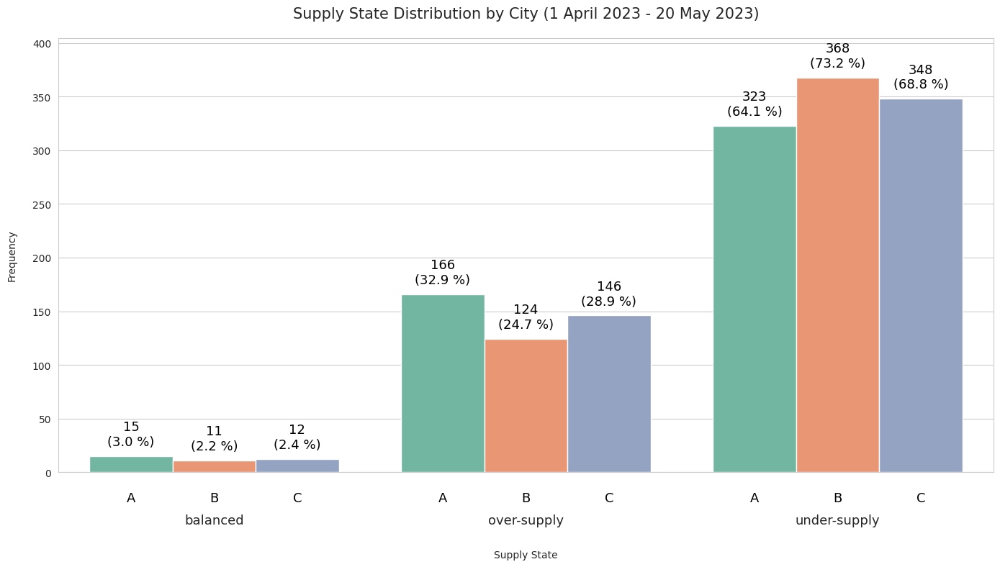

In [163]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 8))
ax = sns.barplot(data=supply_freq, x='supply_state', y='count', hue='city',
                palette='Set2', dodge=True,
                order=['balanced', 'over-supply', 'under-supply'],
                hue_order=['A', 'B', 'C'])


max_count = supply_freq['count'].max()
plt.ylim(0, max_count * 1.1)


label_y_offset = max_count * 0.07
city_label_y_offset = -max_count * 0.08


for i, bar in enumerate(ax.patches):
    if bar.get_height() > 0:
        city_idx = i % 3
        state_idx = i // 3
        city = ['A', 'B', 'C'][state_idx]
        state = ['balanced', 'over-supply', 'under-supply'][city_idx]

        match = supply_freq[(supply_freq['city'] == city) &
                          (supply_freq['supply_state'] == state)]

        if not match.empty:
            ax.text(bar.get_x() + bar.get_width()/2,
                   bar.get_height() + (max_count * 0.02),
                   f"{int(match['count'].iloc[0])}\n({float(match['percentage'].iloc[0])} %)",
                   ha='center', va='bottom',
                   color='black', fontsize=13)


            ax.text(bar.get_x() + bar.get_width()/2,
                   -max_count * 0.05,
                   city,
                   ha='center', va='top', fontsize=13, color='black')


# Adjust axis label positions
ax.xaxis.label.set_position([0.5, -0.15])
ax.yaxis.label.set_position([-0.1, 0.5])

# Move x-tick labels down
ax.set_xticklabels(ax.get_xticklabels(),
                  y=-0.08,
                  fontsize=13)

plt.title('Supply State Distribution by City (1 April 2023 - 20 May 2023)', pad=20, fontsize=15)
plt.xlabel('Supply State', labelpad=23)
plt.ylabel('Frequency', labelpad=15)
plt.legend().remove()
plt.tight_layout()
plt.show()

In [164]:
supply_state['hour'] = supply_state['hour_bin'].dt.strftime('%H:%M:%S')
supply_state

,city,hour_bin,active_drivers,requests,SDIR,supply_state,hour
0,A,2023-04-01 01:00:00,52.0,77.0,0.675325,under-supply,01:00:00
1,A,2023-04-01 02:00:00,41.0,53.0,0.773585,under-supply,02:00:00
2,A,2023-04-01 03:00:00,29.0,38.0,0.763158,under-supply,03:00:00
3,A,2023-04-01 04:00:00,27.0,58.0,0.465517,under-supply,04:00:00
4,A,2023-04-01 05:00:00,29.0,37.0,0.783784,under-supply,05:00:00
...,...,...,...,...,...,...,...
1508,C,2023-04-21 23:00:00,25.0,43.0,0.581395,under-supply,23:00:00
1509,C,2023-04-22 00:00:00,21.0,61.0,0.344262,under-supply,00:00:00
1510,C,2023-04-22 01:00:00,19.0,72.0,0.263889,under-supply,01:00:00
1511,C,2023-04-22 03:00:00,0.0,1.0,0.000000,under-supply,03:00:00


In [165]:

avg_sdir_by_city_hour = (
    supply_state.groupby(['city', 'hour'])['SDIR']
    .mean()
    .reset_index()
    .sort_values(['city', 'hour'])
    .round(2)
)


avg_sdir_by_city_hour = avg_sdir_by_city_hour.rename(columns={'SDIR': 'avg_SDIR'})


avg_sdir_by_city_hour.describe()

,avg_SDIR
count,72.0000
mean,inf
std,NaN
min,0.5200
25%,0.7900
50%,0.8800
75%,1.0325
max,inf


In [166]:
# Filter out infinite SDIR values before grouping
finite_supply = supply_state[np.isfinite(supply_state['SDIR'])]

avg_sdir_by_city_hour = (
    finite_supply.groupby(['city', 'hour'])['SDIR']
    .mean()
    .reset_index()
    .sort_values(['city', 'hour'])
    .round(2)
)


avg_sdir_by_city_hour = avg_sdir_by_city_hour.rename(columns={'SDIR': 'avg_SDIR'})

# Verify results
print("Rows with infinite SDIR removed:", len(supply_state) - len(finite_supply))
print(avg_sdir_by_city_hour.head())

Rows with infinite SDIR removed: 7
  city      hour  avg_SDIR
0    A  00:00:00      0.85
1    A  01:00:00      1.03
2    A  02:00:00      1.49
3    A  03:00:00      0.85
4    A  04:00:00      1.36


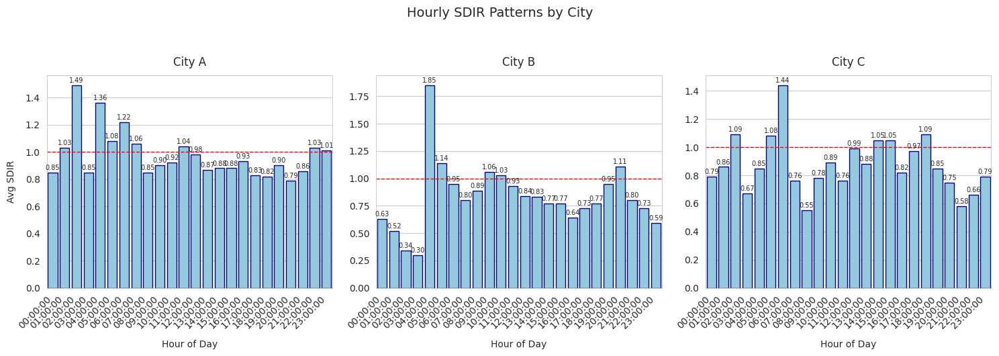

In [167]:
import matplotlib.pyplot as plt
import seaborn as sns

cities = ['A', 'B', 'C']
plt.figure(figsize=(15, 5))

for i, city in enumerate(cities, 1):
    plt.subplot(1, 3, i)  # 1 row, 3 columns
    city_data = avg_sdir_by_city_hour[avg_sdir_by_city_hour['city'] == city]

    # Create bar plot
    ax = sns.barplot(
        data=city_data,
        x='hour',
        y='avg_SDIR',
        color='skyblue',
        edgecolor='navy'
    )

    # Customize plot
    plt.title(f'City {city}', pad=10)
    plt.xlabel('Hour of Day', labelpad=10)
    plt.ylabel('Avg SDIR' if i == 1 else '', labelpad=10)  # Only show y-label for first plot
    plt.xticks(rotation=45, ha='right')  # Fix label overlap
    plt.axhline(1, color='red', linestyle='--', linewidth=1)

    # Add value labels on top bars
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.2f}",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center', va='center',
            xytext=(0, 5),
            textcoords='offset points', fontsize= 7
        )

plt.suptitle('Hourly SDIR Patterns by City', y=1.05, fontsize=14)
plt.tight_layout()
plt.show()

In [168]:
supply_state[ (supply_state['city'] == 'B') &
    (supply_state['hour'].isin(['02:00:00', '03:00:00']))]

,city,hour_bin,active_drivers,requests,SDIR,supply_state,hour
504,B,2023-04-01 02:00:00,7.0,47.0,0.148936,under-supply,02:00:00
505,B,2023-04-01 03:00:00,2.0,18.0,0.111111,under-supply,03:00:00
528,B,2023-04-02 02:00:00,9.0,59.0,0.152542,under-supply,02:00:00
529,B,2023-04-02 03:00:00,4.0,46.0,0.086957,under-supply,03:00:00
552,B,2023-04-03 02:00:00,0.0,1.0,0.000000,under-supply,02:00:00
553,B,2023-04-03 03:00:00,1.0,2.0,0.500000,under-supply,03:00:00
576,B,2023-04-04 02:00:00,1.0,5.0,0.200000,under-supply,02:00:00
577,B,2023-04-04 03:00:00,1.0,0.0,inf,over-supply,03:00:00
600,B,2023-04-05 02:00:00,1.0,5.0,0.200000,under-supply,02:00:00
601,B,2023-04-05 03:00:00,2.0,10.0,0.200000,under-supply,03:00:00


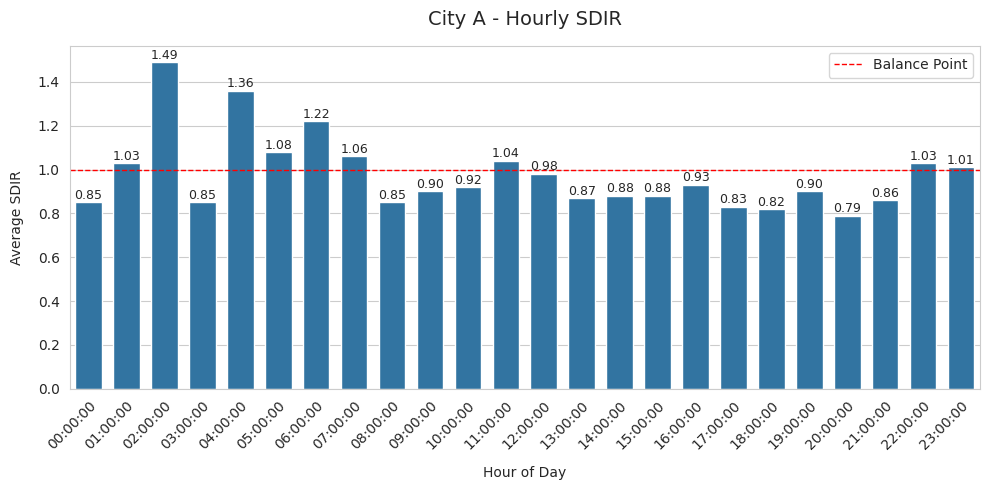

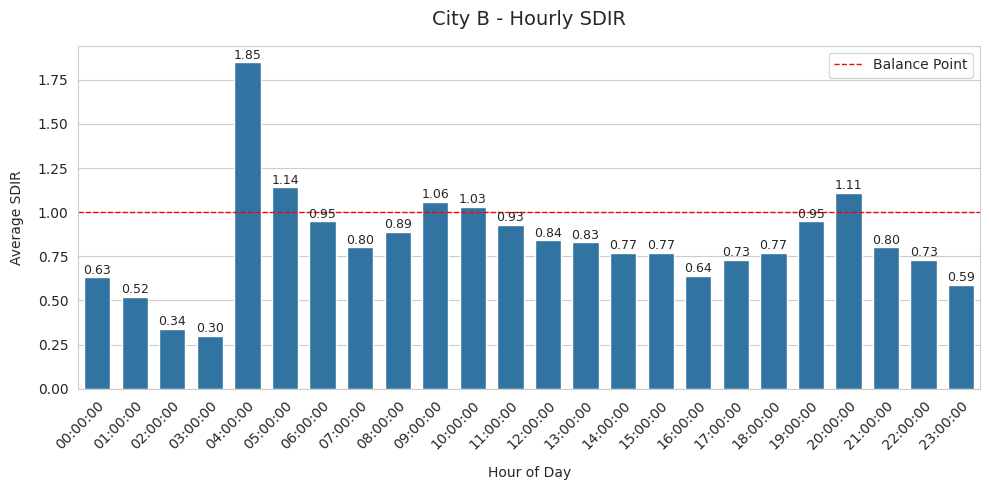

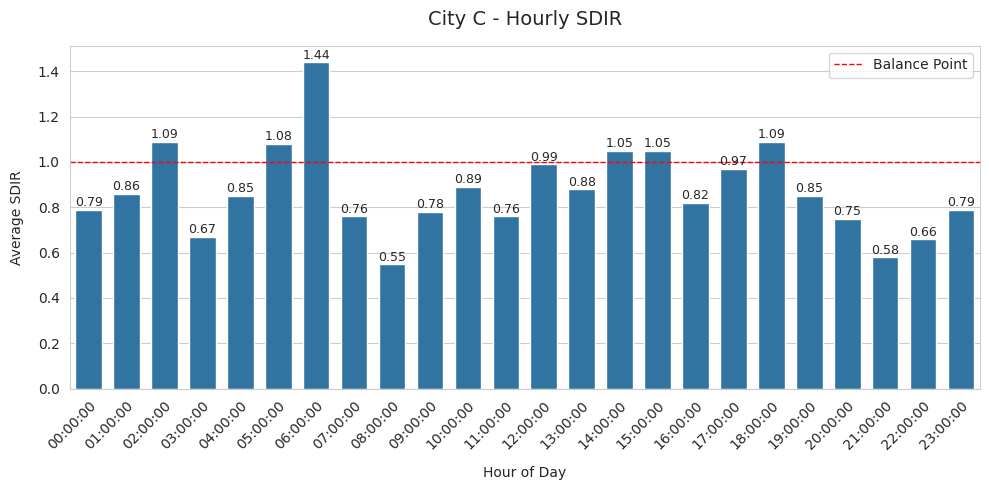

In [169]:
def sdir_graph(df,name, xcol, ycol, xname):

  cities = ['A', 'B', 'C']

  for city in cities:
    plt.figure(figsize=(10, 5))
    city_data = df[df['city'] == city]


    ax = sns.barplot(
        data=city_data,
        x=xcol,
        y=ycol,
        color='#1f77b4',
        width=0.7
    )


    plt.title(f'City {city} - '+name, pad=15, fontsize=14)
    plt.xlabel(xname, labelpad=10)
    plt.ylabel('Average SDIR', labelpad=10)


    plt.xticks(
        rotation=45,
        ha='right',
        rotation_mode='anchor'
    )


    plt.axhline(1, color='red', linestyle='--', linewidth=1, label='Balance Point')


    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.2f}",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center',
            va='center',
            xytext=(0, 5),
            textcoords='offset points',
            fontsize=9
        )

    plt.legend()
    plt.tight_layout()
    plt.show()


sdir_graph(avg_sdir_by_city_hour,'Hourly SDIR', 'hour', 'avg_SDIR', 'Hour of Day')

In [170]:
from datetime import datetime

#0 Monday - 6 Sunday
supply_state['day_of_week'] = supply_state['hour_bin'].dt.dayofweek
supply_state['day_name'] = supply_state['hour_bin'].dt.strftime("%A")
supply_state

,city,hour_bin,active_drivers,requests,SDIR,supply_state,hour,day_of_week,day_name
0,A,2023-04-01 01:00:00,52.0,77.0,0.675325,under-supply,01:00:00,5,Saturday
1,A,2023-04-01 02:00:00,41.0,53.0,0.773585,under-supply,02:00:00,5,Saturday
2,A,2023-04-01 03:00:00,29.0,38.0,0.763158,under-supply,03:00:00,5,Saturday
3,A,2023-04-01 04:00:00,27.0,58.0,0.465517,under-supply,04:00:00,5,Saturday
4,A,2023-04-01 05:00:00,29.0,37.0,0.783784,under-supply,05:00:00,5,Saturday
...,...,...,...,...,...,...,...,...,...
1508,C,2023-04-21 23:00:00,25.0,43.0,0.581395,under-supply,23:00:00,4,Friday
1509,C,2023-04-22 00:00:00,21.0,61.0,0.344262,under-supply,00:00:00,5,Saturday
1510,C,2023-04-22 01:00:00,19.0,72.0,0.263889,under-supply,01:00:00,5,Saturday
1511,C,2023-04-22 03:00:00,0.0,1.0,0.000000,under-supply,03:00:00,5,Saturday


In [171]:
finite_supply = supply_state[np.isfinite(supply_state['SDIR'])]

avg_sdir_by_city_week_day = (
    finite_supply.groupby(['city', 'day_of_week', 'day_name'])['SDIR']
    .mean()
    .reset_index()
    .sort_values(['city', 'day_of_week'])
    .round(2)  # Round to 2 decimal places
)


avg_sdir_by_city_week_day = avg_sdir_by_city_week_day.rename(columns={'SDIR': 'avg_SDIR'})


print("Rows with infinite SDIR removed:", len(supply_state) - len(finite_supply))
print(avg_sdir_by_city_week_day.head(7))


Rows with infinite SDIR removed: 7
  city  day_of_week   day_name  avg_SDIR
0    A            0     Monday      1.23
1    A            1    Tuesday      1.03
2    A            2  Wednesday      1.13
3    A            3   Thursday      1.05
4    A            4     Friday      0.82
5    A            5   Saturday      0.80
6    A            6     Sunday      0.77


In [172]:
avg_sdir_by_city_weekday_hour = (
    finite_supply.groupby(['city', 'day_of_week', 'day_name', 'hour'])['SDIR']
    .mean()
    .reset_index()
    .sort_values(['city', 'day_of_week', 'hour'])
    .round(2)
)

# Rename column for clarity
avg_sdir_by_city_weekday_hour = avg_sdir_by_city_weekday_hour.rename(columns={'SDIR': 'avg_SDIR'})

avg_sdir_by_city_weekday_hour['day_hour'] = avg_sdir_by_city_weekday_hour['day_name'] + ' ' + avg_sdir_by_city_weekday_hour['hour']
avg_sdir_by_city_weekday_hour.head(10)

,city,day_of_week,day_name,hour,avg_SDIR,day_hour
0,A,0,Monday,00:00:00,0.61,Monday 00:00:00
1,A,0,Monday,01:00:00,1.11,Monday 01:00:00
2,A,0,Monday,02:00:00,4.59,Monday 02:00:00
3,A,0,Monday,03:00:00,0.84,Monday 03:00:00
4,A,0,Monday,04:00:00,3.35,Monday 04:00:00
5,A,0,Monday,05:00:00,1.06,Monday 05:00:00
6,A,0,Monday,06:00:00,1.55,Monday 06:00:00
7,A,0,Monday,07:00:00,1.17,Monday 07:00:00
8,A,0,Monday,08:00:00,0.86,Monday 08:00:00
9,A,0,Monday,09:00:00,1.05,Monday 09:00:00


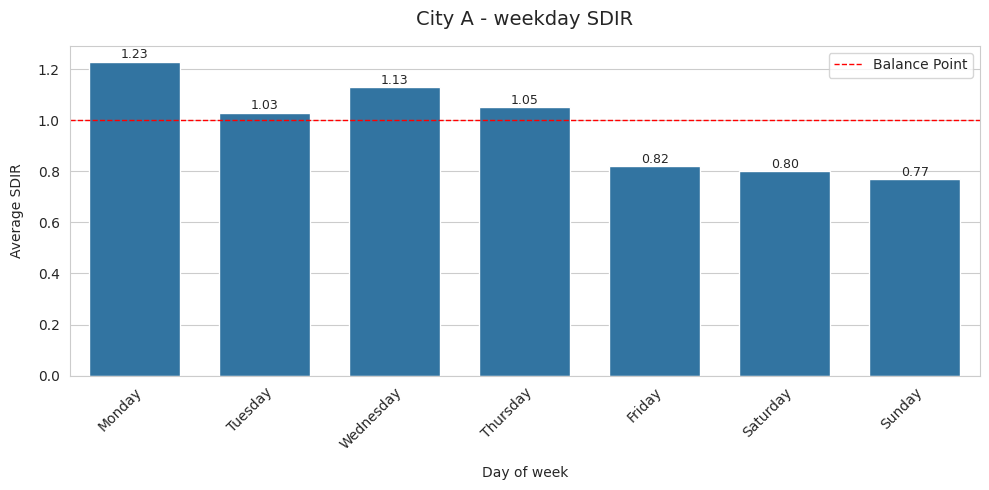

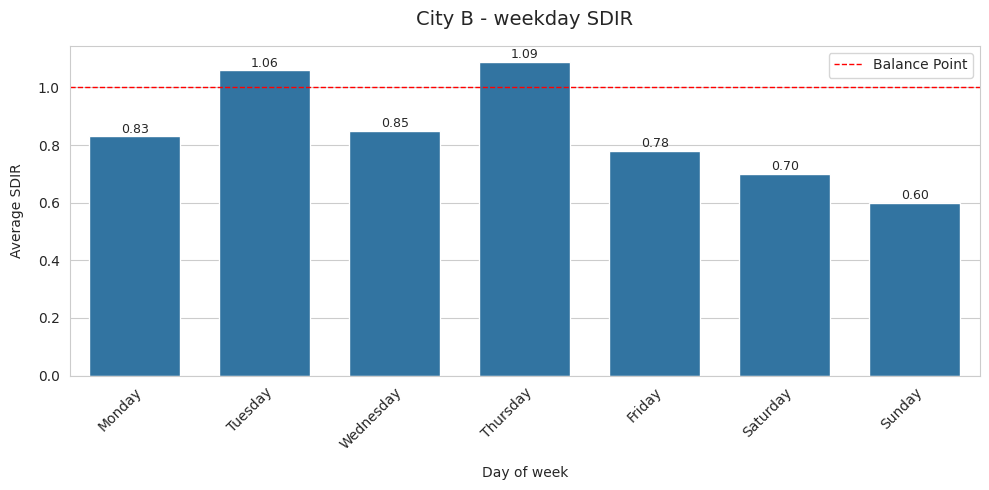

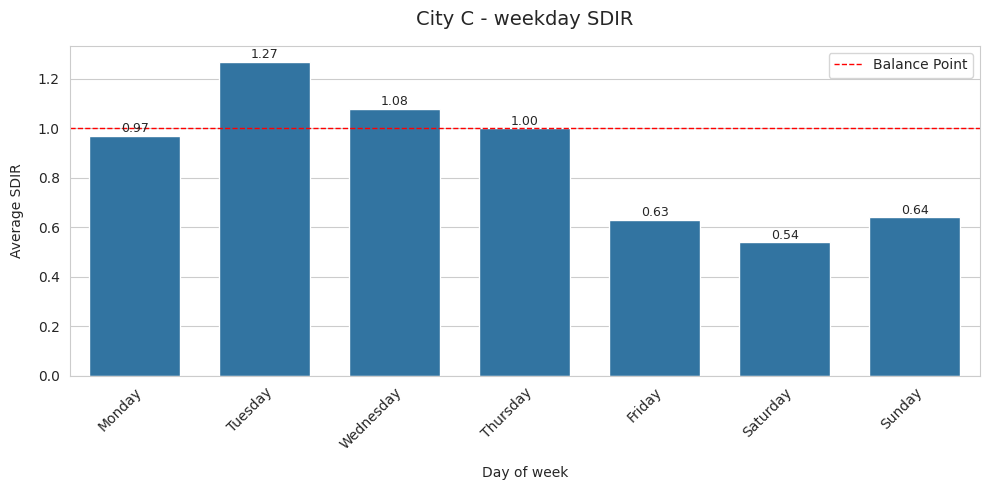

In [173]:
sdir_graph(avg_sdir_by_city_week_day,'weekday SDIR', 'day_name', 'avg_SDIR', 'Day of week')

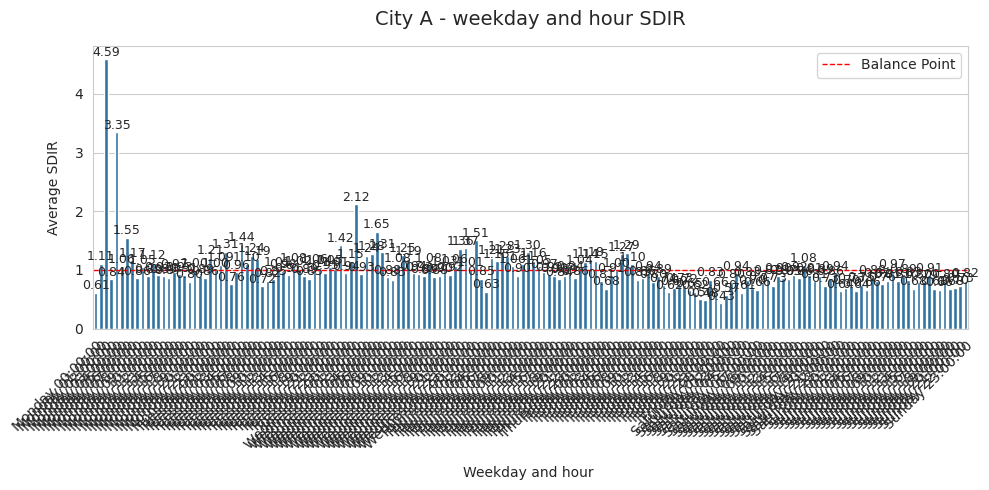

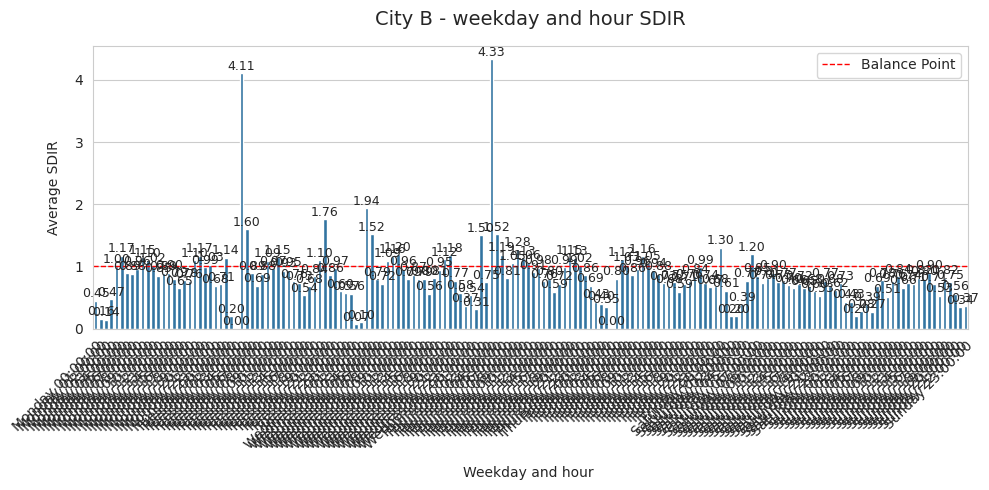

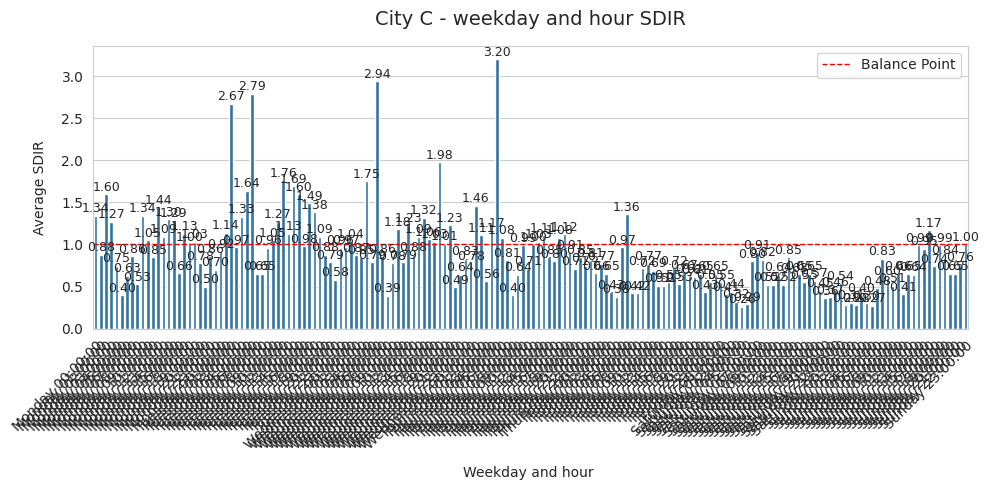

In [174]:
sdir_graph(avg_sdir_by_city_weekday_hour,'weekday and hour SDIR', 'day_hour', 'avg_SDIR', 'Weekday and hour ')

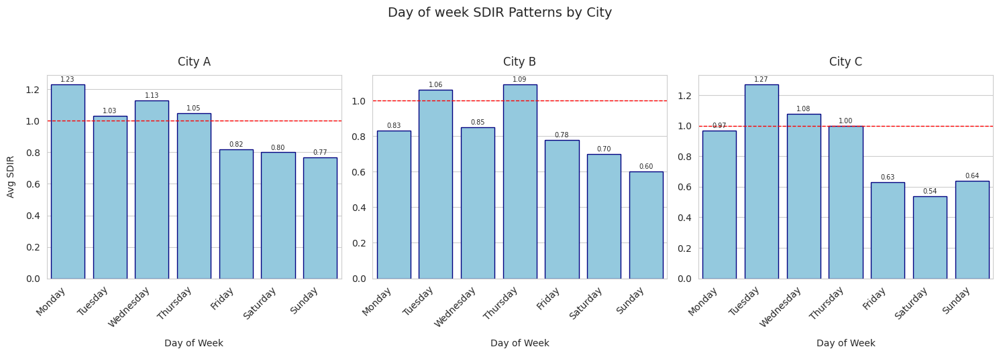

In [175]:
import matplotlib.pyplot as plt
import seaborn as sns

cities = ['A', 'B', 'C']
plt.figure(figsize=(15, 5))

for i, city in enumerate(cities, 1):
    plt.subplot(1, 3, i)  # 1 row, 3 columns
    city_data = avg_sdir_by_city_week_day[avg_sdir_by_city_week_day['city'] == city]

    # Create bar plot
    ax = sns.barplot(
        data=city_data,
        x='day_name',
        y='avg_SDIR',
        color='skyblue',
        edgecolor='navy'
    )

    # Customize plot
    plt.title(f'City {city}', pad=10)
    plt.xlabel('Day of Week', labelpad=10)
    plt.ylabel('Avg SDIR' if i == 1 else '', labelpad=10)  # Only show y-label for first plot
    plt.xticks(rotation=45, ha='right')  # Fix label overlap
    plt.axhline(1, color='red', linestyle='--', linewidth=1)

    # Add value labels on top bars
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.2f}",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center', va='center',
            xytext=(0, 5),
            textcoords='offset points', fontsize= 7
        )

plt.suptitle('Day of week SDIR Patterns by City', y=1.05, fontsize=14)
plt.tight_layout()
plt.show()

## 3. Market Reliability

In [176]:
requested_rides[[ 'session_last_eta','session_last_surge_multiplier', 'session_last_fare_local',
       'request_client_fare_local', 'request_surge_multiplier',
        'post_dispatch_eta', 'ata', 'est_rider_fare_distance_miles', 'trip_distance_miles',
       'trip_duration_seconds', 'cancellation_fee_local', 'hour_bin']]

,session_last_eta,session_last_surge_multiplier,session_last_fare_local,request_client_fare_local,request_surge_multiplier,post_dispatch_eta,ata,est_rider_fare_distance_miles,trip_distance_miles,trip_duration_seconds,cancellation_fee_local,hour_bin
3,1.0,1.0,7.55,7.55,1.0,85.0,165.0,6.74,6.582918,765.0,0.0,2023-04-18 14:00:00
5,1.0,1.0,10.42,10.42,1.0,33.0,42.0,6.98,7.899191,1362.0,0.0,2023-04-08 15:00:00
7,1.0,1.0,5.97,5.97,1.0,196.0,565.0,5.99,6.090668,756.0,0.0,2023-04-05 14:00:00
9,7.0,1.0,7.61,7.61,1.0,453.0,494.0,4.92,4.730686,692.0,0.0,2023-04-20 07:00:00
10,7.0,1.0,12.60,12.60,1.0,162.0,217.0,2.62,2.797798,673.0,0.0,2023-04-08 16:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...
145436,8.0,1.0,202.00,202.00,1.0,745.0,NaN,20.98,0.000000,0.0,0.0,2023-04-02 02:00:00
145438,3.0,1.1,53.00,53.00,1.1,86.0,140.0,3.20,3.201228,722.0,0.0,2023-04-04 16:00:00
145441,6.0,1.0,68.00,68.00,1.0,327.0,384.0,6.27,6.945244,1435.0,0.0,2023-04-04 15:00:00
145444,2.0,1.0,6.39,6.39,1.0,101.0,133.0,3.90,4.132858,632.0,0.0,2023-04-01 09:00:00


In [177]:
requested_rides2 = requested_rides.copy()

In [178]:
requested_rides2['is_matched'] = ~requested_rides2['driver_id'].isna()
requested_rides2[['is_matched', 'request_id','driver_id']].head(10)

,is_matched,request_id,driver_id
3,True,005bd-f907-4fae-bd42-7ddee928e7f1885,16456-50b2-44af-a869-500dfc2f4a0288c
5,True,8f0d5-8922-4d1d-aeb7-e0a77ddc49b297e,0b95b-46cb-474b-8c0a-d900b90d20d994b
7,True,79dd5-d072-47bc-bec7-a1954208b55be2e,84b22-2d16-47b0-b448-990f2dfcd86cbd9
9,True,2cce2-5ab7-4ee9-b920-f21f2f4e729e040,5f097-28cc-4fbb-bb99-5babf8aa42499b5
10,True,75da0-eede-4e4a-9ded-412ceea08ae8f04,9a9c0-4ca5-4468-a58b-52d68c4a9249b6a
13,False,45e2b-e2c0-41af-9efa-b1de8ade24f0c17,NaN
14,True,0a1be-0e5e-4e1f-9c24-eaa57e4be1277d4,c2290-082b-44c4-ad78-a1c4024b159b10c
15,False,94251-b815-427b-92de-eec2e4b495558ca,NaN
16,True,ea80d-ab59-4dee-9950-282470b91e2df0e,42b47-f20c-425a-8487-c2d274442f849d4
20,True,22f1d-40e5-4baa-9224-af0f52b924f0b54,7c2fc-db0a-4ab4-905c-84924bf55484260


In [179]:
requested_rides2['request_status'].unique()

array(['completed', 'unfulfilled', 'rider_canceled', 'driver_canceled',
       'failed'], dtype=object)

## Reliability and matched

In [180]:
request_status_counts = (
    requested_rides2
    .groupby(['city', 'request_status'])
    .size()
    .reset_index(name='count')
    .sort_values(['city', 'request_status'])
)

# Display results
print("Match Counts by City and Request Status:")
request_status_counts

Match Counts by City and Request Status:


,city,request_status,count
0,A,completed,33756
1,A,driver_canceled,185
2,A,rider_canceled,2596
3,A,unfulfilled,318
4,B,completed,20314
5,B,driver_canceled,464
6,B,failed,1
7,B,rider_canceled,6718
8,B,unfulfilled,1455
9,C,completed,11146


In [181]:
# Group and count matches
match_counts = (
    requested_rides2
    .groupby(['city', 'request_status', 'is_matched'])
    .size()
    .unstack(fill_value=0)
    .rename(columns={True: 'Matched', False: 'Unmatched'})
    .sort_values(['city', 'request_status'])
)

# Add total column
match_counts['Total'] = match_counts.sum(axis=1)

# Display results
print("Match Counts by City and Request Status:")
match_counts

Match Counts by City and Request Status:


is_matched            Unmatched  Matched  Total
city request_status                            
A    completed                0    33756  33756
     driver_canceled          0      185    185
     rider_canceled        1228     1368   2596
     unfulfilled            311        7    318
B    completed                0    20314  20314
     driver_canceled          0      464    464
     failed                   1        0      1
     rider_canceled        2886     3832   6718
     unfulfilled           1267      188   1455
C    completed                0    11146  11146
     driver_canceled          0      256    256
     failed                   2        0      2
     rider_canceled        3144     1537   4681
     unfulfilled            654       78    732

In [182]:
#Completed - reliable, not completed - unreliable

requested_rides2['is_reliable_pickup'] = requested_rides2['request_status'] == 'completed'

requested_rides2[['is_reliable_pickup', 'request_status']].head(15)

,is_reliable_pickup,request_status
3,True,completed
5,True,completed
7,True,completed
9,True,completed
10,True,completed
13,False,unfulfilled
14,True,completed
15,False,rider_canceled
16,True,completed
20,True,completed


In [183]:

# Convert boolean/NA to categorical labels first
requested_rides2['reliability_status'] = np.select(
    [
        requested_rides2['is_reliable_pickup'] == True,
        requested_rides2['is_reliable_pickup'] == False
    ],
    [
        "Reliable",
        "Unreliable"
    ],
    default="NA"
)

# Group and count reliability status
reliability_counts = requested_rides2.groupby(
    ['city', 'request_status', 'reliability_status']
).size().unstack(fill_value=0)

# Add total column
reliability_counts['Total'] = reliability_counts.sum(axis=1)

# Reorder columns if needed
reliability_counts = reliability_counts[['Reliable', 'Unreliable', 'Total']]

# Sort by city and status
reliability_counts = reliability_counts.sort_index(level=['city', 'request_status'])

# Display results
reliability_counts

reliability_status    Reliable  Unreliable  Total
city request_status                              
A    completed           33756           0  33756
     driver_canceled         0         185    185
     rider_canceled          0        2596   2596
     unfulfilled             0         318    318
B    completed           20314           0  20314
     driver_canceled         0         464    464
     failed                  0           1      1
     rider_canceled          0        6718   6718
     unfulfilled             0        1455   1455
C    completed           11146           0  11146
     driver_canceled         0         256    256
     failed                  0           2      2
     rider_canceled          0        4681   4681
     unfulfilled             0         732    732

In [184]:

requested_rides_supply = pd.merge(
    requested_rides2,
    supply_state,
    on=['city', 'hour_bin'],
    how='inner',
    suffixes=('_ride', '_supply')
)

requested_rides_supply

,rider_session_id,session_start_timestamp_local,rider_id,city,app_version,duration_ms,session_last_eta,session_last_surge_multiplier,session_last_fare_local,session_average_trip_distance_miles,...,is_matched,is_reliable_pickup,reliability_status,active_drivers,requests,SDIR,supply_state,hour,day_of_week,day_name
0,00038-50b1-4019-ace3-8bd1f6fdf16f94f,2023-04-18 14:18:22,e6ad1-2232-4382-8270-60d10d3becb21e6,A,3.557.10000,3047613.0,1.0,1.0,7.55,5.057579,...,True,True,Reliable,93.0,84.0,1.107143,over-supply,14:00:00,1,Tuesday
1,0003d-554e-4b66-a8bd-66e33cd8aee3989,2023-04-08 15:15:52,bdcb8-6330-4416-a461-4e32613e01063c7,A,4.467.10008,1583748.0,1.0,1.0,10.42,5.545788,...,True,True,Reliable,95.0,112.0,0.848214,under-supply,15:00:00,5,Saturday
2,00046-48ed-4fe4-8f40-fdf3959f6803fe1,2023-04-05 14:29:05,d480f-be2f-416f-8003-03bb0d1f340aafe,A,3.555.10002,1531628.0,1.0,1.0,5.97,4.390179,...,True,True,Reliable,93.0,107.0,0.869159,under-supply,14:00:00,2,Wednesday
3,0004d-bc91-4496-b54e-f98f346e4fb994b,2023-04-20 07:52:51,83274-0d00-4bf8-b170-cddb8eaed2ca8fe,A,4.469.10002,1275991.0,7.0,1.0,7.61,3.872201,...,True,True,Reliable,40.0,36.0,1.111111,over-supply,07:00:00,3,Thursday
4,0004e-93bf-45b4-bf41-ea5ee38419ea48d,2023-04-08 16:52:56,1da1c-2373-4bfa-af37-d322a0c1033f131,C,3.556.10002,1166481.0,7.0,1.0,12.60,1.806553,...,True,True,Reliable,28.0,73.0,0.383562,under-supply,16:00:00,5,Saturday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82619,ffff8-dc01-4ac9-bedc-aa04464101d01a6,2023-04-02 02:26:22,77110-c8ed-43d8-dc20-e324102203747fb,B,4.467.10004,2508345.0,8.0,1.0,202.00,16.470834,...,True,False,Unreliable,9.0,59.0,0.152542,under-supply,02:00:00,6,Sunday
82620,ffffa-8a80-43f3-8019-fd68f4f6af546bf,2023-04-04 16:40:53,61b36-2ae0-43d3-ddde-14fddda6d476034,B,3.555.10002,1011442.0,3.0,1.1,53.00,1.687286,...,True,True,Reliable,84.0,125.0,0.672000,under-supply,16:00:00,1,Tuesday
82621,ffffc-b0f8-4e8b-af09-9da386cab0d80bf,2023-04-04 15:21:09,f23bb-8bdd-483c-a603-8d3380300b468b7,B,3.555.10002,2017502.0,6.0,1.0,68.00,4.838207,...,True,True,Reliable,85.0,105.0,0.809524,under-supply,15:00:00,1,Tuesday
82622,fffff-160f-49ec-9f0f-b466648fe049a88,2023-04-01 09:32:44,ebf2a-dcb1-44c0-b234-b1671d3271edddf,A,4.467.10003,1849259.0,2.0,1.0,6.39,3.086754,...,True,True,Reliable,53.0,92.0,0.576087,under-supply,09:00:00,5,Saturday


In [185]:
requested_rides2.hour_bin

,hour_bin
3,2023-04-18 14:00:00
5,2023-04-08 15:00:00
7,2023-04-05 14:00:00
9,2023-04-20 07:00:00
10,2023-04-08 16:00:00
...,...
145436,2023-04-02 02:00:00
145438,2023-04-04 16:00:00
145441,2023-04-04 15:00:00
145444,2023-04-01 09:00:00


In [186]:
print(len(requested_rides2))
#requested_rides_supply[['request_id', 'request_status','request_timestamp_local','hour_bin', 'active_drivers',  'requests', 'SDIR']]

#Quality check

print(len(requested_rides_supply['request_timestamp_local'].dt.floor('H') == requested_rides_supply['hour_bin']))



82624
82624


<ipython-input-186-2b896897f42f>:6: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  print(len(requested_rides_supply['request_timestamp_local'].dt.floor('H') == requested_rides_supply['hour_bin']))


### Supply Demand

In [187]:
def var_across_city_reliability(df,var):

  avg_var = df.groupby(['city', 'is_reliable_pickup'])[var].mean().unstack()
  avg_var.columns = ['Avg_' +var+ '_Unreliable', 'Avg_' +var+ '_Reliable']

  # Add city-level summary
  avg_var['City_Avg_'+var] = df.groupby('city')[var].mean()

  # Format results
  avg_var = avg_var.round(2)  # Show 2 decimal places
  return avg_var

In [188]:
var_across_city_reliability(requested_rides_supply,'SDIR')

,Avg_SDIR_Unreliable,Avg_SDIR_Reliable,City_Avg_SDIR
city,,,
A,0.76,0.85,0.84
B,0.67,0.80,0.76
C,0.55,0.71,0.66


In [189]:
# Define conditions and corresponding names
conditions = [
    # Regular rides
    (~requested_rides_supply['is_airport_trip'] &
     ~requested_rides_supply['is_business_trip'] &
     ~requested_rides_supply['is_scheduled_trip'] &
     ~requested_rides_supply['is_multidestination']),

    # Airport trips
    requested_rides_supply['is_airport_trip'],

    # Business trips
    requested_rides_supply['is_business_trip'],

    # Scheduled trips
    requested_rides_supply['is_scheduled_trip'],

    # Multidestination trips
    requested_rides_supply['is_multidestination']
]

names = ['REGULAR RIDES', 'AIRPORT RIDES', 'BUSINESS RIDES', 'SCHEDULED RIDES', 'MULTIDESTINATION RIDES']

# Generate separate table for each condition
for condition, name in zip(conditions, names):
    # Filter data for current condition and drop NaNs or Infs in request_price_per_est_mile
    rides_type = requested_rides_supply[condition].copy()
    rides_type = rides_type[np.isfinite(rides_type['SDIR'])]

    # Group by city and is_matched, calculate average price per mile
    result = rides_type.groupby(['city', 'is_reliable_pickup'])['SDIR'] \
                     .mean() \
                     .reset_index() \
                     .rename(columns={'SDIR': 'avg_SDIR'})

    # Pivot for matched and unmatched averages
    pivot_result = result.pivot(
        index='city',
        columns='is_reliable_pickup',
        values='avg_SDIR'
    ).reset_index()

    # Rename columns for clarity
    pivot_result = pivot_result.rename(columns={
        True: 'avg_SDIR_reliable',
        False: 'avg_SDIR_unreliable'
    })

    # Compute overall average price per city
    overall_avg = rides_type.groupby('city')['SDIR'].mean().reset_index()
    overall_avg = overall_avg.rename(columns={'SDIR': 'overall_avg_SDIR'})

    # Merge overall average into pivot table
    final_result = pd.merge(pivot_result, overall_avg, on='city', how='outer')

    # Print the result for current ride type
    print(f"\n{name}:\n")
    print(final_result)


REGULAR RIDES:

  city  avg_SDIR_unreliable  avg_SDIR_reliable  overall_avg_SDIR
0    A             0.763861           0.846348          0.839451
1    B             0.662900           0.800735          0.759094
2    C             0.548439           0.705338          0.651709

AIRPORT RIDES:

  city  avg_SDIR_unreliable  avg_SDIR_reliable  overall_avg_SDIR
0    A             0.778861           0.884091          0.847344
1    B             0.736784           0.816685          0.797307
2    C             0.506472           0.936089          0.757955

BUSINESS RIDES:

  city  avg_SDIR_unreliable  avg_SDIR_reliable  overall_avg_SDIR
0    A             0.766914           0.868667          0.858734
1    B             0.704210           0.825614          0.796138
2    C             0.601682           0.790602          0.731770

SCHEDULED RIDES:

  city  avg_SDIR_unreliable  avg_SDIR_reliable  overall_avg_SDIR
0    A             1.085212           0.647692          0.987986
1    B             

In [190]:
reliability_sdir_by_hour_city = requested_rides_supply.groupby(['city', 'hour']).agg(
    avg_sdir=('SDIR', 'mean'),
    avg_reliability=('is_reliable_pickup', 'mean')
).reset_index()

reliability_sdir_by_hour_city


,city,hour,avg_sdir,avg_reliability
0,A,00:00:00,0.680304,0.863939
1,A,01:00:00,0.755274,0.883263
2,A,02:00:00,0.768443,0.850410
3,A,03:00:00,0.782123,0.863128
4,A,04:00:00,0.714653,0.776350
...,...,...,...,...
67,C,19:00:00,0.707466,0.681763
68,C,20:00:00,0.535836,0.494881
69,C,21:00:00,0.473073,0.586061
70,C,22:00:00,0.583333,0.696517


<ipython-input-191-4a9ac078d375>:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


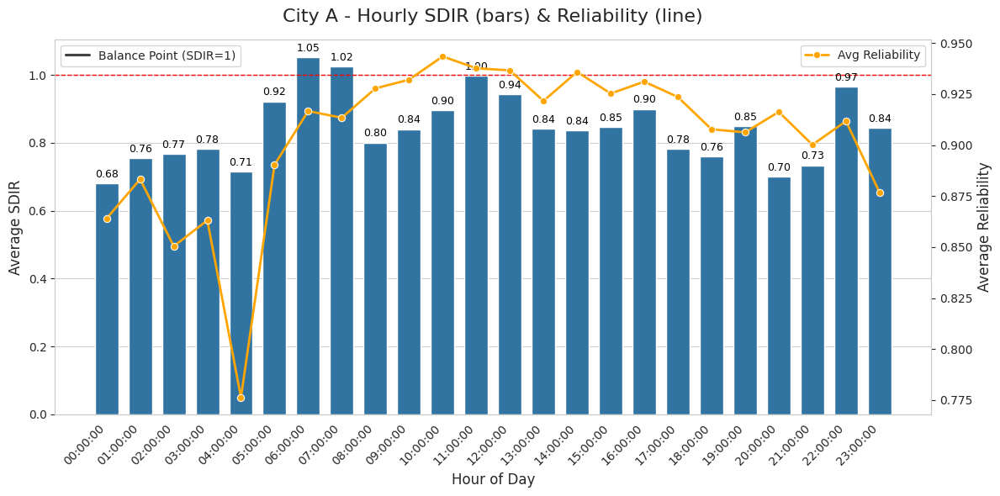

<ipython-input-191-4a9ac078d375>:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


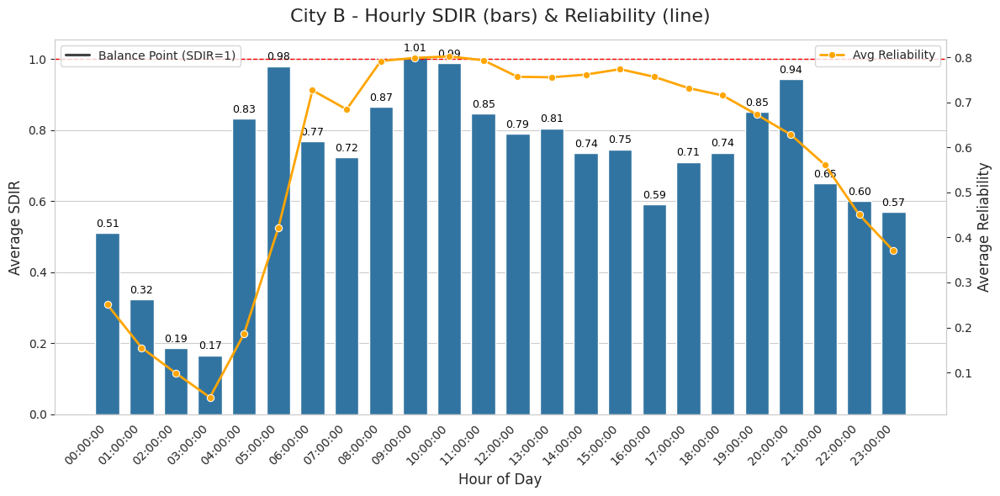

<ipython-input-191-4a9ac078d375>:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


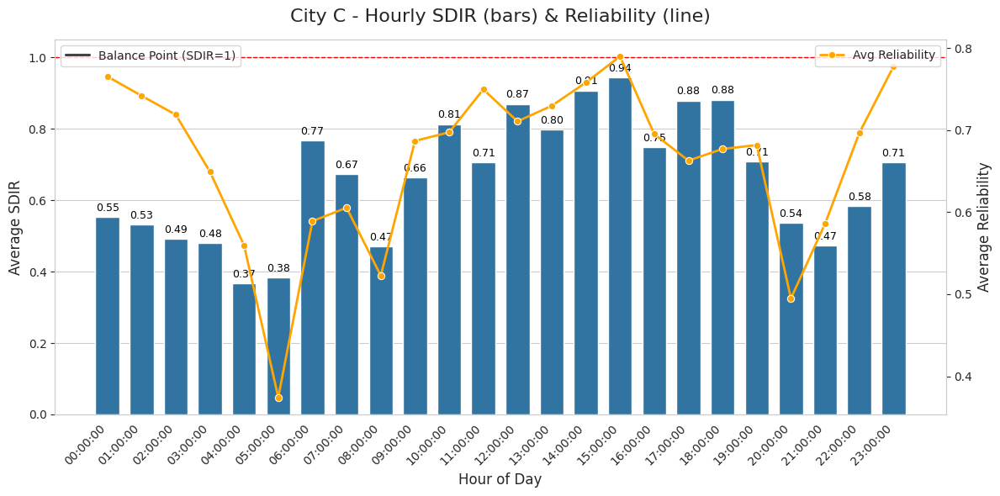

In [191]:
import matplotlib.pyplot as plt
import seaborn as sns

cities = ['A', 'B', 'C']

for city in cities:
    plt.figure(figsize=(12, 6))
    city_data = reliability_sdir_by_hour_city[reliability_sdir_by_hour_city['city'] == city]

    # Bar plot for avg_sdir
    ax = sns.barplot(
        data=city_data,
        x='hour',
        y='avg_sdir',
        color='#1f77b4',
        width=0.7
    )

    # Line plot for avg_reliability — on the same axes
    ax2 = ax.twinx()  # Create secondary y-axis for reliability
    sns.lineplot(
        data=city_data,
        x='hour',
        y='avg_reliability',
        color='orange',
        marker='o',
        linewidth=2,
        ax=ax2
    )

    ax2.grid(False)


    # Customize axes labels and title
    ax.set_title(f'City {city} - Hourly SDIR (bars) & Reliability (line)', fontsize=16, pad=15)
    ax.set_xlabel('Hour of Day', fontsize=12)
    ax.set_ylabel('Average SDIR', fontsize=12)
    ax2.set_ylabel('Average Reliability', fontsize=12)

    # Add horizontal line at SDIR=1 on primary y-axis
    ax.axhline(1, color='red', linestyle='--', linewidth=1, label='Balance Point')

    # Add value labels above bars
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(
            f"{height:.2f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=9,
            color='black',
            xytext=(0, 3),
            textcoords='offset points'
        )

    # Legends and layout
    ax.legend(['Balance Point (SDIR=1)'], loc='upper left')
    ax2.legend(['Avg Reliability'], loc='upper right')
    # Set rotated x-tick labels on ax (primary axis)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


    plt.tight_layout()
    plt.show()


<ipython-input-192-14064e31e8a6>:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
<ipython-input-192-14064e31e8a6>:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
<ipython-input-192-14064e31e8a6>:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


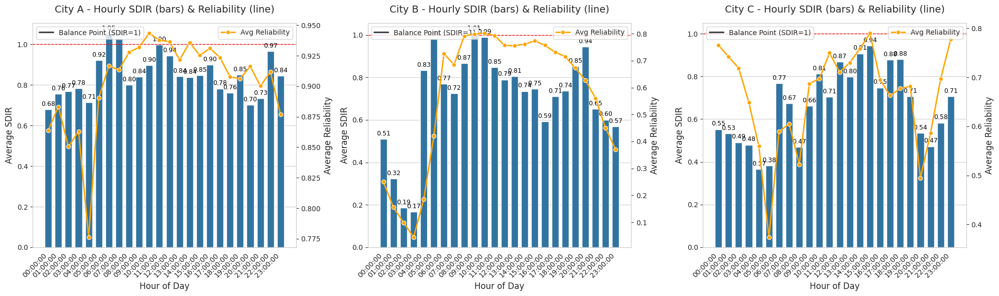

In [192]:
import matplotlib.pyplot as plt
import seaborn as sns

cities = ['A', 'B', 'C']

# Create a figure with 1 row and 3 columns
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, city in enumerate(cities):
    city_data = reliability_sdir_by_hour_city[reliability_sdir_by_hour_city['city'] == city]

    # Bar plot for avg_sdir on primary axis
    ax = sns.barplot(
        data=city_data,
        x='hour',
        y='avg_sdir',
        color='#1f77b4',
        width=0.7,
        ax=axes[i]
    )

    # Line plot for avg_reliability on secondary axis
    ax2 = ax.twinx()
    sns.lineplot(
        data=city_data,
        x='hour',
        y='avg_reliability',
        color='orange',
        marker='o',
        linewidth=2,
        ax=ax2
    )

    ax2.grid(False)

    # Customize each subplot
    ax.set_title(f'City {city} - Hourly SDIR (bars) & Reliability (line)', fontsize=14, pad=15)
    ax.set_xlabel('Hour of Day', fontsize=12)
    ax.set_ylabel('Average SDIR', fontsize=12)
    ax2.set_ylabel('Average Reliability', fontsize=12)

    # Add horizontal line at SDIR=1
    ax.axhline(1, color='red', linestyle='--', linewidth=1, label='Balance Point')

    # Add value labels above bars
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(
            f"{height:.2f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=9,
            color='black',
            xytext=(0, 3),
            textcoords='offset points'
        )

    # Legends
    ax.legend(['Balance Point (SDIR=1)'], loc='upper left')
    ax2.legend(['Avg Reliability'], loc='upper right')

    # Rotate x-tick labels
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [193]:
# Filter only completed requests
completed_requests = requested_rides_supply[requested_rides_supply['request_status'] == 'completed']



# Group by city, hour, and driver to count completed trips and average distance
result = completed_requests.groupby(['city', 'hour', 'driver_id']).agg(
    completed_requests_count=('request_id', 'count'),
    avg_trip_distance=('est_rider_fare_distance_miles', 'mean'),
    avg_surge_multiplier=('request_surge_multiplier', 'mean')
).reset_index()

result


# Final aggregation by city and hour
final_stats = result.groupby(['city', 'hour']).agg(
    completed_requests_per_driver=('completed_requests_count', 'mean'),
    avg_distance=('avg_trip_distance', 'mean'),
    avg_surge_multiplier=('avg_surge_multiplier', 'mean')
).reset_index()

# Sort the results
final_stats = final_stats.sort_values(['city', 'hour'])

final_stats

,city,hour,completed_requests_per_driver,avg_distance,avg_surge_multiplier
0,A,00:00:00,7.566667,4.138502,1.152423
1,A,01:00:00,6.280000,5.555858,1.018647
2,A,02:00:00,6.194030,4.508462,1.004835
3,A,03:00:00,5.517857,5.825844,1.056796
4,A,04:00:00,5.490909,6.064317,1.058867
...,...,...,...,...,...
67,C,19:00:00,8.703125,4.344120,1.037708
68,C,20:00:00,9.255319,3.129976,1.176675
69,C,21:00:00,11.562500,3.038567,1.164635
70,C,22:00:00,9.824561,3.022007,1.121838


In [194]:

supply_realibility_ride_rate_hour = pd.merge(
    reliability_sdir_by_hour_city,
    final_stats,
    on=['city', 'hour'],
    how='inner',
    suffixes=('_ride', '_supply')
)

supply_realibility_ride_rate_hour




,city,hour,avg_sdir,avg_reliability,completed_requests_per_driver,avg_distance,avg_surge_multiplier
0,A,00:00:00,0.680304,0.863939,7.566667,4.138502,1.152423
1,A,01:00:00,0.755274,0.883263,6.280000,5.555858,1.018647
2,A,02:00:00,0.768443,0.850410,6.194030,4.508462,1.004835
3,A,03:00:00,0.782123,0.863128,5.517857,5.825844,1.056796
4,A,04:00:00,0.714653,0.776350,5.490909,6.064317,1.058867
...,...,...,...,...,...,...,...
67,C,19:00:00,0.707466,0.681763,8.703125,4.344120,1.037708
68,C,20:00:00,0.535836,0.494881,9.255319,3.129976,1.176675
69,C,21:00:00,0.473073,0.586061,11.562500,3.038567,1.164635
70,C,22:00:00,0.583333,0.696517,9.824561,3.022007,1.121838


In [195]:
supply_realibility_ride_rate_hour.describe()

,avg_sdir,avg_reliability,completed_requests_per_driver,avg_distance,avg_surge_multiplier
count,72.000000,72.000000,72.000000,72.000000,72.000000
mean,0.737683,0.712450,7.760065,4.335091,1.051939
std,0.189956,0.211281,2.317034,1.093771,0.055983
min,0.166667,0.044872,1.750000,2.619654,1.000000
25%,0.659695,0.659467,6.775465,3.689817,1.016075
50%,0.767885,0.756021,7.992857,4.153531,1.038051
75%,0.855586,0.885041,9.312558,4.656785,1.061030
max,1.052381,0.943435,11.786585,8.194889,1.327544


<ipython-input-196-2b7805b39307>:109: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


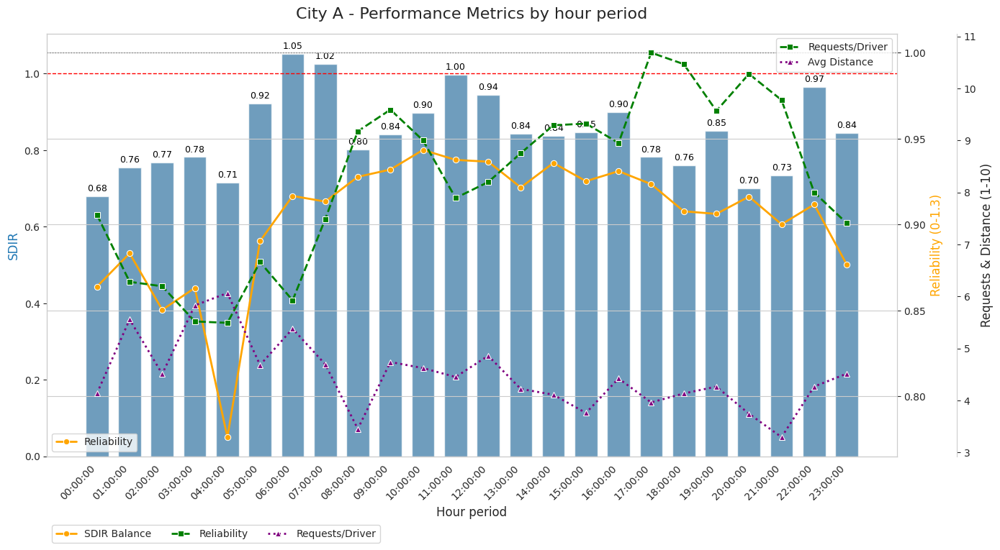

<ipython-input-196-2b7805b39307>:109: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


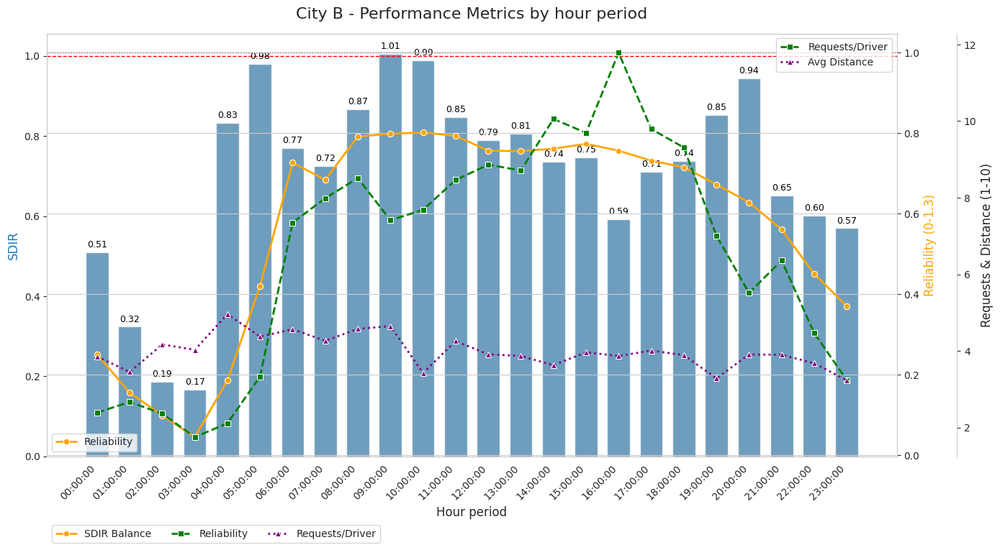

<ipython-input-196-2b7805b39307>:109: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


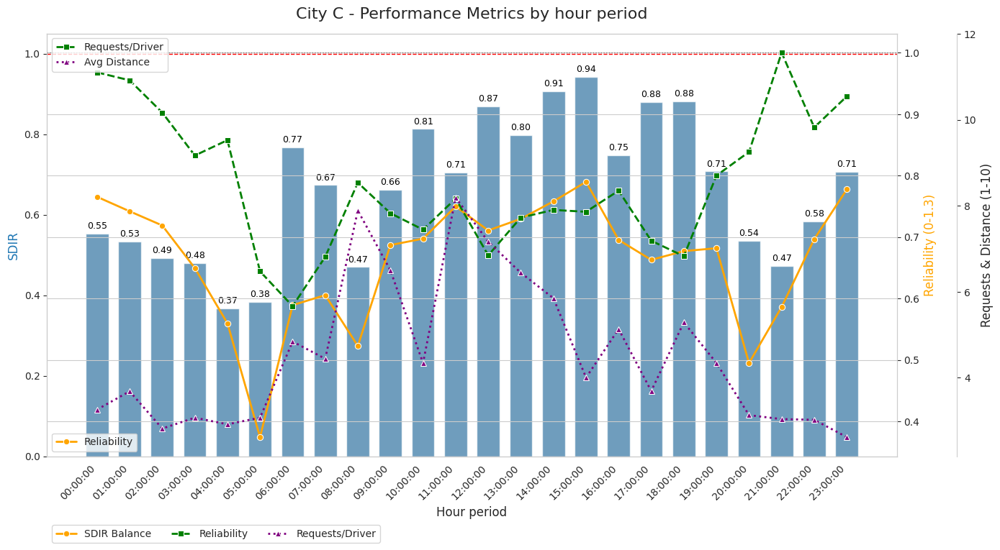

In [196]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MultipleLocator

cities = ['A', 'B', 'C']


for city in cities:
    plt.figure(figsize=(14, 8))
    city_data = supply_realibility_ride_rate_hour[supply_realibility_ride_rate_hour['city'] == city]


    # Create main axis for SDIR bars
    ax = sns.barplot(
        data=city_data,
        x='hour',
        y='avg_sdir',
        color='#1f77b4',
        width=0.7,
        alpha=0.7
    )

    # Create secondary axis for reliability (0-1.3 scale)
    ax2 = ax.twinx()

    # Create tertiary axis for requests/distance (1-10 scale)
    ax3 = ax.twinx()
    ax3.spines['right'].set_position(('outward', 60))  # Offset third axis

    # Plot metrics
    sns.lineplot(
        data=city_data,
        x='hour',
        y='avg_reliability',
        color='orange',
        marker='o',
        linewidth=2,
        ax=ax2,
        label='Reliability'
    )

    sns.lineplot(
        data=city_data,
        x='hour',
        y='completed_requests_per_driver',
        color='green',
        marker='s',
        linestyle='--',
        linewidth=2,
        ax=ax3,
        label='Requests/Driver'
    )

    sns.lineplot(
        data=city_data,
        x='hour',
        y='avg_distance',
        color='purple',
        marker='^',
        linestyle=':',
        linewidth=2,
        ax=ax3,
        label='Avg Distance'
    )

    # Customize axes
    ax.set_title(f'City {city} - Performance Metrics by hour period', fontsize=16, pad=15)
    ax.set_xlabel('Hour period', fontsize=12)
    ax.set_ylabel('SDIR', color='#1f77b4', fontsize=12)
    ax2.set_ylabel('Reliability (0-1.3)', color='orange', fontsize=12)
    ax3.set_ylabel('Requests & Distance (1-10)', fontsize=12)

    ax.grid(False)
    ax3.grid(False)

    # Set axis limits

    # ax.set_ylim(0.1, 1.1)
    # ax2.set_ylim(0, 0.95)
    # ax3.set_ylim(1.5, 12)

    # Add reference lines
    ax.axhline(1, color='red', linestyle='--', linewidth=1)
    ax2.axhline(1, color='gray', linestyle=':', linewidth=1)

    # Add bar value labels
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.2f}",
            (p.get_x() + p.get_width()/2., p.get_height()),
            ha='center', va='bottom',
            fontsize=9, color='black',
            xytext=(0, 3), textcoords='offset points'
        )

    # Add all legends
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()
    ax.legend(
        lines1 + lines2 + lines3,
        ['SDIR Balance'] + labels2 + labels3,
        loc='upper left',
        bbox_to_anchor=(0, -0.15),
        ncol=4
    )

    # Rotate x-ticks
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.2)  # Make room for legend
    plt.show()

<ipython-input-197-8ecc6a46a9c5>:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


<Figure size 1800x800 with 0 Axes>

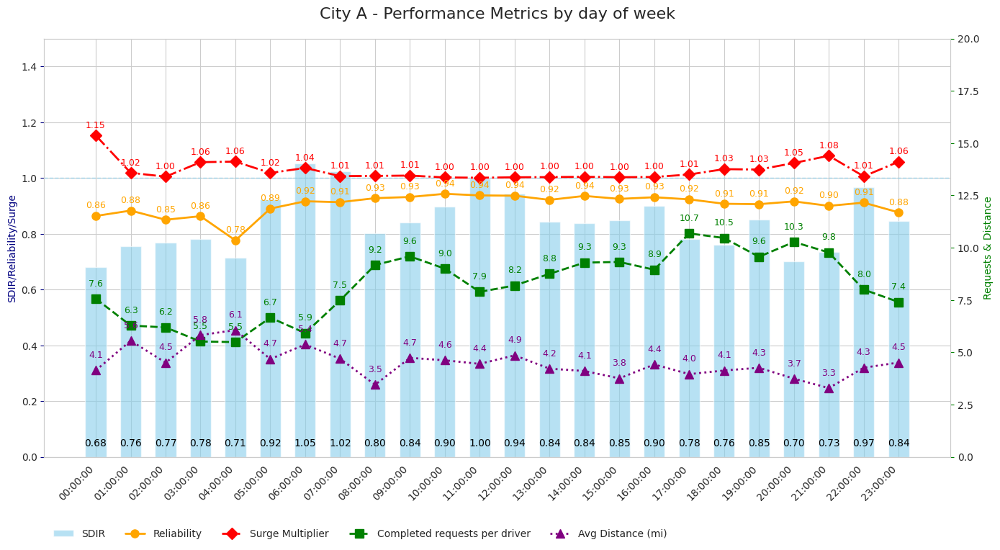

<ipython-input-197-8ecc6a46a9c5>:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


<Figure size 1800x800 with 0 Axes>

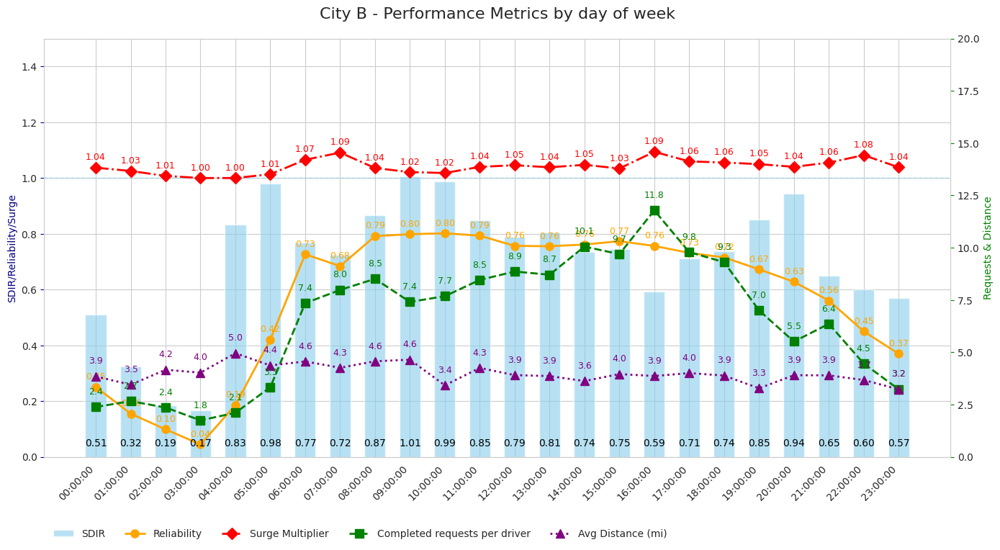

<ipython-input-197-8ecc6a46a9c5>:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


<Figure size 1800x800 with 0 Axes>

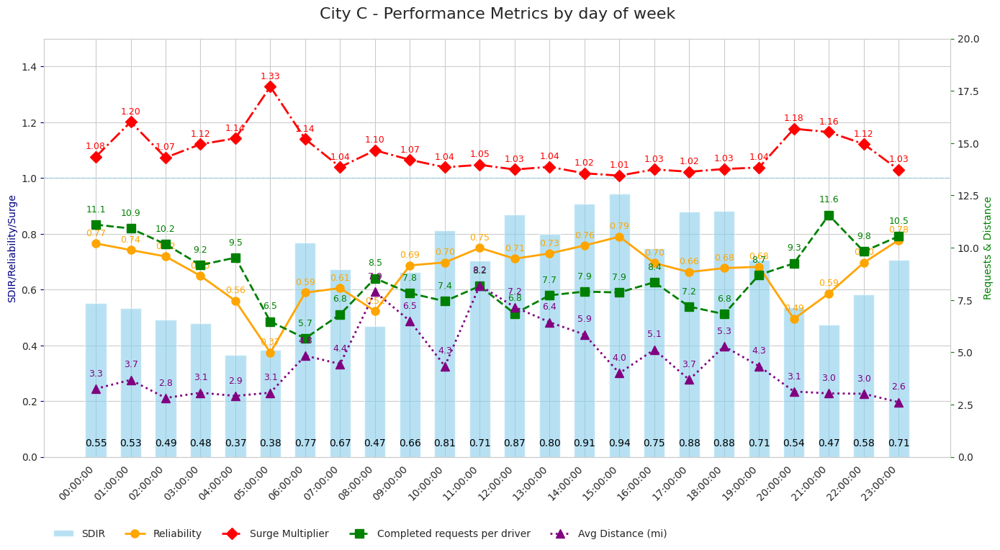

In [197]:
import matplotlib.pyplot as plt
import seaborn as sns

cities = ['A', 'B', 'C']

for city in cities:
    city_data = supply_realibility_ride_rate_hour[supply_realibility_ride_rate_hour['city'] == city]

    # Set style
    sns.set_style("whitegrid")
    plt.figure(figsize=(18, 8))

    # Create plot with primary y-axis (0-1.5 range)
    fig, ax1 = plt.subplots(figsize=(14, 8))

    # Plot SDIR (bars) - Primary axis
    bars = ax1.bar(city_data['hour'], city_data['avg_sdir'], color='skyblue', alpha=0.6, width=0.6, label='SDIR')
    ax1.set_ylabel('SDIR/Reliability/Surge', color='navy')
    ax1.tick_params(axis='y', color='navy')
    ax1.set_ylim(0, 1.5)


    # Add reference line for SDIR balance
    ax1.axhline(1.0, color='skyblue', linestyle='--', linewidth=1, alpha=0.7)

    # Plot Reliability (line) - Same axis
    rel_line = ax1.plot(city_data['hour'], city_data['avg_reliability'], 'o-', color='orange',
                   linewidth=2, markersize=8, label='Reliability')

    # Add value labels for Reliability points
    for x, y in zip(city_data['hour'], city_data['avg_reliability']):
        ax1.text(x, y + 0.02, f'{y:.2f}', color='orange', ha='center', va='bottom', fontsize=9)

    # Plot Surge (line) - Same axis
    surge_line = ax1.plot(city_data['hour'], city_data['avg_surge_multiplier'], 'D-.', color='red',
                     linewidth=2, markersize=8, label='Surge Multiplier')

    # Add value labels for Surge points
    for x, y in zip(city_data['hour'], city_data['avg_surge_multiplier']):
        ax1.text(x, y + 0.02, f'{y:.2f}', color='red', ha='center', va='bottom', fontsize=9)

    # Create secondary y-axis (1-10 range)
    ax2 = ax1.twinx()
    req_line = ax2.plot(city_data['hour'], city_data['completed_requests_per_driver'], 's--', color='green',
                   linewidth=2, markersize=8, label='Completed requests per driver')

    # Add value labels for Requests points
    for x, y in zip(city_data['hour'], city_data['completed_requests_per_driver']):
        ax2.text(x, y + 0.5, f'{y:.1f}', color='green', ha='center', va='bottom', fontsize=9)

    dist_line = ax2.plot(city_data['hour'], city_data['avg_distance'], '^:', color='purple',
                    linewidth=2, markersize=8, label='Avg Distance (mi)')

    # Add value labels for Distance points
    for x, y in zip(city_data['hour'], city_data['avg_distance']):
        ax2.text(x, y + 0.5, f'{y:.1f}', color='purple', ha='center', va='bottom', fontsize=9)

    ax2.set_ylabel('Requests & Distance', color='green')
    ax2.tick_params(axis='y', color='green')
    ax2.set_ylim(0, 20)
    ax2.grid(False)

    # Combine all legends
    lines = [bars] + rel_line + surge_line + req_line + dist_line
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left',
          bbox_to_anchor=(0, -0.15), ncol=5, frameon=False)

    # Add value labels on SDIR bars
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., 0.03,
                f'{height:.2f}',
                ha='center', va='bottom',
                fontsize=10, color='black')

    ax1.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

    # Title and layout
    plt.title(f'City {city} - Performance Metrics by day of week', pad=20, fontsize=16)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.2)
    plt.show()

In [198]:
requested_rides_supply

,rider_session_id,session_start_timestamp_local,rider_id,city,app_version,duration_ms,session_last_eta,session_last_surge_multiplier,session_last_fare_local,session_average_trip_distance_miles,...,is_matched,is_reliable_pickup,reliability_status,active_drivers,requests,SDIR,supply_state,hour,day_of_week,day_name
0,00038-50b1-4019-ace3-8bd1f6fdf16f94f,2023-04-18 14:18:22,e6ad1-2232-4382-8270-60d10d3becb21e6,A,3.557.10000,3047613.0,1.0,1.0,7.55,5.057579,...,True,True,Reliable,93.0,84.0,1.107143,over-supply,14:00:00,1,Tuesday
1,0003d-554e-4b66-a8bd-66e33cd8aee3989,2023-04-08 15:15:52,bdcb8-6330-4416-a461-4e32613e01063c7,A,4.467.10008,1583748.0,1.0,1.0,10.42,5.545788,...,True,True,Reliable,95.0,112.0,0.848214,under-supply,15:00:00,5,Saturday
2,00046-48ed-4fe4-8f40-fdf3959f6803fe1,2023-04-05 14:29:05,d480f-be2f-416f-8003-03bb0d1f340aafe,A,3.555.10002,1531628.0,1.0,1.0,5.97,4.390179,...,True,True,Reliable,93.0,107.0,0.869159,under-supply,14:00:00,2,Wednesday
3,0004d-bc91-4496-b54e-f98f346e4fb994b,2023-04-20 07:52:51,83274-0d00-4bf8-b170-cddb8eaed2ca8fe,A,4.469.10002,1275991.0,7.0,1.0,7.61,3.872201,...,True,True,Reliable,40.0,36.0,1.111111,over-supply,07:00:00,3,Thursday
4,0004e-93bf-45b4-bf41-ea5ee38419ea48d,2023-04-08 16:52:56,1da1c-2373-4bfa-af37-d322a0c1033f131,C,3.556.10002,1166481.0,7.0,1.0,12.60,1.806553,...,True,True,Reliable,28.0,73.0,0.383562,under-supply,16:00:00,5,Saturday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82619,ffff8-dc01-4ac9-bedc-aa04464101d01a6,2023-04-02 02:26:22,77110-c8ed-43d8-dc20-e324102203747fb,B,4.467.10004,2508345.0,8.0,1.0,202.00,16.470834,...,True,False,Unreliable,9.0,59.0,0.152542,under-supply,02:00:00,6,Sunday
82620,ffffa-8a80-43f3-8019-fd68f4f6af546bf,2023-04-04 16:40:53,61b36-2ae0-43d3-ddde-14fddda6d476034,B,3.555.10002,1011442.0,3.0,1.1,53.00,1.687286,...,True,True,Reliable,84.0,125.0,0.672000,under-supply,16:00:00,1,Tuesday
82621,ffffc-b0f8-4e8b-af09-9da386cab0d80bf,2023-04-04 15:21:09,f23bb-8bdd-483c-a603-8d3380300b468b7,B,3.555.10002,2017502.0,6.0,1.0,68.00,4.838207,...,True,True,Reliable,85.0,105.0,0.809524,under-supply,15:00:00,1,Tuesday
82622,fffff-160f-49ec-9f0f-b466648fe049a88,2023-04-01 09:32:44,ebf2a-dcb1-44c0-b234-b1671d3271edddf,A,4.467.10003,1849259.0,2.0,1.0,6.39,3.086754,...,True,True,Reliable,53.0,92.0,0.576087,under-supply,09:00:00,5,Saturday


In [199]:
reliability_sdir_by_weekday_city = requested_rides_supply.groupby(['city', 'day_of_week', 'day_name']).agg(
    avg_sdir=('SDIR', 'mean'),
    avg_reliability=('is_reliable_pickup', 'mean')
).reset_index()

reliability_sdir_by_weekday_city

,city,day_of_week,day_name,avg_sdir,avg_reliability
0,A,0,Monday,0.910985,0.926557
1,A,1,Tuesday,0.950976,0.934211
2,A,2,Wednesday,0.990322,0.928677
3,A,3,Thursday,0.974431,0.924904
4,A,4,Friday,0.647272,0.897877
5,A,5,Saturday,0.772185,0.911961
6,A,6,Sunday,0.738900,0.897062
7,B,0,Monday,0.809190,0.739423
8,B,1,Tuesday,0.810466,0.750376
9,B,2,Wednesday,0.814258,0.743957


<ipython-input-200-2067ead33e05>:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


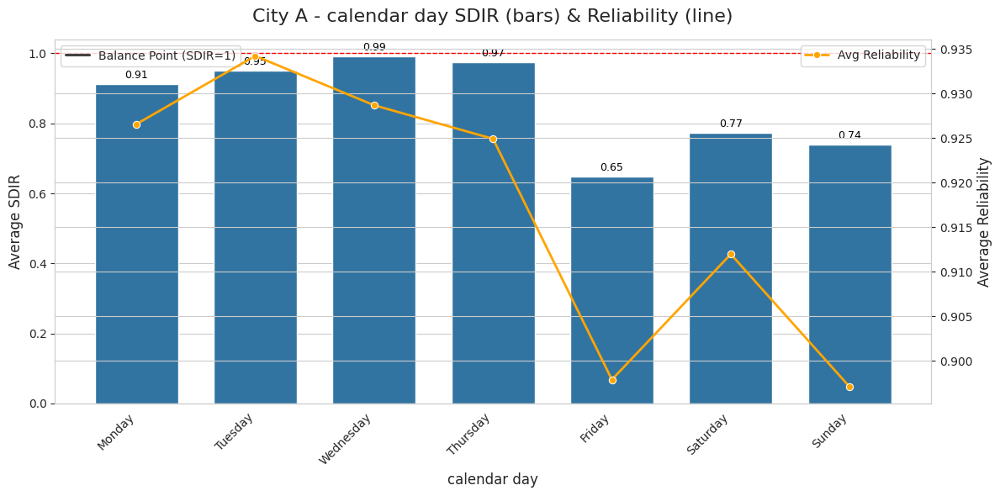

<ipython-input-200-2067ead33e05>:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


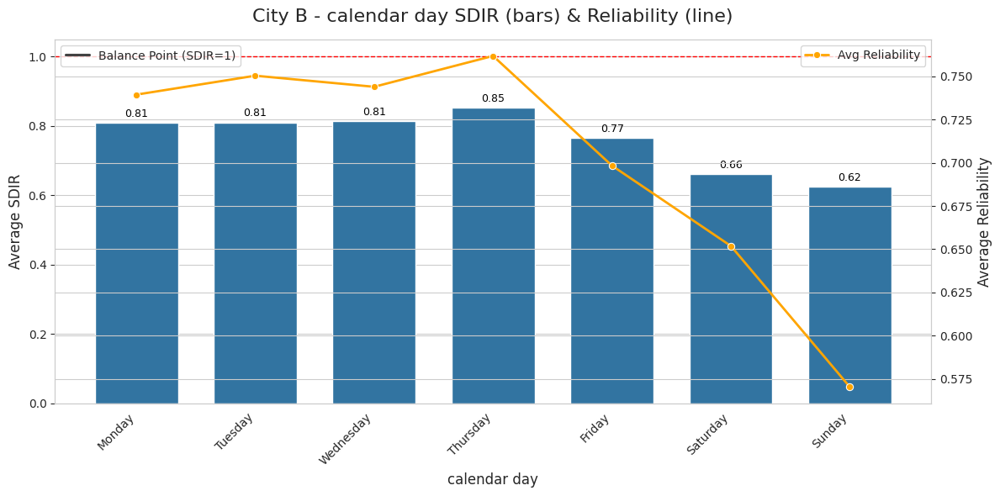

<ipython-input-200-2067ead33e05>:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


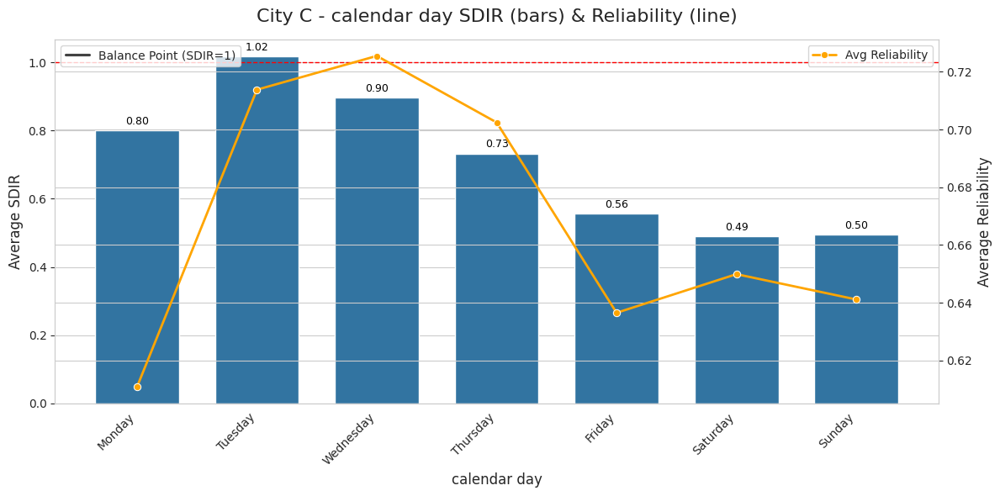

In [200]:
import matplotlib.pyplot as plt
import seaborn as sns

cities = ['A', 'B', 'C']

for city in cities:
    plt.figure(figsize=(12, 6))
    city_data = reliability_sdir_by_weekday_city[reliability_sdir_by_weekday_city['city'] == city]

    # Bar plot for avg_sdir
    ax = sns.barplot(
        data=city_data,
        x='day_name',
        y='avg_sdir',
        color='#1f77b4',
        width=0.7
    )

    # Line plot for avg_reliability — on the same axes
    ax2 = ax.twinx()  # Create secondary y-axis for reliability
    sns.lineplot(
        data=city_data,
        x='day_name',
        y='avg_reliability',
        color='orange',
        marker='o',
        linewidth=2,
        ax=ax2
    )

    # Customize axes labels and title
    ax.set_title(f'City {city} - calendar day SDIR (bars) & Reliability (line)', fontsize=16, pad=15)
    ax.set_xlabel('calendar day', fontsize=12)
    ax.set_ylabel('Average SDIR', fontsize=12)
    ax2.set_ylabel('Average Reliability', fontsize=12)

    # Add horizontal line at SDIR=1 on primary y-axis
    ax.axhline(1, color='red', linestyle='--', linewidth=1, label='Balance Point')

    # Add value labels above bars
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(
            f"{height:.2f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=9,
            color='black',
            xytext=(0, 3),
            textcoords='offset points'
        )

    # Legends and layout
    ax.legend(['Balance Point (SDIR=1)'], loc='upper left')
    ax2.legend(['Avg Reliability'], loc='upper right')
    # Set rotated x-tick labels on ax (primary axis)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


    plt.tight_layout()
    plt.show()

<ipython-input-201-8f62fc5328e9>:67: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
<ipython-input-201-8f62fc5328e9>:67: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
<ipython-input-201-8f62fc5328e9>:67: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


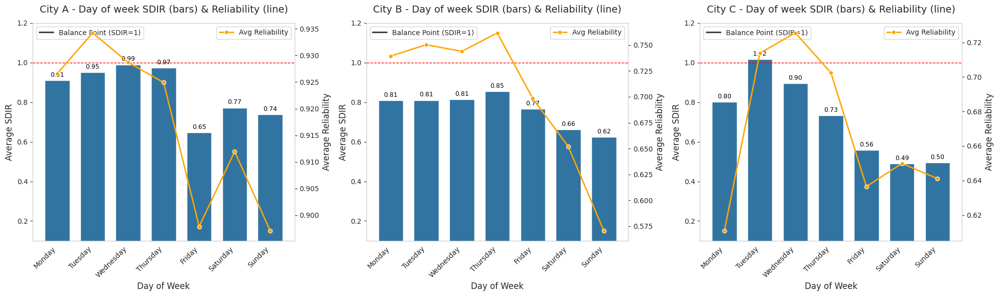

In [201]:
import matplotlib.pyplot as plt
import seaborn as sns

cities = ['A', 'B', 'C']

# Create a figure with 1 row and 3 columns
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, city in enumerate(cities):
    city_data = reliability_sdir_by_weekday_city[reliability_sdir_by_weekday_city['city'] == city]

    # Bar plot for avg_sdir on primary axis
    ax = sns.barplot(
        data=city_data,
        x='day_name',
        y='avg_sdir',
        color='#1f77b4',
        width=0.7,
        ax=axes[i]
    )

    # Line plot for avg_reliability on secondary axis
    ax2 = ax.twinx()
    sns.lineplot(
        data=city_data,
        x='day_name',
        y='avg_reliability',
        color='orange',
        marker='o',
        linewidth=2,
        ax=ax2
    )
    ax.grid(False)
    ax2.grid(False)

    ax.set_ylim(0.1, 1.2)
    # ax.set_ylim(0.1, 1.1)

    # Customize each subplot
    ax.set_title(f'City {city} - Day of week SDIR (bars) & Reliability (line)', fontsize=14, pad=15)
    ax.set_xlabel('Day of Week', fontsize=12)
    ax.set_ylabel('Average SDIR', fontsize=12)
    ax2.set_ylabel('Average Reliability', fontsize=12)

    # Add horizontal line at SDIR=1
    ax.axhline(1, color='red', linestyle='--', linewidth=1, label='Balance Point')

    # Add value labels above bars
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(
            f"{height:.2f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=9,
            color='black',
            xytext=(0, 3),
            textcoords='offset points'
        )

    # Legends
    ax.legend(['Balance Point (SDIR=1)'], loc='upper left')
    ax2.legend(['Avg Reliability'], loc='upper right')

    # Rotate x-tick labels
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [202]:
requested_rides_supply.columns

Index(['rider_session_id', 'session_start_timestamp_local', 'rider_id', 'city',
       'app_version', 'duration_ms', 'session_last_eta',
       'session_last_surge_multiplier', 'session_last_fare_local',
       'session_average_trip_distance_miles', 'pickup_geo', 'dropoff_geo',
       'request_id', 'request_timestamp_local', 'request_status',
       'request_client_fare_local', 'request_surge_multiplier',
       'request_rider_device', 'driver_id', 'post_dispatch_eta', 'ata',
       'request_product_name', 'is_airport_trip', 'is_business_trip',
       'is_cash_trip', 'is_scheduled_trip', 'is_multidestination',
       'est_rider_fare_distance_miles', 'trip_distance_miles',
       'trip_duration_seconds', 'cancellation_fee_local', 'hour_bin',
       'is_matched', 'is_reliable_pickup', 'reliability_status',
       'active_drivers', 'requests', 'SDIR', 'supply_state', 'hour',
       'day_of_week', 'day_name'],
      dtype='object')

In [203]:
# Filter only completed requests
completed_requests = requested_rides_supply[requested_rides_supply['request_status'] == 'completed']



# Group by city, hour, and driver to count completed trips and average distance
result = completed_requests.groupby(['city', 'day_of_week','day_name', 'driver_id']).agg(
    completed_requests_count=('request_id', 'count'),
    avg_trip_distance=('est_rider_fare_distance_miles', 'mean'),
    avg_surge_multiplier=('request_surge_multiplier', 'mean')
).reset_index()

result


# Final aggregation by city and hour
final_stats = result.groupby(['city',  'day_of_week','day_name']).agg(
    completed_requests_per_driver=('completed_requests_count', 'mean'),
    avg_distance=('avg_trip_distance', 'mean'),
    avg_surge_multiplier=('avg_surge_multiplier', 'mean')
).reset_index()

# Sort the results
final_stats = final_stats.sort_values(['city',  'day_of_week','day_name'])

final_stats

,city,day_of_week,day_name,completed_requests_per_driver,avg_distance,avg_surge_multiplier
0,A,0,Monday,18.736170,5.640803,1.003600
1,A,1,Tuesday,18.115226,5.241923,1.006045
2,A,2,Wednesday,18.391667,3.863423,1.001599
3,A,3,Thursday,19.062241,5.145227,1.002822
4,A,4,Friday,27.611570,4.233619,1.064782
5,A,5,Saturday,21.138211,6.436538,1.036597
6,A,6,Sunday,18.888372,5.181315,1.015940
7,B,0,Monday,17.711409,3.901525,1.043460
8,B,1,Tuesday,17.946108,4.329067,1.040523
9,B,2,Wednesday,18.617284,4.236268,1.043462


In [204]:

supply_realibility_ride_rate_day = pd.merge(
    reliability_sdir_by_weekday_city,
    final_stats,
    on=['city', 'day_name', 'day_of_week'],
    how='inner',
    suffixes=('_ride', '_supply')
)

supply_realibility_ride_rate_day


,city,day_of_week,day_name,avg_sdir,avg_reliability,completed_requests_per_driver,avg_distance,avg_surge_multiplier
0,A,0,Monday,0.910985,0.926557,18.736170,5.640803,1.003600
1,A,1,Tuesday,0.950976,0.934211,18.115226,5.241923,1.006045
2,A,2,Wednesday,0.990322,0.928677,18.391667,3.863423,1.001599
3,A,3,Thursday,0.974431,0.924904,19.062241,5.145227,1.002822
4,A,4,Friday,0.647272,0.897877,27.611570,4.233619,1.064782
5,A,5,Saturday,0.772185,0.911961,21.138211,6.436538,1.036597
6,A,6,Sunday,0.738900,0.897062,18.888372,5.181315,1.015940
7,B,0,Monday,0.809190,0.739423,17.711409,3.901525,1.043460
8,B,1,Tuesday,0.810466,0.750376,17.946108,4.329067,1.040523
9,B,2,Wednesday,0.814258,0.743957,18.617284,4.236268,1.043462


<ipython-input-205-6ad794439228>:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


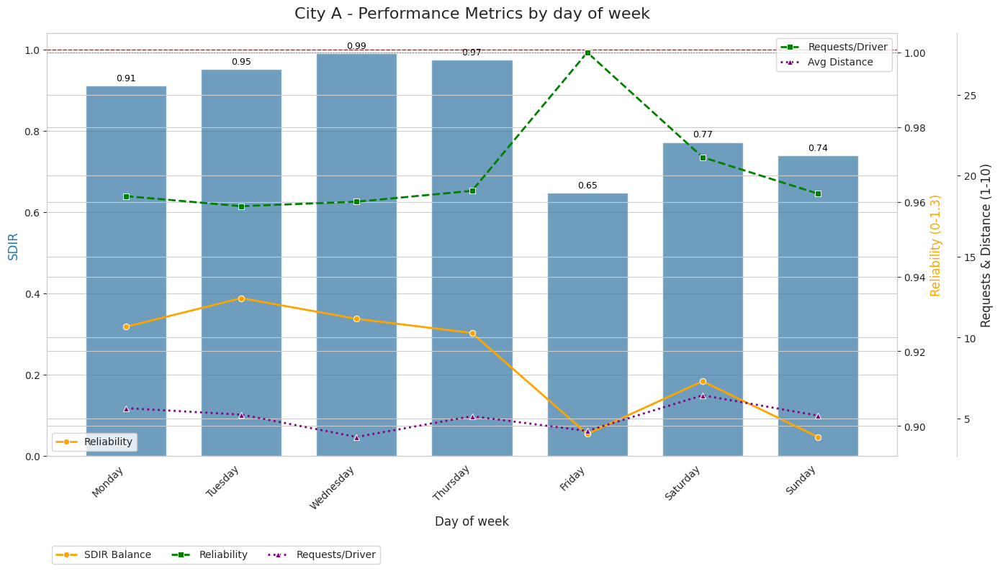

<ipython-input-205-6ad794439228>:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


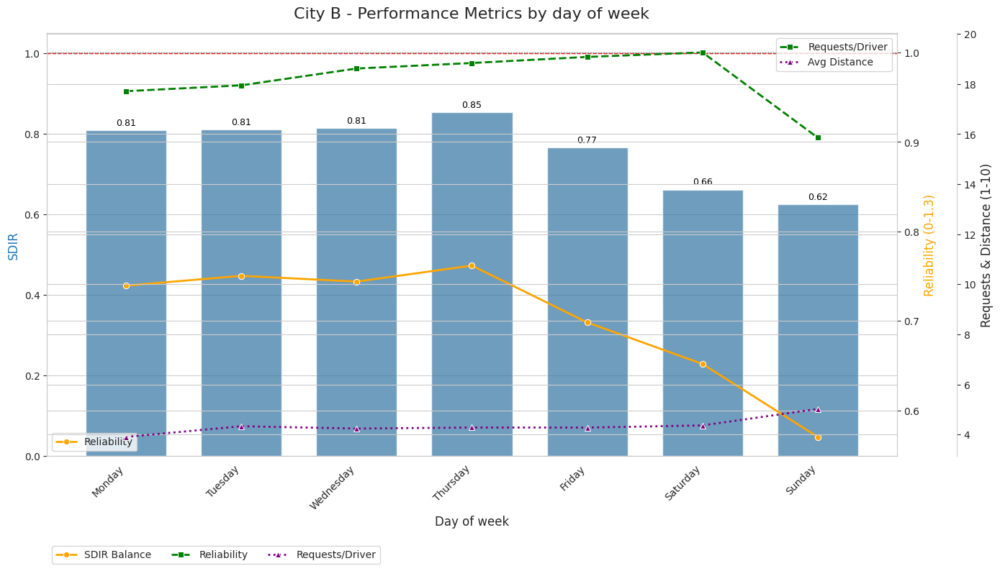

<ipython-input-205-6ad794439228>:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


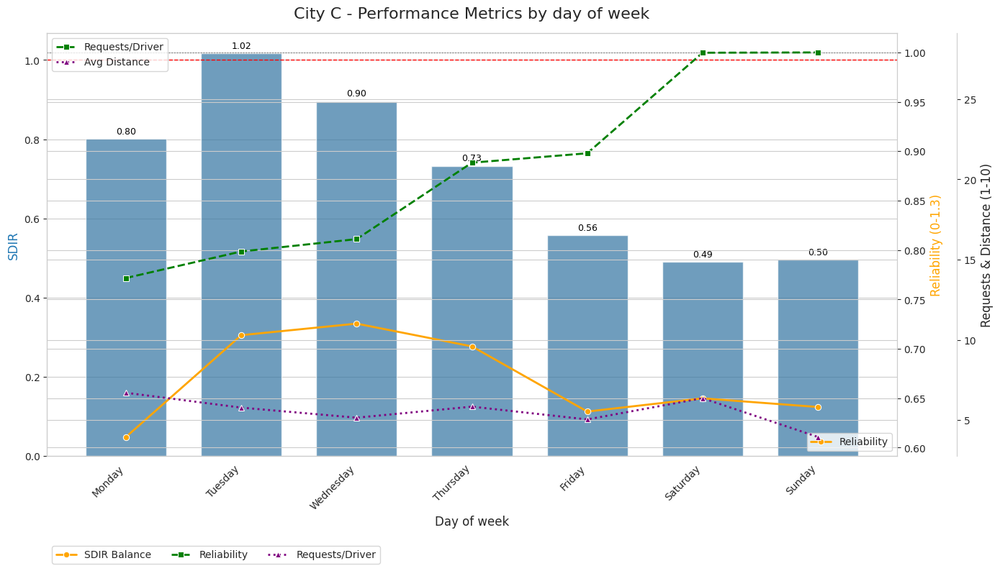

In [205]:
cities = ['A', 'B', 'C']


for city in cities:
    plt.figure(figsize=(14, 8))
    city_data = supply_realibility_ride_rate_day[supply_realibility_ride_rate_day['city'] == city]


    # Create main axis for SDIR bars
    ax = sns.barplot(
        data=city_data,
        x='day_name',
        y='avg_sdir',
        color='#1f77b4',
        width=0.7,
        alpha=0.7
    )

    # Create secondary axis for reliability (0-1.3 scale)
    ax2 = ax.twinx()

    # Create tertiary axis for requests/distance (1-10 scale)
    ax3 = ax.twinx()
    ax3.spines['right'].set_position(('outward', 60))  # Offset third axis

    # Plot metrics
    sns.lineplot(
        data=city_data,
        x='day_name',
        y='avg_reliability',
        color='orange',
        marker='o',
        linewidth=2,
        ax=ax2,
        label='Reliability'
    )

    sns.lineplot(
        data=city_data,
        x='day_name',
        y='completed_requests_per_driver',
        color='green',
        marker='s',
        linestyle='--',
        linewidth=2,
        ax=ax3,
        label='Requests/Driver'
    )

    sns.lineplot(
        data=city_data,
        x='day_name',
        y='avg_distance',
        color='purple',
        marker='^',
        linestyle=':',
        linewidth=2,
        ax=ax3,
        label='Avg Distance'
    )

    # Customize axes
    ax.set_title(f'City {city} - Performance Metrics by day of week', fontsize=16, pad=15)
    ax.set_xlabel('Day of week', fontsize=12)
    ax.set_ylabel('SDIR', color='#1f77b4', fontsize=12)
    ax2.set_ylabel('Reliability (0-1.3)', color='orange', fontsize=12)
    ax3.set_ylabel('Requests & Distance (1-10)', fontsize=12)

    # Set axis limits
    #ax.set_ylim(0, 1.5)
    #ax2.set_ylim(0, 1.3)
    #ax3.set_ylim(1, 10)

    # Add reference lines
    ax.axhline(1, color='red', linestyle='--', linewidth=1)
    ax2.axhline(1, color='gray', linestyle=':', linewidth=1)

    # Add bar value labels
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.2f}",
            (p.get_x() + p.get_width()/2., p.get_height()),
            ha='center', va='bottom',
            fontsize=9, color='black',
            xytext=(0, 3), textcoords='offset points'
        )

    # Add all legends
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()
    ax.legend(
        lines1 + lines2 + lines3,
        ['SDIR Balance'] + labels2 + labels3,
        loc='upper left',
        bbox_to_anchor=(0, -0.2),
        ncol=4
    )

    # Rotate x-ticks
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.2)  # Make room for legend
    plt.show()

<Figure size 1400x800 with 0 Axes>

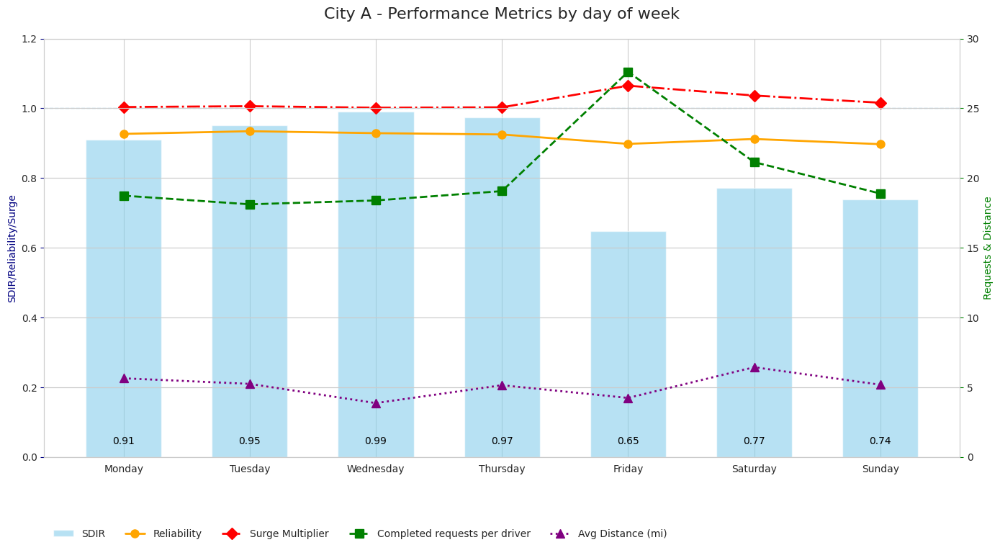

<Figure size 1400x800 with 0 Axes>

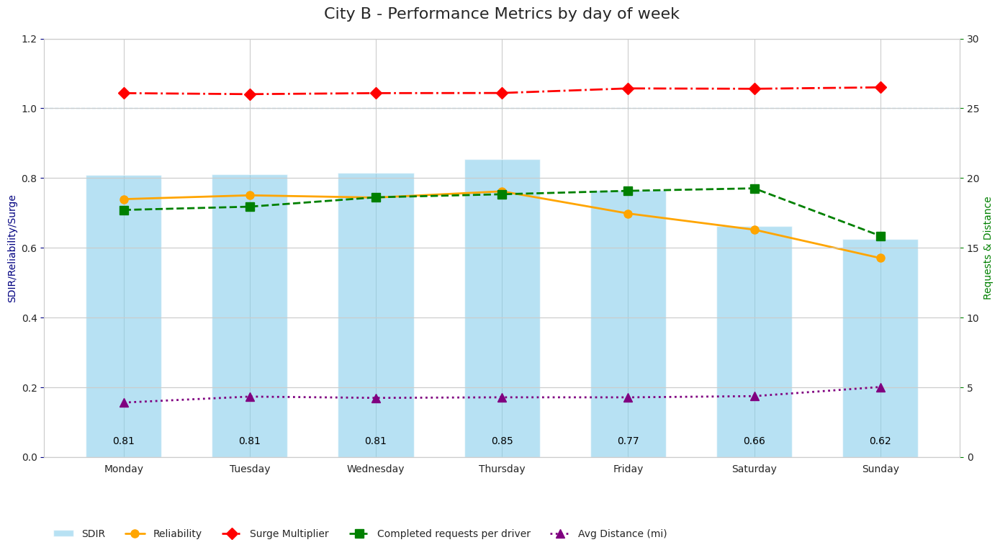

<Figure size 1400x800 with 0 Axes>

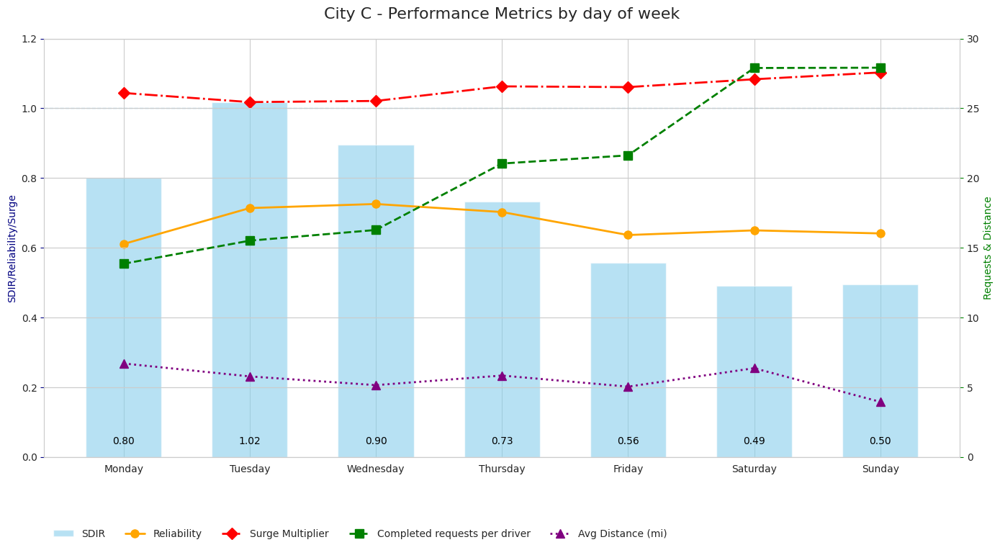

In [206]:
import matplotlib.pyplot as plt
import seaborn as sns


cities = ['A', 'B', 'C']


for city in cities:

    city_data = supply_realibility_ride_rate_day[supply_realibility_ride_rate_day['city'] == city]


    # Set style
    sns.set_style("whitegrid")
    plt.figure(figsize=(14, 8))


    # Create plot with primary y-axis (0-1.5 range)
    fig, ax1 = plt.subplots(figsize=(14, 8))

    # Plot SDIR (bars) - Primary axis
    bars = ax1.bar(city_data['day_name'], city_data['avg_sdir'], color='skyblue', alpha=0.6, width=0.6, label='SDIR')
    ax1.set_ylabel('SDIR/Reliability/Surge', color='navy')
    ax1.tick_params(axis='y', color='navy')
    ax1.set_ylim(0, 1.2)

    # Add reference line for SDIR balance
    ax1.axhline(1.0, color='skyblue', linestyle='--', linewidth=1, alpha=0.7)

    # Plot Reliability (line) - Same axis
    rel_line = ax1.plot(city_data['day_name'], city_data['avg_reliability'], 'o-', color='orange',
                   linewidth=2, markersize=8, label='Reliability')

    # Plot Surge (line) - Same axis
    surge_line = ax1.plot(city_data['day_name'], city_data['avg_surge_multiplier'], 'D-.', color='red',
                     linewidth=2, markersize=8, label='Surge Multiplier')

    # Create secondary y-axis (1-10 range)
    ax2 = ax1.twinx()
    req_line = ax2.plot(city_data['day_name'],city_data['completed_requests_per_driver'], 's--', color='green',
                   linewidth=2, markersize=8, label='Completed requests per driver')
    dist_line = ax2.plot(city_data['day_name'],city_data['avg_distance'], '^:', color='purple',
                    linewidth=2, markersize=8, label='Avg Distance (mi)')
    ax2.set_ylabel('Requests & Distance', color='green')
    ax2.tick_params(axis='y', color='green')
    ax2.set_ylim(0, 30)

    # Combine all legends
    lines = [bars] + rel_line + surge_line + req_line + dist_line
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left',
          bbox_to_anchor=(0, -0.15), ncol=5, frameon=False)

    # Add value labels on SDIR bars
    for bar in bars:
      height = bar.get_height()
      ax1.text(bar.get_x() + bar.get_width()/2., 0.03,
            f'{height:.2f}',
            ha='center', va='bottom',
            fontsize=10, color='black')

    # Title and layout
    plt.title(f'City {city} - Performance Metrics by day of week', pad=20, fontsize=16)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.2)
    plt.show()

<Figure size 1800x800 with 0 Axes>

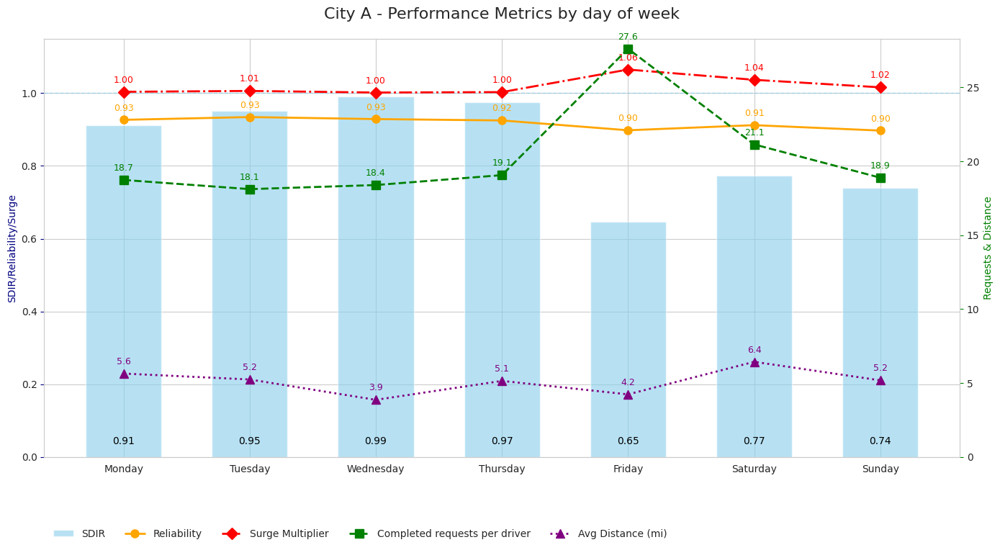

<Figure size 1800x800 with 0 Axes>

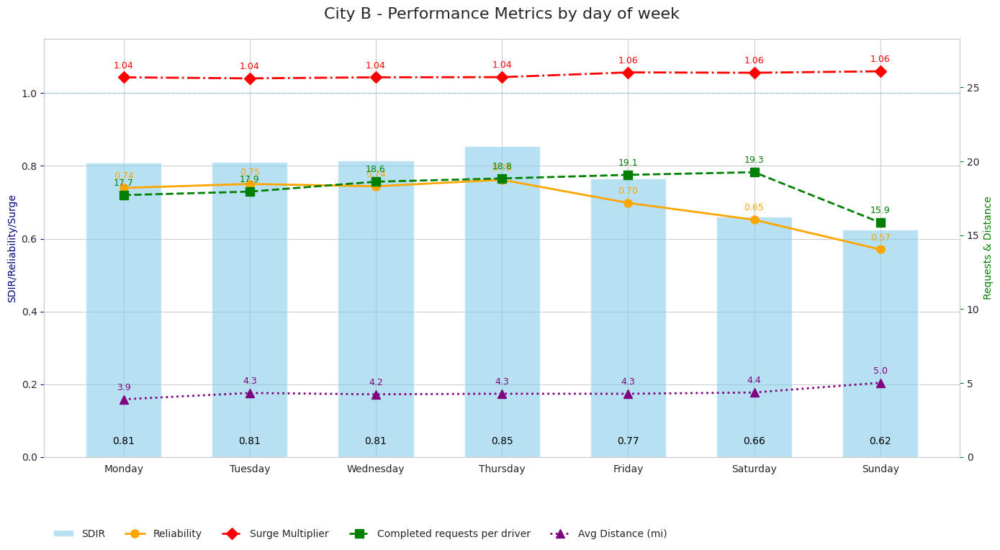

<Figure size 1800x800 with 0 Axes>

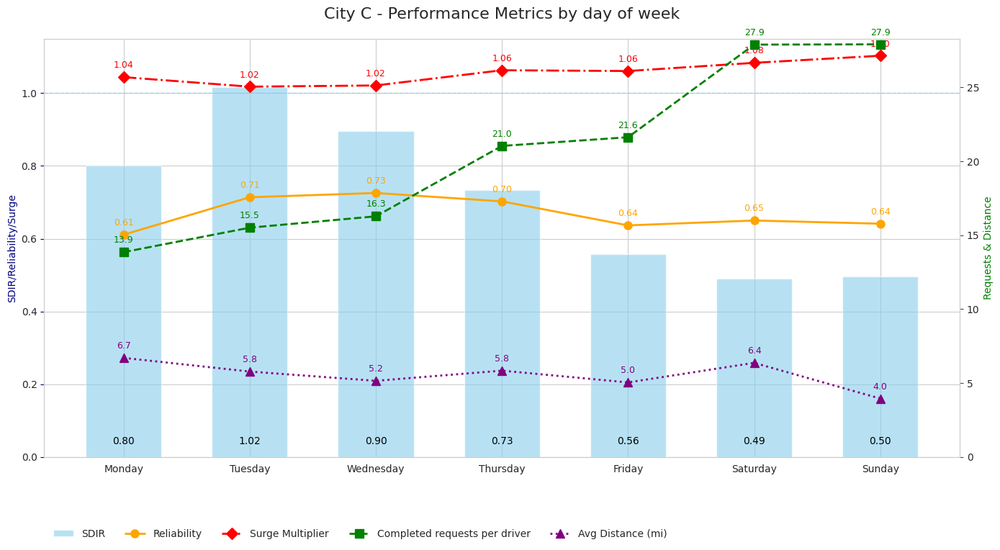

In [207]:
import matplotlib.pyplot as plt
import seaborn as sns

cities = ['A', 'B', 'C']

for city in cities:
    city_data = supply_realibility_ride_rate_day[supply_realibility_ride_rate_day['city'] == city]

    # Set style
    sns.set_style("whitegrid")
    plt.figure(figsize=(18, 8))

    # Create plot with primary y-axis (0-1.5 range)
    fig, ax1 = plt.subplots(figsize=(14, 8))

    # Plot SDIR (bars) - Primary axis
    bars = ax1.bar(city_data['day_name'], city_data['avg_sdir'], color='skyblue', alpha=0.6, width=0.6, label='SDIR')
    ax1.set_ylabel('SDIR/Reliability/Surge', color='navy')
    ax1.tick_params(axis='y', color='navy')
    ax1.set_ylim(0, 1.15)


    # Add reference line for SDIR balance
    ax1.axhline(1.0, color='skyblue', linestyle='--', linewidth=1, alpha=0.7)

    # Plot Reliability (line) - Same axis
    rel_line = ax1.plot(city_data['day_name'], city_data['avg_reliability'], 'o-', color='orange',
                   linewidth=2, markersize=8, label='Reliability')

    # Add value labels for Reliability points
    for x, y in zip(city_data['day_name'], city_data['avg_reliability']):
        ax1.text(x, y + 0.02, f'{y:.2f}', color='orange', ha='center', va='bottom', fontsize=9)

    # Plot Surge (line) - Same axis
    surge_line = ax1.plot(city_data['day_name'], city_data['avg_surge_multiplier'], 'D-.', color='red',
                     linewidth=2, markersize=8, label='Surge Multiplier')

    # Add value labels for Surge points
    for x, y in zip(city_data['day_name'], city_data['avg_surge_multiplier']):
        ax1.text(x, y + 0.02, f'{y:.2f}', color='red', ha='center', va='bottom', fontsize=9)

    # Create secondary y-axis (1-10 range)
    ax2 = ax1.twinx()
    req_line = ax2.plot(city_data['day_name'], city_data['completed_requests_per_driver'], 's--', color='green',
                   linewidth=2, markersize=8, label='Completed requests per driver')

    # Add value labels for Requests points
    for x, y in zip(city_data['day_name'], city_data['completed_requests_per_driver']):
        ax2.text(x, y + 0.5, f'{y:.1f}', color='green', ha='center', va='bottom', fontsize=9)

    dist_line = ax2.plot(city_data['day_name'], city_data['avg_distance'], '^:', color='purple',
                    linewidth=2, markersize=8, label='Avg Distance (mi)')

    # Add value labels for Distance points
    for x, y in zip(city_data['day_name'], city_data['avg_distance']):
        ax2.text(x, y + 0.5, f'{y:.1f}', color='purple', ha='center', va='bottom', fontsize=9)

    ax2.set_ylabel('Requests & Distance', color='green')
    ax2.tick_params(axis='y', color='green')
    ax2.set_ylim(0, 28.3)
    ax2.grid(False)

    # Combine all legends
    lines = [bars] + rel_line + surge_line + req_line + dist_line
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left',
          bbox_to_anchor=(0, -0.15), ncol=5, frameon=False)

    # Add value labels on SDIR bars
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., 0.03,
                f'{height:.2f}',
                ha='center', va='bottom',
                fontsize=10, color='black')

    # Title and layout
    plt.title(f'City {city} - Performance Metrics by day of week', pad=20, fontsize=16)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.2)
    plt.show()

<ipython-input-208-7151dcb1b08e>:121: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


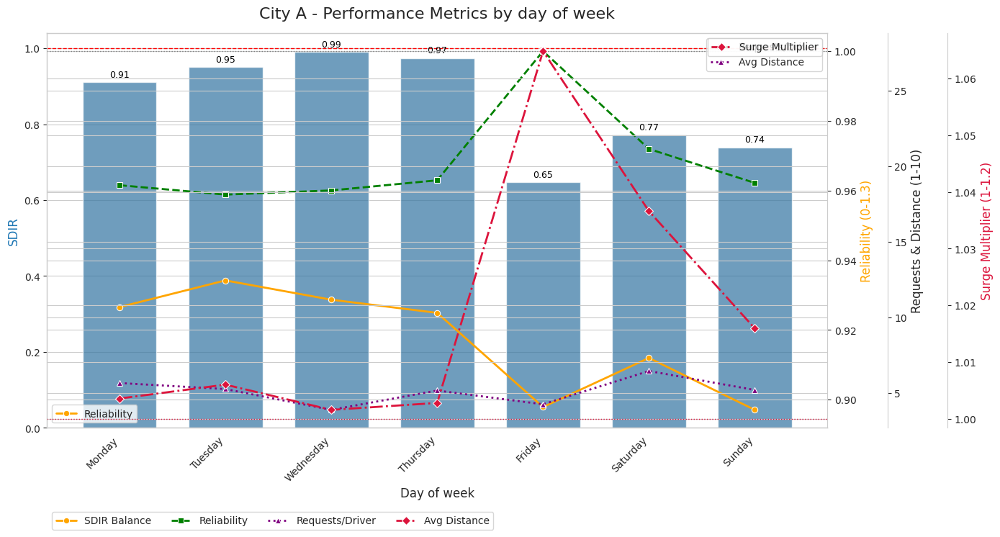

<ipython-input-208-7151dcb1b08e>:121: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


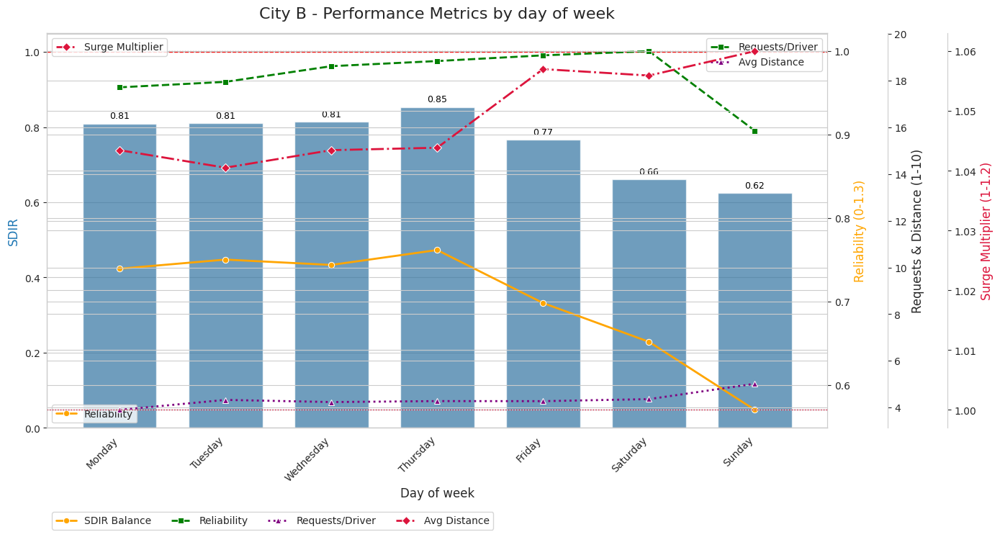

<ipython-input-208-7151dcb1b08e>:121: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


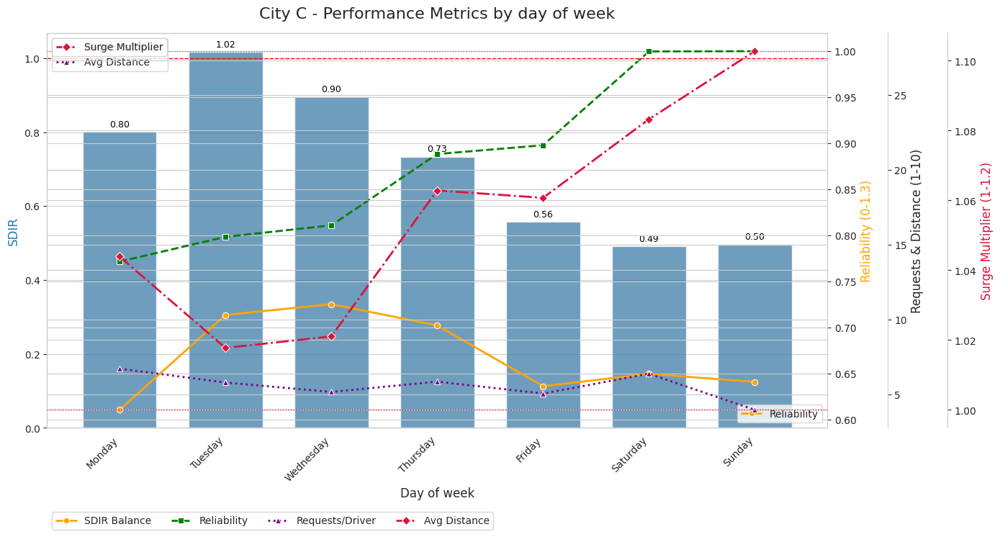

In [208]:
cities = ['A', 'B', 'C']

for city in cities:
    plt.figure(figsize=(14, 8))
    city_data = supply_realibility_ride_rate_day[supply_realibility_ride_rate_day['city'] == city]

    # Main axis for SDIR bars
    ax = sns.barplot(
        data=city_data,
        x='day_name',
        y='avg_sdir',
        color='#1f77b4',
        width=0.7,
        alpha=0.7
    )

    # Secondary axis for Reliability
    ax2 = ax.twinx()

    # Tertiary axis for Requests/Distance
    ax3 = ax.twinx()
    ax3.spines['right'].set_position(('outward', 60))

    # Fourth axis for Surge Multiplier
    ax4 = ax.twinx()
    ax4.spines['right'].set_position(('outward', 120))

    # Plot other metrics
    sns.lineplot(
        data=city_data,
        x='day_name',
        y='avg_reliability',
        color='orange',
        marker='o',
        linewidth=2,
        ax=ax2,
        label='Reliability'
    )

    sns.lineplot(
        data=city_data,
        x='day_name',
        y='completed_requests_per_driver',
        color='green',
        marker='s',
        linestyle='--',
        linewidth=2,
        ax=ax3,
        label='Requests/Driver'
    )

    sns.lineplot(
        data=city_data,
        x='day_name',
        y='avg_distance',
        color='purple',
        marker='^',
        linestyle=':',
        linewidth=2,
        ax=ax3,
        label='Avg Distance'
    )

    # New Surge Multiplier line
    sns.lineplot(
        data=city_data,
        x='day_name',
        y='avg_surge_multiplier',
        color='crimson',
        marker='D',
        linestyle='-.',
        linewidth=2,
        ax=ax4,
        label='Surge Multiplier'
    )

    # Customize axes labels
    ax.set_title(f'City {city} - Performance Metrics by day of week', fontsize=16, pad=15)
    ax.set_xlabel('Day of week', fontsize=12)
    ax.set_ylabel('SDIR', color='#1f77b4', fontsize=12)
    ax2.set_ylabel('Reliability (0-1.3)', color='orange', fontsize=12)
    ax3.set_ylabel('Requests & Distance (1-10)', fontsize=12)
    ax4.set_ylabel('Surge Multiplier (1-1.2)', color='crimson', fontsize=12)

    # Optional: Set axis limits
    # ax.set_ylim(0, 1.5)
    # ax2.set_ylim(0, 1.3)
    # ax3.set_ylim(1, 10)
    # ax4.set_ylim(1, 1.2)

    # Reference lines
    ax.axhline(1, color='red', linestyle='--', linewidth=1)
    ax2.axhline(1, color='gray', linestyle=':', linewidth=1)
    ax4.axhline(1, color='crimson', linestyle=':', linewidth=1)

    # Add bar value labels
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.2f}",
            (p.get_x() + p.get_width()/2., p.get_height()),
            ha='center', va='bottom',
            fontsize=9, color='black',
            xytext=(0, 3), textcoords='offset points'
        )

    # Combine legends from all axes
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()
    lines4, labels4 = ax4.get_legend_handles_labels()

    ax.legend(
        lines1 + lines2 + lines3 + lines4,
        ['SDIR Balance'] + labels2 + labels3 + labels4,
        loc='upper left',
        bbox_to_anchor=(0, -0.2),
        ncol=4
    )

    # Rotate x-ticks
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.25)  # More room for legend
    plt.show()


<ipython-input-209-7aa429989a5e>:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


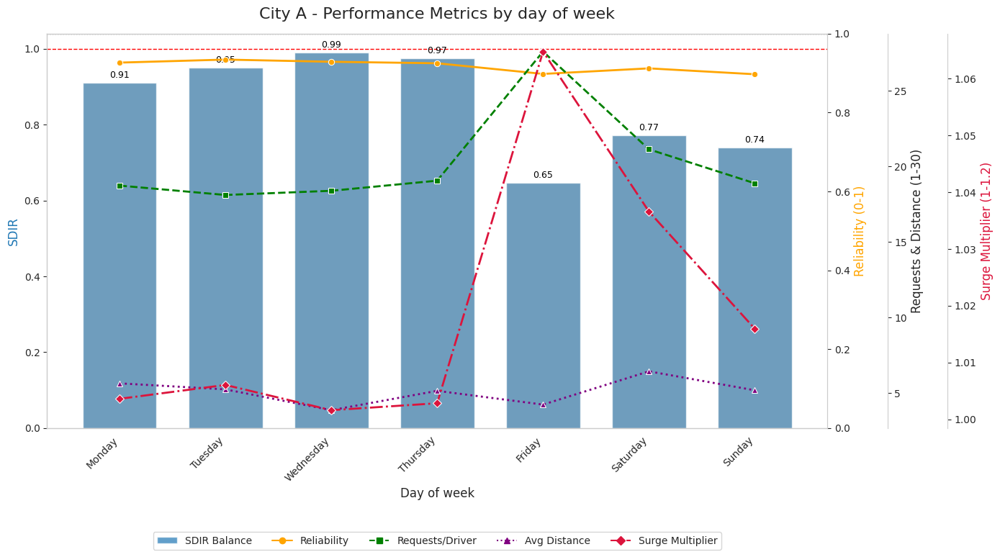

<ipython-input-209-7aa429989a5e>:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


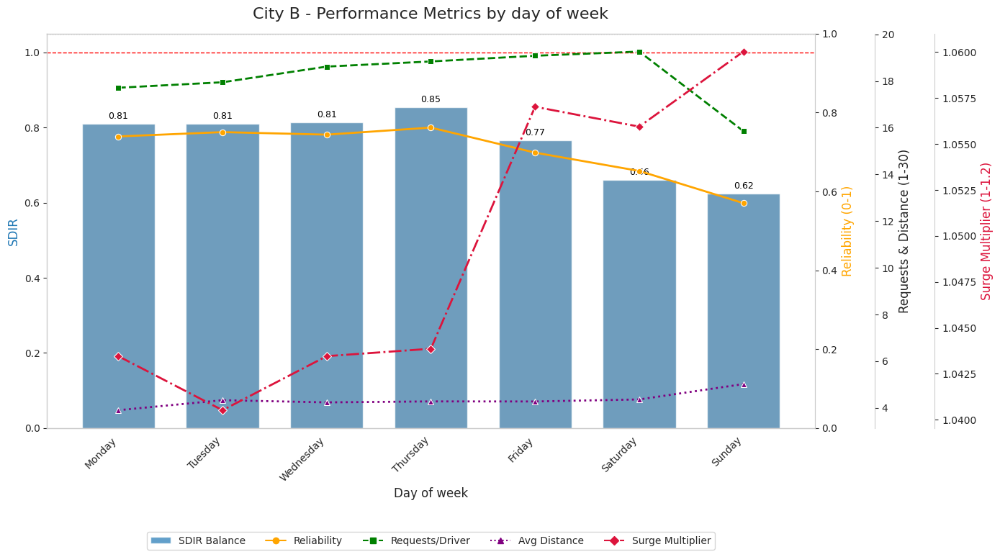

<ipython-input-209-7aa429989a5e>:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


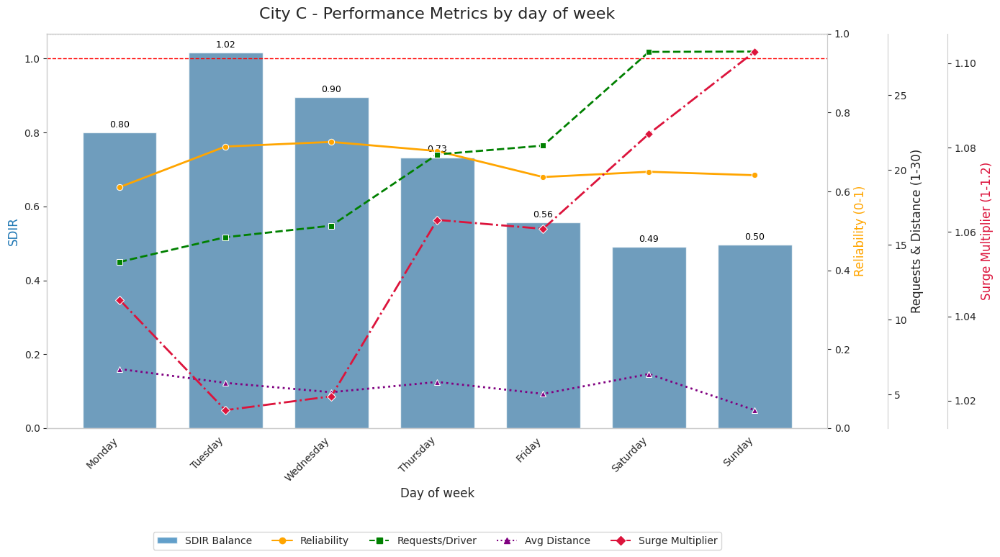

In [209]:
cities = ['A', 'B', 'C']

for city in cities:
    plt.figure(figsize=(14, 8))
    city_data = supply_realibility_ride_rate_day[supply_realibility_ride_rate_day['city'] == city]

    # Main axis for SDIR bars
    ax = sns.barplot(
        data=city_data,
        x='day_name',
        y='avg_sdir',
        color='#1f77b4',
        width=0.7,
        alpha=0.7
    )

    # Remove grid lines from ax
    ax.grid(False)

    # Secondary axis for Reliability
    ax2 = ax.twinx()
    ax2.grid(False)

    # Tertiary axis for Requests/Distance
    ax3 = ax.twinx()
    ax3.spines['right'].set_position(('outward', 60))
    ax3.grid(False)

    # Fourth axis for Surge Multiplier
    ax4 = ax.twinx()
    ax4.spines['right'].set_position(('outward', 120))
    ax4.grid(False)

    # Plot lines
    line1 = sns.lineplot(
        data=city_data,
        x='day_name',
        y='avg_reliability',
        color='orange',
        marker='o',
        linewidth=2,
        ax=ax2
    )

    line2 = sns.lineplot(
        data=city_data,
        x='day_name',
        y='completed_requests_per_driver',
        color='green',
        marker='s',
        linestyle='--',
        linewidth=2,
        ax=ax3
    )

    line3 = sns.lineplot(
        data=city_data,
        x='day_name',
        y='avg_distance',
        color='purple',
        marker='^',
        linestyle=':',
        linewidth=2,
        ax=ax3
    )

    line4 = sns.lineplot(
        data=city_data,
        x='day_name',
        y='avg_surge_multiplier',
        color='crimson',
        marker='D',
        linestyle='-.',
        linewidth=2,
        ax=ax4
    )

    # Axis labels and limits
    ax.set_title(f'City {city} - Performance Metrics by day of week', fontsize=16, pad=15)
    ax.set_xlabel('Day of week', fontsize=12)
    ax.set_ylabel('SDIR', color='#1f77b4', fontsize=12)
    ax2.set_ylabel('Reliability (0-1)', color='orange', fontsize=12)
    ax3.set_ylabel('Requests & Distance (1-30)', fontsize=12)
    ax4.set_ylabel('Surge Multiplier (1-1.2)', color='crimson', fontsize=12)

    ax2.set_ylim(0, 1)  # reliability from 0 to 1

    # Reference lines
    ax.axhline(1, color='red', linestyle='--', linewidth=1)
    ax2.axhline(1, color='gray', linestyle=':', linewidth=1)
    # ax4.axhline(1, color='crimson', linestyle=':', linewidth=1)

    # Add bar value labels
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.2f}",
            (p.get_x() + p.get_width()/2., p.get_height()),
            ha='center', va='bottom',
            fontsize=9, color='black',
            xytext=(0, 3), textcoords='offset points'
        )

    # Gather all line handles/labels
    handles = [
        plt.Line2D([], [], color='orange', marker='o', label='Reliability'),
        plt.Line2D([], [], color='green', marker='s', linestyle='--', label='Requests/Driver'),
        plt.Line2D([], [], color='purple', marker='^', linestyle=':', label='Avg Distance'),
        plt.Line2D([], [], color='crimson', marker='D', linestyle='-.', label='Surge Multiplier')
    ]
    bar_patch = plt.Rectangle((0,0),1,1,fc="#1f77b4", alpha=0.7, label='SDIR Balance')
    handles.insert(0, bar_patch)

    ax.legend(
        handles,
        [h.get_label() for h in handles],
        loc='upper center',
        bbox_to_anchor=(0.5, -0.25),
        ncol=5
    )

    # Rotate x-ticks
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.25)
    plt.show()


### Post_dispatch_eta

In [210]:
var_across_city_reliability(requested_rides_supply,'post_dispatch_eta')


,Avg_post_dispatch_eta_Unreliable,Avg_post_dispatch_eta_Reliable,City_Avg_post_dispatch_eta
city,,,
A,328.75,187.66,193.89
B,472.22,255.63,294.72
C,576.49,393.39,419.38


### Ride type

In [211]:
import pandas as pd
import numpy as np


# Define all possible conditions and corresponding labels
conditions = [
    # Regular rides
    (~requested_rides2['is_airport_trip'] &
     ~requested_rides2['is_business_trip'] &
     ~requested_rides2['is_scheduled_trip'] &
     ~requested_rides2['is_multidestination']),

    # Multidestination only
    (~requested_rides2['is_airport_trip'] &
     ~requested_rides2['is_business_trip'] &
     ~requested_rides2['is_scheduled_trip'] &
     requested_rides2['is_multidestination']),

    # Airport only
    (requested_rides2['is_airport_trip'] &
     ~requested_rides2['is_business_trip'] &
     ~requested_rides2['is_scheduled_trip'] &
     ~requested_rides2['is_multidestination']),

    # Business only
    (~requested_rides2['is_airport_trip'] &
     requested_rides2['is_business_trip'] &
     ~requested_rides2['is_scheduled_trip'] &
     ~requested_rides2['is_multidestination']),

    # Scheduled only
    (~requested_rides2['is_airport_trip'] &
     ~requested_rides2['is_business_trip'] &
     requested_rides2['is_scheduled_trip'] &
     ~requested_rides2['is_multidestination']),

    # Airport + Business
    (requested_rides2['is_airport_trip'] &
     requested_rides2['is_business_trip'] &
     ~requested_rides2['is_scheduled_trip'] &
     ~requested_rides2['is_multidestination']),

    # Airport + Scheduled
    (requested_rides2['is_airport_trip'] &
     ~requested_rides2['is_business_trip'] &
     requested_rides2['is_scheduled_trip'] &
     ~requested_rides2['is_multidestination']),

    # Business + Multidestination
    (~requested_rides2['is_airport_trip'] &
     requested_rides2['is_business_trip'] &
     ~requested_rides2['is_scheduled_trip'] &
     requested_rides2['is_multidestination']),

    # Airport + Multidestination
    (requested_rides2['is_airport_trip'] &
     ~requested_rides2['is_business_trip'] &
     ~requested_rides2['is_scheduled_trip'] &
     requested_rides2['is_multidestination']),

    # Business + Scheduled
    (~requested_rides2['is_airport_trip'] &
     requested_rides2['is_business_trip'] &
     requested_rides2['is_scheduled_trip'] &
     ~requested_rides2['is_multidestination']),

    # Airport + Business + Scheduled
    (requested_rides2['is_airport_trip'] &
     requested_rides2['is_business_trip'] &
     requested_rides2['is_scheduled_trip'] &
     ~requested_rides2['is_multidestination']),

    # Scheduled + Multidestination
    (~requested_rides2['is_airport_trip'] &
     ~requested_rides2['is_business_trip'] &
     requested_rides2['is_scheduled_trip'] &
     requested_rides2['is_multidestination']),

    # Airport + Scheduled + Multidestination
    (requested_rides2['is_airport_trip'] &
     ~requested_rides2['is_business_trip'] &
     requested_rides2['is_scheduled_trip'] &
     requested_rides2['is_multidestination']),

    # Airport + Business + Multidestination
    (requested_rides2['is_airport_trip'] &
     requested_rides2['is_business_trip'] &
     ~requested_rides2['is_scheduled_trip'] &
     requested_rides2['is_multidestination']),

    # All special flags
    (requested_rides2['is_airport_trip'] &
     requested_rides2['is_business_trip'] &
     requested_rides2['is_scheduled_trip'] &
     requested_rides2['is_multidestination'])
]

# Define corresponding ride types
ride_types = [
    'regular',
    'multidestination',
    'airport',
    'business',
    'scheduled',
    'airport + business',
    'airport + scheduled',
    'business + multidestination',
    'airport + multidestination',
    'business + scheduled',
    'airport + business + scheduled',
    'scheduled + multidestination',
    'airport + scheduled + multidestination',
    'airport + business + multidestination',
    'all_special'
]

# Create the new column
requested_rides2['ride_type'] = np.select(conditions, ride_types, default='other')

# Verify results
print("Ride type distribution:")
print(requested_rides2['ride_type'].value_counts().sort_index())

Ride type distribution:
ride_type
airport                                    1632
airport + business                           92
airport + business + multidestination         2
airport + business + scheduled                8
airport + multidestination                   54
airport + scheduled                          81
airport + scheduled + multidestination        5
business                                   1222
business + multidestination                  55
business + scheduled                         15
multidestination                           3400
regular                                   75604
scheduled                                   447
scheduled + multidestination                  7
Name: count, dtype: int64


In [212]:

ride_type_counts = requested_rides2['ride_type'].value_counts().reset_index()
ride_type_counts.columns = ['ride_type', 'count']


total_count = ride_type_counts['count'].sum()


ride_type_counts['percentage'] = (ride_type_counts['count'] / total_count * 100).round(2)


total_row = pd.DataFrame({
    'ride_type': ['TOTAL'],
    'count': [total_count],
    'percentage': [100.00]
})


result_table = pd.concat([ride_type_counts, total_row], ignore_index=True)

result_table

,ride_type,count,percentage
0,regular,75604,91.50
1,multidestination,3400,4.12
2,airport,1632,1.98
3,business,1222,1.48
4,scheduled,447,0.54
5,airport + business,92,0.11
6,airport + scheduled,81,0.10
7,business + multidestination,55,0.07
8,airport + multidestination,54,0.07
9,business + scheduled,15,0.02


In [213]:

grouped = requested_rides2.groupby(['city', 'ride_type', 'is_reliable_pickup']).size().reset_index(name='count')

totals = grouped.groupby(['city', 'ride_type'])['count'].sum().reset_index(name='total')


merged = pd.merge(grouped, totals, on=['city', 'ride_type'])

merged['percentage'] = (merged['count'] / merged['total'] * 100).round(2)


pivot_result = merged.pivot_table(
    index=['city', 'ride_type'],
    columns='is_reliable_pickup',
    values=['count', 'percentage'],
    fill_value=0
).reset_index()


pivot_result.columns = [
    'city',
    'ride_type',
    'Unreliable',
    'Reliable',
    'Unreliable (%)',
    'Reliable (%)'
]

pivot_result['total_count'] = pivot_result['Unreliable'] + pivot_result['Reliable']

pivot_result = pivot_result.sort_values(
    by=['city', 'total_count'],
    ascending=[True, False]
)

pivot_result = pivot_result[[
    'city',
    'ride_type',
    'total_count',
    'Unreliable',
    'Unreliable (%)',
    'Reliable',
    'Reliable (%)'
]]

pivot_result

,city,ride_type,total_count,Unreliable,Unreliable (%),Reliable,Reliable (%)
8,A,regular,35269.0,2949.0,8.36,32320.0,91.64
7,A,multidestination,1004.0,56.0,5.58,948.0,94.42
5,A,business,435.0,43.0,9.89,392.0,90.11
0,A,airport,110.0,40.0,36.36,70.0,63.64
6,A,business + multidestination,14.0,0.0,0.00,14.0,100.00
1,A,airport + business,11.0,2.0,18.18,9.0,81.82
9,A,scheduled,7.0,7.0,100.00,0.0,0.00
3,A,airport + multidestination,2.0,2.0,100.00,0.0,0.00
4,A,airport + scheduled,2.0,0.0,0.00,2.0,100.00
2,A,airport + business + multidestination,1.0,0.0,0.00,1.0,100.00


### Price difference

In [214]:
# Define conditions and corresponding names
conditions = [
    # Regular rides
    (~requested_rides2['is_airport_trip'] &
     ~requested_rides2['is_business_trip'] &
     ~requested_rides2['is_scheduled_trip'] &
     ~requested_rides2['is_multidestination']),

    # Airport trips
    requested_rides2['is_airport_trip'],

    # Business trips
    requested_rides2['is_business_trip'],

    # Scheduled trips
    requested_rides2['is_scheduled_trip'],

    # Multidestination trips
    requested_rides2['is_multidestination']
]

names = ['REGULAR RIDES', 'AIRPORT RIDES', 'BUSINESS RIDES', 'SCHEDULED RIDES', 'MULTIDESTINATION RIDES']

# Generate separate table for each condition
for condition, name in zip(conditions, names):
    # Filter data for current condition and drop NaNs or Infs in request_price_per_est_mile
    rides_type = requested_rides2[condition].copy()
    rides_type = rides_type[np.isfinite(rides_type['request_client_fare_local'])]

    # Group by city and is_matched, calculate average price per mile
    result = rides_type.groupby(['city', 'is_reliable_pickup'])['request_client_fare_local'] \
                     .mean() \
                     .reset_index() \
                     .rename(columns={'request_client_fare_local': 'avg_client_fare_local'})

    # Pivot for matched and unmatched averages
    pivot_result = result.pivot(
        index='city',
        columns='is_reliable_pickup',
        values='avg_client_fare_local'
    ).reset_index()

    # Rename columns for clarity
    pivot_result = pivot_result.rename(columns={
        True: 'avg_client_fare_local_reliable',
        False: 'avg_client_fare_local_unreliable'
    })

    # Compute overall average price per city
    overall_avg = rides_type.groupby('city')['request_client_fare_local'].mean().reset_index()
    overall_avg = overall_avg.rename(columns={'request_client_fare_local': 'overall_avg_client_fare_local'})

    # Merge overall average into pivot table
    final_result = pd.merge(pivot_result, overall_avg, on='city', how='outer')

    # Print the result for current ride type
    print(f"\n{name}:\n")
    print(final_result)



REGULAR RIDES:

  city  avg_client_fare_local_unreliable  avg_client_fare_local_reliable  \
0    A                          7.796775                        5.457653   
1    B                         56.132638                       46.131909   
2    C                         15.608019                       14.677423   

   overall_avg_client_fare_local  
0                       5.653237  
1                      49.153215  
2                      14.995507  

AIRPORT RIDES:

  city  avg_client_fare_local_unreliable  avg_client_fare_local_reliable  \
0    A                         63.574545                       77.971707   
1    B                        147.292271                      125.768755   
2    C                        193.242353                      164.091250   

   overall_avg_client_fare_local  
0                      72.944127  
1                     130.988869  
2                     176.178293  

BUSINESS RIDES:

  city  avg_client_fare_local_unreliable  avg_client_fare_

### Product type

In [215]:
print(requested_rides_supply.groupby('city')['is_reliable_pickup'].mean())
print(requested_rides_supply.groupby(['city','pickup_geo'])['is_reliable_pickup'].mean())
print(requested_rides_supply.groupby(['city','request_product_name'])['is_reliable_pickup'].mean())
print(requested_rides_supply.groupby(['city',requested_rides2['hour_bin'].dt.hour])['is_reliable_pickup'].mean())

city
A    0.915914
B    0.701644
C    0.662782
Name: is_reliable_pickup, dtype: float64
city  pickup_geo
C     Core          0.728978
      Non-Core      0.623219
Name: is_reliable_pickup, dtype: float64
city  request_product_name
A     Black                   0.666667
      Low Cost                0.714286
      RiderItemDelivery       0.785714
      UberX                   0.916175
B     Black                   0.333333
      Mid-Tier                0.500000
      RiderItemDelivery       0.400000
      UberX                   0.716924
      UberXL                  0.151358
C     Black                   1.000000
      Mid-Tier                0.500000
      SUV                     0.625000
      UberX                   0.662798
      taxi                    1.000000
Name: is_reliable_pickup, dtype: float64
city  hour_bin
A     0.0         0.907579
      1.0         0.912114
      2.0         0.931034
      3.0         0.932203
      4.0         0.935223
                    ...   
C    

In [216]:
result = requested_rides_supply.groupby(['city', 'request_product_name']).agg(
    reliability_rate=('is_reliable_pickup', 'mean'),
    num_reliable=('is_reliable_pickup', lambda x: (x == 1).sum()),
    num_unreliable=('is_reliable_pickup', lambda x: (x == 0).sum()),
    num_na=('is_reliable_pickup', lambda x: x.isna().sum())
).reset_index()

result


,city,request_product_name,reliability_rate,num_reliable,num_unreliable,num_na
0,A,Black,0.666667,2,1,0
1,A,Low Cost,0.714286,25,10,0
2,A,RiderItemDelivery,0.785714,11,3,0
3,A,UberX,0.916175,33718,3085,0
4,B,Black,0.333333,1,2,0
5,B,Mid-Tier,0.500000,2,2,0
6,B,RiderItemDelivery,0.400000,4,6,0
7,B,UberX,0.716924,20190,7972,0
8,B,UberXL,0.151358,117,656,0
9,C,Black,1.000000,1,0,0


In [217]:
# Economy / Low Fare	'Low Cost', 'UberX'
# Mid-Tier / Comfort	'Mid-Tier', 'UberXL'
# Premium / High-End	'Black', 'SUV'
# Other / Non-Ride	'RiderItemDelivery'


requested_rides_supply['request_price_per_est_mile'] = requested_rides_supply['request_client_fare_local']/requested_rides_supply['est_rider_fare_distance_miles']

# Drop rows with infinite values and NaN surge multipliers
cleaned_data = requested_rides_supply[
    (requested_rides_supply['request_price_per_est_mile'] != float('inf')) &
    (requested_rides_supply['request_surge_multiplier'].notna())
].copy()

# Group and calculate metrics including surge multiplier
result = cleaned_data.groupby(['city', 'request_product_name']).agg(
    avg_price_per_mile=('request_price_per_est_mile', 'mean'),
    avg_surge_multiplier=('request_surge_multiplier', 'mean'),
    reliability_rate=('is_reliable_pickup', 'mean'),
    num_reliable=('is_reliable_pickup', lambda x: (x == 1).sum()),
    num_unreliable=('is_reliable_pickup', lambda x: (x == 0).sum()),
    total_requests=('request_id', 'count')
).reset_index()

# Format percentages and round decimals
result['reliability_rate_pct'] = (result['reliability_rate'] * 100).round(1)
result['avg_price_per_mile'] = result['avg_price_per_mile'].round(2)
result['avg_surge_multiplier'] = result['avg_surge_multiplier'].round(2)

# Reorder columns
result = result[[
    'city', 'request_product_name', 'avg_price_per_mile', 'avg_surge_multiplier',
    'reliability_rate', 'reliability_rate_pct', 'num_reliable', 'num_unreliable', 'total_requests'
]]

result

#Wrong pricing for product types

,city,request_product_name,avg_price_per_mile,avg_surge_multiplier,reliability_rate,reliability_rate_pct,num_reliable,num_unreliable,total_requests
0,A,Black,5.11,1.03,0.666667,66.7,2,1,3
1,A,Low Cost,1.47,1.00,0.714286,71.4,25,10,35
2,A,RiderItemDelivery,10.13,1.00,0.785714,78.6,11,3,14
3,A,UberX,2.14,1.02,0.916322,91.6,33717,3079,36796
4,B,Black,32.06,1.00,0.333333,33.3,1,2,3
5,B,Mid-Tier,19.59,1.00,0.500000,50.0,2,2,4
6,B,RiderItemDelivery,9.34,1.00,0.400000,40.0,4,6,10
7,B,UberX,19.69,1.05,0.716964,71.7,20189,7970,28159
8,B,UberXL,24.15,1.00,0.151554,15.2,117,655,772
9,C,Black,3.32,1.00,1.000000,100.0,1,0,1


### Geo pickup and dropoff

In [218]:

# Drop rows where request_price_per_est_mile is inf
cleaned_data = requested_rides_supply[requested_rides_supply['request_price_per_est_mile'] != float('inf')]


# Group and calculate
result = cleaned_data.groupby(['city', 'pickup_geo', 'dropoff_geo']).agg(
    avg_price_per_mile=('request_price_per_est_mile', 'mean'),
    reliability_rate=('is_reliable_pickup', 'mean'),
    num_reliable=('is_reliable_pickup', lambda x: (x == 1).sum()),
    num_unreliable=('is_reliable_pickup', lambda x: (x == 0).sum()),
    avg_surge_multiplier =('request_surge_multiplier', 'mean'),
    avg_SDIR =('SDIR', 'mean')
).reset_index()

result

,city,pickup_geo,dropoff_geo,avg_price_per_mile,reliability_rate,num_reliable,num_unreliable,avg_surge_multiplier,avg_SDIR
0,C,Core,Core,12.392041,0.704467,1025,430,1.102955,0.656140
1,C,Core,Non-Core,7.327419,0.736352,3561,1275,1.102254,0.638262
2,C,Non-Core,Core,5.858104,0.671959,2497,1219,1.061329,0.671168
3,C,Non-Core,Non-Core,6.517661,0.597676,4063,2735,1.052177,0.660292


In [219]:
# Drop rows where request_price_per_est_mile is inf
cleaned_data = requested_rides_supply[requested_rides_supply['request_price_per_est_mile'] != float('inf')]

# Group and calculate by city + pickup + dropoff geo
result = cleaned_data.groupby(['city', 'pickup_geo', 'dropoff_geo']).agg(
    avg_price_per_mile=('request_price_per_est_mile', 'mean'),
    reliability_rate=('is_reliable_pickup', 'mean'),
    num_reliable=('is_reliable_pickup', lambda x: (x == 1).sum()),
    num_unreliable=('is_reliable_pickup', lambda x: (x == 0).sum()),
    avg_surge_multiplier=('request_surge_multiplier', 'mean'),
    avg_SDIR=('SDIR', 'mean')
).reset_index()

# Calculate overall averages and sums
overall = pd.DataFrame({
    'city': ['Overall'],
    'pickup_geo': ['Overall'],
    'dropoff_geo': ['Overall'],
    'avg_price_per_mile': [cleaned_data['request_price_per_est_mile'].mean()],
    'reliability_rate': [cleaned_data['is_reliable_pickup'].mean()],
    'num_reliable': [(cleaned_data['is_reliable_pickup'] == 1).sum()],
    'num_unreliable': [(cleaned_data['is_reliable_pickup'] == 0).sum()],
    'avg_surge_multiplier': [cleaned_data['request_surge_multiplier'].mean()],
    'avg_SDIR': [cleaned_data['SDIR'].mean()]
})

# Append overall row to result
result = pd.concat([result, overall], ignore_index=True)

# View result
result

,city,pickup_geo,dropoff_geo,avg_price_per_mile,reliability_rate,num_reliable,num_unreliable,avg_surge_multiplier,avg_SDIR
0,C,Core,Core,12.392041,0.704467,1025,430,1.102955,0.656140
1,C,Core,Non-Core,7.327419,0.736352,3561,1275,1.102254,0.638262
2,C,Non-Core,Core,5.858104,0.671959,2497,1219,1.061329,0.671168
3,C,Non-Core,Non-Core,6.517661,0.597676,4063,2735,1.052177,0.660292
4,Overall,Overall,Overall,9.388437,0.789506,65214,17387,1.043067,0.774414


### Machine Learning algorithm

In [220]:
requested_rides_supply_drivers = pd.merge(
    requested_rides_supply,
    driver_dispatches,
    how='outer',
    left_on=['request_id', 'city'],
    right_on=['job_id', 'city'],
    indicator=True  # Optional: adds _merge column showing source
)


requested_rides_supply_drivers[['request_id','job_id', 'request_timestamp_local', 'job_timestamp_local','driver_id_x','driver_id_y']].sort_values(by = ['request_id', 'job_timestamp_local'])

,request_id,job_id,request_timestamp_local,job_timestamp_local,driver_id_x,driver_id_y
1,0000c-ce7e-4e01-a048-e845c9d8efe20dc,0000c-ce7e-4e01-a048-e845c9d8efe20dc,2023-04-05 00:46:22,2023-04-05 00:46:25,44475-8941-47dc-808f-b59b85f75fd4116,5cd06-964d-47b6-b4c4-24b4ba1528b454d
0,0000c-ce7e-4e01-a048-e845c9d8efe20dc,0000c-ce7e-4e01-a048-e845c9d8efe20dc,2023-04-05 00:46:22,2023-04-05 00:46:40,44475-8941-47dc-808f-b59b85f75fd4116,44475-8941-47dc-808f-b59b85f75fd4116
2,00015-f18f-4eac-b7aa-a51e994ebeaef8c,00015-f18f-4eac-b7aa-a51e994ebeaef8c,2023-04-16 19:34:26,2023-04-16 19:34:28,fd0d7-cba0-4795-9844-676f06c216a4b8a,91457-b2fb-47fc-9014-71adf4c6228c6a6
3,00015-f18f-4eac-b7aa-a51e994ebeaef8c,00015-f18f-4eac-b7aa-a51e994ebeaef8c,2023-04-16 19:34:26,2023-04-16 19:34:48,fd0d7-cba0-4795-9844-676f06c216a4b8a,da41d-7cfb-4fba-99d1-5574a0cac1bcbc2
4,00015-f18f-4eac-b7aa-a51e994ebeaef8c,00015-f18f-4eac-b7aa-a51e994ebeaef8c,2023-04-16 19:34:26,2023-04-16 19:35:13,fd0d7-cba0-4795-9844-676f06c216a4b8a,fd0d7-cba0-4795-9844-676f06c216a4b8a
...,...,...,...,...,...,...
160843,fffbc-2ff8-4857-9f1c-e20df89a441787e,fffbc-2ff8-4857-9f1c-e20df89a441787e,2023-04-16 20:21:05,2023-04-16 20:21:13,6bb4b-4268-4f5b-9b49-9f607678cc7c885,1f441-5548-428b-99bc-5ca04d4b5b94a72
160844,fffbc-2ff8-4857-9f1c-e20df89a441787e,fffbc-2ff8-4857-9f1c-e20df89a441787e,2023-04-16 20:21:05,2023-04-16 20:22:13,6bb4b-4268-4f5b-9b49-9f607678cc7c885,6bb4b-4268-4f5b-9b49-9f607678cc7c885
160845,fffee-2022-4454-9277-c24b7e4e9a9a9ab,fffee-2022-4454-9277-c24b7e4e9a9a9ab,2023-04-02 06:45:36,2023-04-02 06:45:44,bb46b-594a-4bb4-910b-68104f447d96b51,bb46b-594a-4bb4-910b-68104f447d96b51
160846,ffff1-712c-4882-bb41-e4cd598e192ff14,ffff1-712c-4882-bb41-e4cd598e192ff14,2023-04-17 17:58:16,2023-04-17 17:58:19,f4d48-ccda-4d74-9887-bbb47bb1688c4a2,f4d48-ccda-4d74-9887-bbb47bb1688c4a2


In [221]:
#Quality

# 'request_timestamp_local', 'job_timestamp_local'


print(len(requested_rides_supply_drivers))


#Quality check

print(len(requested_rides_supply_drivers['request_timestamp_local'] <=requested_rides_supply_drivers['job_timestamp_local']))

160848
160848


In [222]:
#Calculate time spend on matching

# Calculate time difference in seconds for each row
requested_rides_supply_drivers['time_diff_sec'] = (
    requested_rides_supply_drivers['job_timestamp_local'] -
    requested_rides_supply_drivers['request_timestamp_local']
).dt.total_seconds()

# For each job_id, find the maximum time difference
max_time_per_job = requested_rides_supply_drivers.groupby('job_id')['time_diff_sec'].max().reset_index()
max_time_per_job.columns = ['job_id', 'matching_time_spend_sec']

# Merge back to original dataframe
requested_rides_supply_drivers = pd.merge(
    requested_rides_supply_drivers,
    max_time_per_job,
    on='job_id',
    how='left'
)

# Drop the temporary column
requested_rides_supply_drivers = requested_rides_supply_drivers.drop(columns=['time_diff_sec'])


In [223]:
requested_rides_supply_drivers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160848 entries, 0 to 160847
Data columns (total 53 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   rider_session_id                     160848 non-null  object        
 1   session_start_timestamp_local        160757 non-null  datetime64[ns]
 2   rider_id                             160848 non-null  object        
 3   city                                 160848 non-null  object        
 4   app_version                          160848 non-null  object        
 5   duration_ms                          160848 non-null  float64       
 6   session_last_eta                     150478 non-null  float64       
 7   session_last_surge_multiplier        150384 non-null  float64       
 8   session_last_fare_local              149649 non-null  float64       
 9   session_average_trip_distance_miles  160848 non-null  float64       
 

In [224]:
requested_rides_supply_drivers[['request_id', 'request_timestamp_local','job_timestamp_local', 'matching_time_spend_sec' ]].sort_values(by = ['request_id', 'job_timestamp_local']).head(10)

,request_id,request_timestamp_local,job_timestamp_local,matching_time_spend_sec
1,0000c-ce7e-4e01-a048-e845c9d8efe20dc,2023-04-05 00:46:22,2023-04-05 00:46:25,18.0
0,0000c-ce7e-4e01-a048-e845c9d8efe20dc,2023-04-05 00:46:22,2023-04-05 00:46:40,18.0
2,00015-f18f-4eac-b7aa-a51e994ebeaef8c,2023-04-16 19:34:26,2023-04-16 19:34:28,47.0
3,00015-f18f-4eac-b7aa-a51e994ebeaef8c,2023-04-16 19:34:26,2023-04-16 19:34:48,47.0
4,00015-f18f-4eac-b7aa-a51e994ebeaef8c,2023-04-16 19:34:26,2023-04-16 19:35:13,47.0
8,0001e-7af7-4898-97ce-eac2c7c47e12bc5,2023-04-15 20:35:11,2023-04-15 20:35:18,572.0
6,0001e-7af7-4898-97ce-eac2c7c47e12bc5,2023-04-15 20:35:11,2023-04-15 20:35:38,572.0
7,0001e-7af7-4898-97ce-eac2c7c47e12bc5,2023-04-15 20:35:11,2023-04-15 20:35:58,572.0
5,0001e-7af7-4898-97ce-eac2c7c47e12bc5,2023-04-15 20:35:11,2023-04-15 20:44:43,572.0
9,0001e-f2de-422d-9e8f-f2815a9c8c2dae4,2023-04-21 18:38:24,2023-04-21 18:38:30,6.0


In [225]:
requested_rides_supply_drivers[requested_rides_supply_drivers.matching_time_spend_sec.isna()][
    ['request_id', 'request_status','driver_id_x', 'driver_id_y','request_timestamp_local','job_timestamp_local', 'matching_time_spend_sec', 'is_matched' ]]

,request_id,request_status,driver_id_x,driver_id_y,request_timestamp_local,job_timestamp_local,matching_time_spend_sec,is_matched
44,00151-e228-4c85-a1ea-0d511a5722bac20,completed,442b6-fcb1-471a-b1a8-81bf4bf82c4da74,NaN,2023-04-11 11:30:00,NaT,NaN,True
128,00282-7bfc-401c-8215-b9d958e7fe115be,unfulfilled,NaN,NaN,2023-04-04 13:24:15,NaT,NaN,False
168,002fb-7eaa-49eb-bedd-005eaac1208bc5e,unfulfilled,NaN,NaN,2023-04-03 18:07:12,NaT,NaN,False
172,00428-9ec1-42c5-8ed8-cb90f09d580a0b9,completed,1095b-5595-4417-8ac0-820bd9b5f4962bd,NaN,2023-04-17 19:13:39,NaT,NaN,True
179,00478-cdea-4f07-92a9-1c08795490225a9,completed,516cc-aa0f-4749-afb0-992a67f6a444db4,NaN,2023-04-19 15:10:00,NaT,NaN,True
...,...,...,...,...,...,...,...,...
160620,ffac1-1782-41ec-a09e-e00dbbe1c8a2a55,rider_canceled,NaN,NaN,2023-04-19 10:16:26,NaT,NaN,False
160632,ffb27-29e4-47ef-9eb0-ab4c227c7e5289e,completed,a76cb-2c78-40cf-8c64-bd6261784ba9111,NaN,2023-04-12 11:06:56,NaT,NaN,True
160690,ffcbe-78b1-4c9e-8110-94f5b4818d29e52,completed,64b5c-f040-4c4c-8f6b-ffa1cb55921b8a1,NaN,2023-04-21 14:41:49,NaT,NaN,True
160761,ffe0c-dba4-4eb8-89b5-a955ae1ed58be97,unfulfilled,NaN,NaN,2023-04-04 18:47:43,NaT,NaN,False


In [226]:
driver_dispatches[(driver_dispatches['driver_id'] == '442b6-fcb1-471a-b1a8-81bf4bf82c4da74') &
                  (driver_dispatches['job_id'] == '00151-e228-4c85-a1ea-0d511a5722bac20')]

,city,job_id,driver_id,job_timestamp_local,offered_eta,dispatch_type,dispatch_length_km,is_accept,is_cancel


In [227]:
#even the request was matched with driver, this request wasn't recorded in driver_dispach table


driver_dispatches[(driver_dispatches['driver_id'] == '442b6-fcb1-471a-b1a8-81bf4bf82c4da74') & (driver_dispatches['job_timestamp_local'].dt.date == pd.to_datetime('2023-04-11').date())].sort_values(by='job_timestamp_local')

,city,job_id,driver_id,job_timestamp_local,offered_eta,dispatch_type,dispatch_length_km,is_accept,is_cancel
140024,C,bb429-1b08-4b28-ac10-fdfd4190d9510bf,442b6-fcb1-471a-b1a8-81bf4bf82c4da74,2023-04-11 07:51:13,467,REGULAR,2.408,True,False
127617,C,7da20-0a9f-4284-8bc1-eddc442b24e79c0,442b6-fcb1-471a-b1a8-81bf4bf82c4da74,2023-04-11 07:57:43,1134,FORWARD_DISPATCH,3.715,True,False
139005,C,b5242-edd0-4284-a1ef-2f0e0ac5571a450,442b6-fcb1-471a-b1a8-81bf4bf82c4da74,2023-04-11 08:09:43,912,FORWARD_DISPATCH,4.084,True,False
139137,C,b5e1e-5ab5-40e8-bbcb-b22ce7a1ee5e9ff,442b6-fcb1-471a-b1a8-81bf4bf82c4da74,2023-04-11 08:33:28,948,FORWARD_DISPATCH,6.176,True,False
122099,C,52078-78e2-4da7-9929-b1c977c0b7fe71c,442b6-fcb1-471a-b1a8-81bf4bf82c4da74,2023-04-11 08:36:58,1026,FORWARD_DISPATCH,9.210,True,False
147787,C,e0858-9205-405e-a821-5abfeaf290548fa,442b6-fcb1-471a-b1a8-81bf4bf82c4da74,2023-04-11 08:48:23,525,REGULAR,2.420,True,False
117506,C,2d847-829f-4e20-a02e-5df52d25510f425,442b6-fcb1-471a-b1a8-81bf4bf82c4da74,2023-04-11 09:43:33,122,REGULAR,0.762,True,False
112812,C,20cfb-b8b9-4fff-b242-91fcaa5a01af18f,442b6-fcb1-471a-b1a8-81bf4bf82c4da74,2023-04-11 10:17:48,334,REGULAR,2.767,True,False
136230,C,a8aaa-9448-4801-8c44-bef8f2122f9cce7,442b6-fcb1-471a-b1a8-81bf4bf82c4da74,2023-04-11 19:12:36,98,REGULAR,0.405,True,False
154705,C,f29d5-18e4-41b2-98e2-e1c5b494ea2fdcc,442b6-fcb1-471a-b1a8-81bf4bf82c4da74,2023-04-11 19:30:41,418,REGULAR,4.356,False,False


In [228]:
requested_rides_supply_drivers[['request_id', 'driver_id_x','driver_id_y','is_accept', 'is_cancel']].sort_values(by = ['request_id']).head(15)

,request_id,driver_id_x,driver_id_y,is_accept,is_cancel
0,0000c-ce7e-4e01-a048-e845c9d8efe20dc,44475-8941-47dc-808f-b59b85f75fd4116,44475-8941-47dc-808f-b59b85f75fd4116,True,False
1,0000c-ce7e-4e01-a048-e845c9d8efe20dc,44475-8941-47dc-808f-b59b85f75fd4116,5cd06-964d-47b6-b4c4-24b4ba1528b454d,False,False
2,00015-f18f-4eac-b7aa-a51e994ebeaef8c,fd0d7-cba0-4795-9844-676f06c216a4b8a,91457-b2fb-47fc-9014-71adf4c6228c6a6,False,False
3,00015-f18f-4eac-b7aa-a51e994ebeaef8c,fd0d7-cba0-4795-9844-676f06c216a4b8a,da41d-7cfb-4fba-99d1-5574a0cac1bcbc2,False,False
4,00015-f18f-4eac-b7aa-a51e994ebeaef8c,fd0d7-cba0-4795-9844-676f06c216a4b8a,fd0d7-cba0-4795-9844-676f06c216a4b8a,True,False
5,0001e-7af7-4898-97ce-eac2c7c47e12bc5,47fc5-441a-42a8-a749-4fb841f84f7c41c,47fc5-441a-42a8-a749-4fb841f84f7c41c,True,False
6,0001e-7af7-4898-97ce-eac2c7c47e12bc5,47fc5-441a-42a8-a749-4fb841f84f7c41c,4bb8a-4162-4b0b-afbb-f1db468a1d440b8,True,True
7,0001e-7af7-4898-97ce-eac2c7c47e12bc5,47fc5-441a-42a8-a749-4fb841f84f7c41c,594d4-8057-40bb-aacc-2612294b6846788,False,False
8,0001e-7af7-4898-97ce-eac2c7c47e12bc5,47fc5-441a-42a8-a749-4fb841f84f7c41c,9c7a6-df12-4bab-9fd8-941ad9da07b1d21,False,False
9,0001e-f2de-422d-9e8f-f2815a9c8c2dae4,cf528-5c14-40b9-8716-f9dc4c7ab742b64,cf528-5c14-40b9-8716-f9dc4c7ab742b64,True,False


In [229]:
#cancellation, acceptance, decline counts and total counts


# Calculate counts per request_id
counts_df = requested_rides_supply_drivers.groupby('request_id').agg(
    acceptance_count=('is_accept', lambda x: np.sum(x == True)),
    decline_count=('is_accept', lambda x: np.sum(x == False)),
    cancellation_count=('is_cancel', lambda x: np.sum(x == True)),
    total_count=('request_id', 'count')
).reset_index()

# Merge back to original DataFrame
requested_rides_supply_drivers = pd.merge(
    requested_rides_supply_drivers,
    counts_df,
    on='request_id',
    how='left'
)


for col in ['acceptance_count', 'decline_count', 'cancellation_count', 'total_count']:
    if col in requested_rides_supply_drivers.columns:
        requested_rides_supply_drivers[col] = requested_rides_supply_drivers[col].astype(int)
    else:
        print(f"Warning: Column {col} not found in DataFrame")

In [230]:
requested_rides_supply_drivers[['request_id', 'driver_id_x','driver_id_y','is_accept', 'is_cancel',
                                'acceptance_count','decline_count', 'cancellation_count', 'total_count']].sort_values(by = ['request_id']).head(30)

,request_id,driver_id_x,driver_id_y,is_accept,is_cancel,acceptance_count,decline_count,cancellation_count,total_count
0,0000c-ce7e-4e01-a048-e845c9d8efe20dc,44475-8941-47dc-808f-b59b85f75fd4116,44475-8941-47dc-808f-b59b85f75fd4116,True,False,1,1,0,2
1,0000c-ce7e-4e01-a048-e845c9d8efe20dc,44475-8941-47dc-808f-b59b85f75fd4116,5cd06-964d-47b6-b4c4-24b4ba1528b454d,False,False,1,1,0,2
2,00015-f18f-4eac-b7aa-a51e994ebeaef8c,fd0d7-cba0-4795-9844-676f06c216a4b8a,91457-b2fb-47fc-9014-71adf4c6228c6a6,False,False,1,2,0,3
3,00015-f18f-4eac-b7aa-a51e994ebeaef8c,fd0d7-cba0-4795-9844-676f06c216a4b8a,da41d-7cfb-4fba-99d1-5574a0cac1bcbc2,False,False,1,2,0,3
4,00015-f18f-4eac-b7aa-a51e994ebeaef8c,fd0d7-cba0-4795-9844-676f06c216a4b8a,fd0d7-cba0-4795-9844-676f06c216a4b8a,True,False,1,2,0,3
5,0001e-7af7-4898-97ce-eac2c7c47e12bc5,47fc5-441a-42a8-a749-4fb841f84f7c41c,47fc5-441a-42a8-a749-4fb841f84f7c41c,True,False,2,2,1,4
6,0001e-7af7-4898-97ce-eac2c7c47e12bc5,47fc5-441a-42a8-a749-4fb841f84f7c41c,4bb8a-4162-4b0b-afbb-f1db468a1d440b8,True,True,2,2,1,4
7,0001e-7af7-4898-97ce-eac2c7c47e12bc5,47fc5-441a-42a8-a749-4fb841f84f7c41c,594d4-8057-40bb-aacc-2612294b6846788,False,False,2,2,1,4
8,0001e-7af7-4898-97ce-eac2c7c47e12bc5,47fc5-441a-42a8-a749-4fb841f84f7c41c,9c7a6-df12-4bab-9fd8-941ad9da07b1d21,False,False,2,2,1,4
9,0001e-f2de-422d-9e8f-f2815a9c8c2dae4,cf528-5c14-40b9-8716-f9dc4c7ab742b64,cf528-5c14-40b9-8716-f9dc4c7ab742b64,True,False,1,0,0,1


In [231]:
requested_rides_supply_drivers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160848 entries, 0 to 160847
Data columns (total 57 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   rider_session_id                     160848 non-null  object        
 1   session_start_timestamp_local        160757 non-null  datetime64[ns]
 2   rider_id                             160848 non-null  object        
 3   city                                 160848 non-null  object        
 4   app_version                          160848 non-null  object        
 5   duration_ms                          160848 non-null  float64       
 6   session_last_eta                     150478 non-null  float64       
 7   session_last_surge_multiplier        150384 non-null  float64       
 8   session_last_fare_local              149649 non-null  float64       
 9   session_average_trip_distance_miles  160848 non-null  float64       
 

In [232]:
hourly_driver_state_duration.hour_bin

,hour_bin
0,2023-04-04 16:00:00
1,2023-04-04 17:00:00
2,2023-04-04 18:00:00
3,2023-04-01 11:00:00
4,2023-04-01 12:00:00
...,...
64807,2023-04-10 17:00:00
64808,2023-04-21 13:00:00
64809,2023-04-21 15:00:00
64810,2023-04-06 12:00:00


In [233]:
requested_rides_supply_drivers.hour_bin

,hour_bin
0,2023-04-05 00:00:00
1,2023-04-05 00:00:00
2,2023-04-16 19:00:00
3,2023-04-16 19:00:00
4,2023-04-16 19:00:00
...,...
160843,2023-04-16 20:00:00
160844,2023-04-16 20:00:00
160845,2023-04-02 06:00:00
160846,2023-04-17 17:00:00


In [234]:
requested_rides_supply_drivers[requested_rides_supply_drivers['matching_time_spend_sec']<0]

,rider_session_id,session_start_timestamp_local,rider_id,city,app_version,duration_ms,session_last_eta,session_last_surge_multiplier,session_last_fare_local,session_average_trip_distance_miles,...,dispatch_type,dispatch_length_km,is_accept,is_cancel,_merge,matching_time_spend_sec,acceptance_count,decline_count,cancellation_count,total_count
110,cde84-1af4-416c-b4f1-15f8ff934fde05c,2023-04-11 20:23:03,8fba4-3dd1-436f-b340-ddcdcad1fbb32d3,B,3.556.10002,4233429.0,2.0,1.0,80.00,3.217873,...,REGULAR,3.607,True,False,both,-976.0,1,0,0,1
1206,d54e1-aaee-44bc-ac9e-45cfebacea46f9b,2023-04-07 10:04:06,4e64d-a1d1-4ad6-aa6f-af70f4eb2bd8d07,B,4.467.10003,2554843.0,11.0,1.0,101.00,6.776960,...,REGULAR,4.495,True,False,both,-1134.0,1,0,0,1
2444,e19cd-efe8-41f4-8458-3ed8b6189a6411e,2023-04-14 12:30:39,a6dac-7e7b-47a2-b7ba-2e66633dfb607b4,B,3.557.10000,6855043.0,3.0,1.0,124.00,0.951959,...,REGULAR,6.135,True,True,both,-712.0,1,0,1,1
3623,609b4-3be4-4143-b4dd-4c0553fa10ec463,2023-04-09 18:07:45,f7dc3-3cce-44ed-acc8-e341cda1187a36c,C,4.467.10008,9449376.0,7.0,1.0,10.27,0.996261,...,FORWARD_DISPATCH,4.881,True,False,both,-1353.0,1,0,0,1
5155,a8454-f3ac-40be-ab46-0446dd544f081a4,NaT,f33fc-d313-420d-803f-b3cd47717ea804c,C,4.467.10008,2967519.0,NaN,NaN,NaN,22.380896,...,REGULAR,13.800,True,False,both,-1667.0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157208,9f36f-4194-4ff4-a0ff-aa4a5cb9aae6fcf,2023-04-03 18:47:13,2a83d-6424-4e00-8eba-6d6dd28d3861e1a,C,3.555.10002,4755484.0,12.0,1.0,31.35,6.005712,...,REGULAR,14.311,False,False,both,-1322.0,1,2,0,3
157209,9f36f-4194-4ff4-a0ff-aa4a5cb9aae6fcf,2023-04-03 18:47:13,2a83d-6424-4e00-8eba-6d6dd28d3861e1a,C,3.555.10002,4755484.0,12.0,1.0,31.35,6.005712,...,REGULAR,14.087,True,False,both,-1322.0,1,2,0,3
157731,cabbf-8991-4d05-af4a-39984df9f3469f8,2023-04-02 21:17:07,02023-a36d-40f2-a127-ded6e4ecb00d6b8,B,3.555.10002,28825927.0,10.0,1.0,159.00,7.132930,...,REGULAR,12.461,True,True,both,-1144.0,2,0,1,2
157732,cabbf-8991-4d05-af4a-39984df9f3469f8,2023-04-02 21:17:07,02023-a36d-40f2-a127-ded6e4ecb00d6b8,B,3.555.10002,28825927.0,10.0,1.0,159.00,7.132930,...,REGULAR,3.167,True,False,both,-1144.0,2,0,1,2


In [235]:
requested_rides_supply_drivers.columns

Index(['rider_session_id', 'session_start_timestamp_local', 'rider_id', 'city',
       'app_version', 'duration_ms', 'session_last_eta',
       'session_last_surge_multiplier', 'session_last_fare_local',
       'session_average_trip_distance_miles', 'pickup_geo', 'dropoff_geo',
       'request_id', 'request_timestamp_local', 'request_status',
       'request_client_fare_local', 'request_surge_multiplier',
       'request_rider_device', 'driver_id_x', 'post_dispatch_eta', 'ata',
       'request_product_name', 'is_airport_trip', 'is_business_trip',
       'is_cash_trip', 'is_scheduled_trip', 'is_multidestination',
       'est_rider_fare_distance_miles', 'trip_distance_miles',
       'trip_duration_seconds', 'cancellation_fee_local', 'hour_bin',
       'is_matched', 'is_reliable_pickup', 'reliability_status',
       'active_drivers', 'requests', 'SDIR', 'supply_state', 'hour',
       'day_of_week', 'day_name', 'request_price_per_est_mile', 'job_id',
       'driver_id_y', 'job_timestamp_lo

In [236]:
requested_rides_supply_drivers[requested_rides_supply_drivers['matching_time_spend_sec']<0][['city','request_id','session_start_timestamp_local', 'request_timestamp_local','request_status',
                                                                                             'driver_id_x', 'driver_id_y', 'job_timestamp_local', 'is_scheduled_trip']]

#didn't get it


,city,request_id,session_start_timestamp_local,request_timestamp_local,request_status,driver_id_x,driver_id_y,job_timestamp_local,is_scheduled_trip
110,B,00227-4c4e-445a-af5f-c7122c7e2ead592,2023-04-11 20:23:03,2023-04-11 21:00:00,completed,da41d-7cfb-4fba-99d1-5574a0cac1bcbc2,da41d-7cfb-4fba-99d1-5574a0cac1bcbc2,2023-04-11 20:43:44,True
1206,B,01ed4-2922-4488-9ad1-8e8d720eecfe1e9,2023-04-07 10:04:06,2023-04-07 13:35:00,completed,4f080-fb7b-40bd-b744-4a54799481bc4c8,4f080-fb7b-40bd-b744-4a54799481bc4c8,2023-04-07 13:16:06,True
2444,B,02ff1-22b0-4ce7-985e-0ee2a2412fa8fc1,2023-04-14 12:30:39,2023-04-14 13:30:00,driver_canceled,bbdbb-b261-4199-9d87-5468425705915f0,bbdbb-b261-4199-9d87-5468425705915f0,2023-04-14 13:18:08,True
3623,C,05e5b-0eb2-4e8b-be20-4ee2d89e2b1fc4f,2023-04-09 18:07:45,2023-04-09 19:10:00,completed,2c187-66b0-4df2-922a-4a5b77aa40b5b08,2c187-66b0-4df2-922a-4a5b77aa40b5b08,2023-04-09 18:47:27,True
5155,C,09790-8077-4491-ad7d-c7b221d12bc71a2,NaT,2023-04-11 10:00:00,completed,4c560-bcf1-4116-afbc-f5147bb95920aa8,4c560-bcf1-4116-afbc-f5147bb95920aa8,2023-04-11 09:32:13,True
...,...,...,...,...,...,...,...,...,...
157208,C,faeef-7919-4c59-be05-452e80ad28bc5ff,2023-04-03 18:47:13,2023-04-03 19:45:00,completed,94b64-04b0-42f9-87f2-5040812c90c8921,79899-07b4-424a-9d44-90f69080b9602ab,2023-04-03 19:22:28,True
157209,C,faeef-7919-4c59-be05-452e80ad28bc5ff,2023-04-03 18:47:13,2023-04-03 19:45:00,completed,94b64-04b0-42f9-87f2-5040812c90c8921,94b64-04b0-42f9-87f2-5040812c90c8921,2023-04-03 19:22:58,True
157731,B,fbe2f-e22b-4fac-9aed-140487d58ec4fe4,2023-04-02 21:17:07,2023-04-03 06:10:00,completed,2a1b7-c049-4b25-a04f-a9dcd55a772ba8b,02aa5-4549-4445-9145-772a05bcc4c862d,2023-04-03 05:50:11,True
157732,B,fbe2f-e22b-4fac-9aed-140487d58ec4fe4,2023-04-02 21:17:07,2023-04-03 06:10:00,completed,2a1b7-c049-4b25-a04f-a9dcd55a772ba8b,2a1b7-c049-4b25-a04f-a9dcd55a772ba8b,2023-04-03 05:50:56,True


In [237]:
requested_rides_supply_drivers[requested_rides_supply_drivers['matching_time_spend_sec']<0].is_scheduled_trip.unique()

<BooleanArray>
[True]
Length: 1, dtype: boolean

In [238]:
len(requested_rides_supply_drivers)

160848

In [239]:
requested_rides_supply_drivers2 = requested_rides_supply_drivers[requested_rides_supply_drivers['matching_time_spend_sec']>0]

In [240]:
requested_rides_supply_drivers2

,rider_session_id,session_start_timestamp_local,rider_id,city,app_version,duration_ms,session_last_eta,session_last_surge_multiplier,session_last_fare_local,session_average_trip_distance_miles,...,dispatch_type,dispatch_length_km,is_accept,is_cancel,_merge,matching_time_spend_sec,acceptance_count,decline_count,cancellation_count,total_count
0,61580-e68e-4b5f-a1f8-ae04146f34bba4b,2023-04-05 00:46:08,ae4de-c1ab-4c21-b0e7-c44e31d8a3717b4,C,4.465.10001,591963.0,3.0,1.0,10.26,0.834574,...,REGULAR,0.997,True,False,both,18.0,1,1,0,2
1,61580-e68e-4b5f-a1f8-ae04146f34bba4b,2023-04-05 00:46:08,ae4de-c1ab-4c21-b0e7-c44e31d8a3717b4,C,4.465.10001,591963.0,3.0,1.0,10.26,0.834574,...,REGULAR,0.815,False,False,both,18.0,1,1,0,2
2,fb3c9-59ed-46d3-8944-dcd89508fa4fb9d,2023-04-16 19:34:23,87ebd-2641-44c8-a24d-1d83e838111dfa6,B,3.557.10000,706732.0,5.0,1.1,20.00,0.593566,...,FORWARD_DISPATCH,1.501,False,False,both,47.0,1,2,0,3
3,fb3c9-59ed-46d3-8944-dcd89508fa4fb9d,2023-04-16 19:34:23,87ebd-2641-44c8-a24d-1d83e838111dfa6,B,3.557.10000,706732.0,5.0,1.1,20.00,0.593566,...,REGULAR,2.421,False,False,both,47.0,1,2,0,3
4,fb3c9-59ed-46d3-8944-dcd89508fa4fb9d,2023-04-16 19:34:23,87ebd-2641-44c8-a24d-1d83e838111dfa6,B,3.557.10000,706732.0,5.0,1.1,20.00,0.593566,...,REGULAR,2.159,True,False,both,47.0,1,2,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160843,40e98-64cc-4450-8196-515100ef51454db,2023-04-16 20:27:15,8874d-37d3-4243-a310-1c160283dac8410,A,4.469.10002,2342247.0,9.0,1.0,4.55,3.022875,...,FORWARD_DISPATCH,6.365,False,False,both,68.0,1,1,0,2
160844,40e98-64cc-4450-8196-515100ef51454db,2023-04-16 20:27:15,8874d-37d3-4243-a310-1c160283dac8410,A,4.469.10002,2342247.0,9.0,1.0,4.55,3.022875,...,REGULAR,6.838,True,False,both,68.0,1,1,0,2
160845,f53b5-3f44-46c6-a49a-45e968e414ca460,2023-04-02 06:45:23,1df4d-d114-4a03-b3d1-83ee821da3223e8,A,3.555.10002,1073902.0,9.0,1.0,2.20,1.936691,...,FORWARD_DISPATCH,3.594,True,False,both,8.0,1,0,0,1
160846,46b45-44f8-4dd1-bf69-ffb3a0983c41a16,2023-04-17 17:57:48,13062-d636-4f16-d3bd-a08faeeedeff318,A,4.469.10002,603600.0,3.0,1.0,3.50,1.263901,...,REGULAR,0.436,True,False,both,3.0,1,0,0,1


In [241]:
requested_rides_supply_drivers2

,rider_session_id,session_start_timestamp_local,rider_id,city,app_version,duration_ms,session_last_eta,session_last_surge_multiplier,session_last_fare_local,session_average_trip_distance_miles,...,dispatch_type,dispatch_length_km,is_accept,is_cancel,_merge,matching_time_spend_sec,acceptance_count,decline_count,cancellation_count,total_count
0,61580-e68e-4b5f-a1f8-ae04146f34bba4b,2023-04-05 00:46:08,ae4de-c1ab-4c21-b0e7-c44e31d8a3717b4,C,4.465.10001,591963.0,3.0,1.0,10.26,0.834574,...,REGULAR,0.997,True,False,both,18.0,1,1,0,2
1,61580-e68e-4b5f-a1f8-ae04146f34bba4b,2023-04-05 00:46:08,ae4de-c1ab-4c21-b0e7-c44e31d8a3717b4,C,4.465.10001,591963.0,3.0,1.0,10.26,0.834574,...,REGULAR,0.815,False,False,both,18.0,1,1,0,2
2,fb3c9-59ed-46d3-8944-dcd89508fa4fb9d,2023-04-16 19:34:23,87ebd-2641-44c8-a24d-1d83e838111dfa6,B,3.557.10000,706732.0,5.0,1.1,20.00,0.593566,...,FORWARD_DISPATCH,1.501,False,False,both,47.0,1,2,0,3
3,fb3c9-59ed-46d3-8944-dcd89508fa4fb9d,2023-04-16 19:34:23,87ebd-2641-44c8-a24d-1d83e838111dfa6,B,3.557.10000,706732.0,5.0,1.1,20.00,0.593566,...,REGULAR,2.421,False,False,both,47.0,1,2,0,3
4,fb3c9-59ed-46d3-8944-dcd89508fa4fb9d,2023-04-16 19:34:23,87ebd-2641-44c8-a24d-1d83e838111dfa6,B,3.557.10000,706732.0,5.0,1.1,20.00,0.593566,...,REGULAR,2.159,True,False,both,47.0,1,2,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160843,40e98-64cc-4450-8196-515100ef51454db,2023-04-16 20:27:15,8874d-37d3-4243-a310-1c160283dac8410,A,4.469.10002,2342247.0,9.0,1.0,4.55,3.022875,...,FORWARD_DISPATCH,6.365,False,False,both,68.0,1,1,0,2
160844,40e98-64cc-4450-8196-515100ef51454db,2023-04-16 20:27:15,8874d-37d3-4243-a310-1c160283dac8410,A,4.469.10002,2342247.0,9.0,1.0,4.55,3.022875,...,REGULAR,6.838,True,False,both,68.0,1,1,0,2
160845,f53b5-3f44-46c6-a49a-45e968e414ca460,2023-04-02 06:45:23,1df4d-d114-4a03-b3d1-83ee821da3223e8,A,3.555.10002,1073902.0,9.0,1.0,2.20,1.936691,...,FORWARD_DISPATCH,3.594,True,False,both,8.0,1,0,0,1
160846,46b45-44f8-4dd1-bf69-ffb3a0983c41a16,2023-04-17 17:57:48,13062-d636-4f16-d3bd-a08faeeedeff318,A,4.469.10002,603600.0,3.0,1.0,3.50,1.263901,...,REGULAR,0.436,True,False,both,3.0,1,0,0,1


In [242]:
def  stat_group_city(df, group_col, col):
  summary_stats = df.groupby(group_col)[col].agg(
        ['mean', 'median']
    ).reset_index()

  return summary_stats

stat_group_city(requested_rides_supply_drivers2, ['city', 'is_reliable_pickup'], 'matching_time_spend_sec')




,city,is_reliable_pickup,mean,median
0,A,False,124.205882,28.0
1,A,True,32.884141,5.0
2,B,False,242.512139,127.0
3,B,True,92.767137,29.0
4,C,False,232.191696,130.0
5,C,True,109.983044,53.0


In [243]:

stat_group_city(requested_rides_supply_drivers, ['city', 'is_reliable_pickup'], ['request_surge_multiplier', 'offered_eta',
                                                                                 'dispatch_length_km', 'request_client_fare_local', 'post_dispatch_eta',
                                                                                 'matching_time_spend_sec', 'est_rider_fare_distance_miles'])



city is_reliable_pickup request_surge_multiplier        offered_eta         \
                                              mean median        mean median   
0    A              False                 1.070276    1.0  401.297683  355.5   
1    A               True                 1.030440    1.0  208.946755  152.0   
2    B              False                 1.055249    1.0  533.762718  523.0   
3    B               True                 1.055641    1.0  300.316698  249.0   
4    C              False                 1.039977    1.0  577.403021  552.0   
5    C               True                 1.058849    1.0  430.522982  390.0   

  dispatch_length_km         request_client_fare_local         \
                mean  median                      mean median   
0           4.011957  2.4865                  8.261553   5.21   
1           1.894895  1.1050                  5.840924   4.03   
2           4.682900  4.1820                 54.908348  42.00   
3           2.333986  1.7010                 51.949194  40.00   
4           4.498292  3.8580                 13.712035  11.26   
5           3.193325  2.5345                 14.445719  11.94   

  post_dispatch_eta        matching_time_spend_sec         \
               mean median                    mean median   
0        398.593509  362.5              124.205882   28.0   
1        219.422740  160.0               32.884141    5.0   
2        558.749899  537.0              240.920508  126.0   
3        328.136785  275.0               89.473478   29.0   
4        660.302075  647.0              229.634318  129.0   
5        496.883906  459.0              102.608265   52.0   

  est_rider_fare_distance_miles         
                           mean median  
0                      5.513309   2.88  
1                      3.590966   2.22  
2                      3.870472   2.93  
3                      3.671313   2.85  
4                      3.010816   2.07  
5                      3.181248   2.28

In [244]:
# hourly_driver_state_duration

# requested_rides_supply_drivers


hourly_driver_state_duration['enroute_ontrip_ratio'] = hourly_driver_state_duration['ontrip_time_ms'] / (hourly_driver_state_duration['ontrip_time_ms']
                                                                                                         +hourly_driver_state_duration['enroute_time_ms'])

hourly_driver_state_duration['active_open_ratio'] = hourly_driver_state_duration['active_time_ms'] / (hourly_driver_state_duration['active_time_ms']+
                                                                                                      hourly_driver_state_duration['open_time_ms'])


In [245]:
hourly_driver_state_duration.describe()
hourly_driver_state_duration.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64812 entries, 0 to 64811
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   city                  64812 non-null  object        
 1   driver_id             64812 non-null  object        
 2   hour_bin              64812 non-null  datetime64[ns]
 3   active_time_ms        64812 non-null  int64         
 4   enroute_time_ms       64812 non-null  int64         
 5   ontrip_time_ms        64812 non-null  int64         
 6   open_time_ms          64812 non-null  int64         
 7   unavailable_time_ms   64812 non-null  int64         
 8   enroute_ontrip_ratio  47373 non-null  float64       
 9   active_open_ratio     64789 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(5), object(2)
memory usage: 4.9+ MB


In [246]:

# # Group by city and hour, calculate averages
# avg_hourly_driver_state_duration = hourly_driver_state_duration.groupby(['city', 'hour_bin']).agg({
#     'active_time_ms': 'mean',
#     'enroute_time_ms': 'mean',
#     'ontrip_time_ms': 'mean',
#     'open_time_ms': 'mean',
#     'unavailable_time_ms': 'mean',
#     'enroute_ontrip_ratio': 'mean',
#     'active_open_ratio': 'mean'
# }).reset_index()

# # Rename columns to indicate they're averages
# avg_hourly_driver_state_duration.columns = [
#     'city',
#     'hour_bin',
#     'avg_active_time_ms',
#     'avg_enroute_time_ms',
#     'avg_ontrip_time_ms',
#     'avg_open_time_ms',
#     'avg_unavailable_time_ms',
#     'avg_enroute_ontrip_ratio',
#     'avg_active_open_ratio'
# ]

# # Round the numeric columns
# numeric_cols = avg_hourly_driver_state_duration.columns[2:]
# avg_hourly_driver_state_duration[numeric_cols] = avg_hourly_driver_state_duration[numeric_cols].round(2)



# ms_cols = ['avg_active_time_ms', 'avg_enroute_time_ms', 'avg_ontrip_time_ms',
#            'avg_open_time_ms', 'avg_unavailable_time_ms']
# avg_hourly_driver_state_duration[ms_cols] = avg_hourly_driver_state_duration[ms_cols] / (60 * 1000)  # Convert to minutes
# avg_hourly_driver_state_duration = avg_hourly_driver_state_duration.rename(columns={c: c.replace('_ms', '_minutes') for c in ms_cols})




#Group by city and hour, calculate averages
avg_hourly_driver_state_duration = hourly_driver_state_duration.groupby(['city', 'hour_bin']).agg({

    'open_time_ms': 'mean',
    'unavailable_time_ms': 'mean',

}).reset_index()

# Rename columns to indicate they're averages
avg_hourly_driver_state_duration.columns = [
    'city',
    'hour_bin',
    'avg_unavailable_time_ms',
    'avg_open_time_ms'
]

# Round the numeric columns
numeric_cols = avg_hourly_driver_state_duration.columns[2:]
avg_hourly_driver_state_duration[numeric_cols] = avg_hourly_driver_state_duration[numeric_cols].round(2)



ms_cols = ['avg_open_time_ms', 'avg_unavailable_time_ms']
avg_hourly_driver_state_duration[ms_cols] = avg_hourly_driver_state_duration[ms_cols] / (60 * 1000)  # Convert to minutes
avg_hourly_driver_state_duration = avg_hourly_driver_state_duration.rename(columns={c: c.replace('_ms', '_minutes') for c in ms_cols})




In [247]:
avg_hourly_driver_state_duration

,city,hour_bin,avg_unavailable_time_minutes,avg_open_time_minutes
0,A,2023-04-01 01:00:00,16.475303,1.188898
1,A,2023-04-01 02:00:00,20.648473,1.500107
2,A,2023-04-01 03:00:00,29.007089,2.000000
3,A,2023-04-01 04:00:00,14.080275,0.494606
4,A,2023-04-01 05:00:00,18.834944,0.000000
...,...,...,...,...
1495,C,2023-04-21 21:00:00,20.582897,0.287117
1496,C,2023-04-21 22:00:00,11.266623,0.000552
1497,C,2023-04-21 23:00:00,17.820977,0.000565
1498,C,2023-04-22 00:00:00,15.818640,0.000667


In [248]:

# avg_hourly_driver_state_duration['avg_enroute_ontrip_ratio'] = avg_hourly_driver_state_duration['avg_ontrip_time_minutes'] / (avg_hourly_driver_state_duration['avg_ontrip_time_minutes']
#                                                                                                          +avg_hourly_driver_state_duration['avg_enroute_time_minutes'])

# avg_hourly_driver_state_duration['avg_active_open_ratio'] = avg_hourly_driver_state_duration['avg_active_time_minutes'] / (avg_hourly_driver_state_duration['avg_active_time_minutes']+
#                                                                                                       avg_hourly_driver_state_duration['avg_active_open_ratio'])

In [249]:
hourly_driver_state_duration[['hour_bin','driver_id','open_time_ms', 'unavailable_time_ms']]

,hour_bin,driver_id,open_time_ms,unavailable_time_ms
0,2023-04-04 16:00:00,004b9-c414-4051-8220-0dd04ac694aa108,1392480,0
1,2023-04-04 17:00:00,004b9-c414-4051-8220-0dd04ac694aa108,1490812,0
2,2023-04-04 18:00:00,004b9-c414-4051-8220-0dd04ac694aa108,2177440,0
3,2023-04-01 11:00:00,0101b-0899-4451-9797-4fc1f4b025426a0,418061,0
4,2023-04-01 12:00:00,0101b-0899-4451-9797-4fc1f4b025426a0,741522,0
...,...,...,...,...
64807,2023-04-10 17:00:00,fbb15-a12b-4795-8f15-a49ff449865bdfb,3600000,0
64808,2023-04-21 13:00:00,fbbb7-7724-4ff8-a2f5-c595d2fc44c1cd4,578323,0
64809,2023-04-21 15:00:00,fbbb7-7724-4ff8-a2f5-c595d2fc44c1cd4,24817,0
64810,2023-04-06 12:00:00,fd24b-b0fb-42d8-98b4-85042a4fdd70494,579774,0


In [250]:
final = pd.merge(
    requested_rides_supply_drivers,
    avg_hourly_driver_state_duration,
    left_on=['city', 'hour_bin'],
    right_on=['city', 'hour_bin'],
    how='inner'
)
final.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160767 entries, 0 to 160766
Data columns (total 59 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   rider_session_id                     160767 non-null  object        
 1   session_start_timestamp_local        160679 non-null  datetime64[ns]
 2   rider_id                             160767 non-null  object        
 3   city                                 160767 non-null  object        
 4   app_version                          160767 non-null  object        
 5   duration_ms                          160767 non-null  float64       
 6   session_last_eta                     150476 non-null  float64       
 7   session_last_surge_multiplier        150309 non-null  float64       
 8   session_last_fare_local              149574 non-null  float64       
 9   session_average_trip_distance_miles  160767 non-null  float64       
 

In [251]:
requested_rides_supply_drivers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160848 entries, 0 to 160847
Data columns (total 57 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   rider_session_id                     160848 non-null  object        
 1   session_start_timestamp_local        160757 non-null  datetime64[ns]
 2   rider_id                             160848 non-null  object        
 3   city                                 160848 non-null  object        
 4   app_version                          160848 non-null  object        
 5   duration_ms                          160848 non-null  float64       
 6   session_last_eta                     150478 non-null  float64       
 7   session_last_surge_multiplier        150384 non-null  float64       
 8   session_last_fare_local              149649 non-null  float64       
 9   session_average_trip_distance_miles  160848 non-null  float64       
 

In [252]:
final[['request_id', 'driver_id_x','driver_id_y','is_accept', 'is_cancel',
                                'acceptance_count','decline_count', 'cancellation_count', 'total_count']].sort_values(by = ['request_id']).head(30)

,request_id,driver_id_x,driver_id_y,is_accept,is_cancel,acceptance_count,decline_count,cancellation_count,total_count
0,0000c-ce7e-4e01-a048-e845c9d8efe20dc,44475-8941-47dc-808f-b59b85f75fd4116,44475-8941-47dc-808f-b59b85f75fd4116,True,False,1,1,0,2
1,0000c-ce7e-4e01-a048-e845c9d8efe20dc,44475-8941-47dc-808f-b59b85f75fd4116,5cd06-964d-47b6-b4c4-24b4ba1528b454d,False,False,1,1,0,2
2,00015-f18f-4eac-b7aa-a51e994ebeaef8c,fd0d7-cba0-4795-9844-676f06c216a4b8a,91457-b2fb-47fc-9014-71adf4c6228c6a6,False,False,1,2,0,3
3,00015-f18f-4eac-b7aa-a51e994ebeaef8c,fd0d7-cba0-4795-9844-676f06c216a4b8a,da41d-7cfb-4fba-99d1-5574a0cac1bcbc2,False,False,1,2,0,3
4,00015-f18f-4eac-b7aa-a51e994ebeaef8c,fd0d7-cba0-4795-9844-676f06c216a4b8a,fd0d7-cba0-4795-9844-676f06c216a4b8a,True,False,1,2,0,3
5,0001e-7af7-4898-97ce-eac2c7c47e12bc5,47fc5-441a-42a8-a749-4fb841f84f7c41c,47fc5-441a-42a8-a749-4fb841f84f7c41c,True,False,2,2,1,4
6,0001e-7af7-4898-97ce-eac2c7c47e12bc5,47fc5-441a-42a8-a749-4fb841f84f7c41c,4bb8a-4162-4b0b-afbb-f1db468a1d440b8,True,True,2,2,1,4
7,0001e-7af7-4898-97ce-eac2c7c47e12bc5,47fc5-441a-42a8-a749-4fb841f84f7c41c,594d4-8057-40bb-aacc-2612294b6846788,False,False,2,2,1,4
8,0001e-7af7-4898-97ce-eac2c7c47e12bc5,47fc5-441a-42a8-a749-4fb841f84f7c41c,9c7a6-df12-4bab-9fd8-941ad9da07b1d21,False,False,2,2,1,4
9,0001e-f2de-422d-9e8f-f2815a9c8c2dae4,cf528-5c14-40b9-8716-f9dc4c7ab742b64,cf528-5c14-40b9-8716-f9dc4c7ab742b64,True,False,1,0,0,1


In [253]:
final.groupby(['city', 'request_status']).size().unstack()

request_status,completed,driver_canceled,failed,rider_canceled,unfulfilled
city,,,,,
A,43069.0,267.0,NaN,3849.0,345.0
B,37102.0,1305.0,1.0,18625.0,4081.0
C,29054.0,972.0,2.0,17741.0,4354.0


In [254]:
#completed vs incompleted

completed_cases = final[(final['request_status'] == 'completed') & (final['driver_id_x'] == final['driver_id_y'])]
completed_cases[['request_id','request_status' ,'driver_id_x', 'driver_id_y']]

completed_cases.groupby(['city', 'request_status']).size().unstack()

request_status,completed
city,
A,33754
B,20218
C,10995


In [255]:
not_completed_cases = final[(final['request_status'] != 'completed') ]




In [256]:
not_completed_cases.columns

Index(['rider_session_id', 'session_start_timestamp_local', 'rider_id', 'city',
       'app_version', 'duration_ms', 'session_last_eta',
       'session_last_surge_multiplier', 'session_last_fare_local',
       'session_average_trip_distance_miles', 'pickup_geo', 'dropoff_geo',
       'request_id', 'request_timestamp_local', 'request_status',
       'request_client_fare_local', 'request_surge_multiplier',
       'request_rider_device', 'driver_id_x', 'post_dispatch_eta', 'ata',
       'request_product_name', 'is_airport_trip', 'is_business_trip',
       'is_cash_trip', 'is_scheduled_trip', 'is_multidestination',
       'est_rider_fare_distance_miles', 'trip_distance_miles',
       'trip_duration_seconds', 'cancellation_fee_local', 'hour_bin',
       'is_matched', 'is_reliable_pickup', 'reliability_status',
       'active_drivers', 'requests', 'SDIR', 'supply_state', 'hour',
       'day_of_week', 'day_name', 'request_price_per_est_mile', 'job_id',
       'driver_id_y', 'job_timestamp_lo

In [257]:
# Group by categorical columns and calculate averages for numeric metrics
not_completed_cases = not_completed_cases.groupby([
    'city',
    'request_id',
    'request_timestamp_local',
    'hour_bin',
    'request_status',
    'request_product_name',
    'is_airport_trip',
    'is_business_trip',
    'is_cash_trip',
    'is_scheduled_trip',
    'is_multidestination',
    'is_matched',
    'is_reliable_pickup',
    'reliability_status',
    'hour',
    'day_of_week'
]).agg({
    # Numeric metrics to average
    'request_client_fare_local': 'mean',
    'request_surge_multiplier': 'mean',
    'post_dispatch_eta': 'mean',
    'ata': 'mean',
    'est_rider_fare_distance_miles': 'mean',
    'trip_distance_miles': 'mean',
    'trip_duration_seconds': 'mean',
    'cancellation_fee_local': 'mean',
    'active_drivers': 'mean',
    'requests': 'mean',
    'SDIR': 'mean',
    'request_price_per_est_mile': 'mean',
    'offered_eta': 'mean',
    'dispatch_length_km': 'mean',
    'matching_time_spend_sec': 'mean',
    'acceptance_count': 'mean',
    'decline_count': 'mean',
    'cancellation_count': 'mean',
    'total_count': 'mean',
    'avg_open_time_minutes': 'mean',
    'avg_unavailable_time_minutes': 'mean'
}).reset_index()



In [258]:
not_completed_cases.columns

Index(['city', 'request_id', 'request_timestamp_local', 'hour_bin',
       'request_status', 'request_product_name', 'is_airport_trip',
       'is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
       'is_multidestination', 'is_matched', 'is_reliable_pickup',
       'reliability_status', 'hour', 'day_of_week',
       'request_client_fare_local', 'request_surge_multiplier',
       'post_dispatch_eta', 'ata', 'est_rider_fare_distance_miles',
       'trip_distance_miles', 'trip_duration_seconds',
       'cancellation_fee_local', 'active_drivers', 'requests', 'SDIR',
       'request_price_per_est_mile', 'offered_eta', 'dispatch_length_km',
       'matching_time_spend_sec', 'acceptance_count', 'decline_count',
       'cancellation_count', 'total_count', 'avg_open_time_minutes',
       'avg_unavailable_time_minutes'],
      dtype='object')

In [259]:
completed_cases = completed_cases[['city', 'request_id', 'request_timestamp_local', 'hour_bin',
       'request_status', 'request_product_name', 'is_airport_trip',
       'is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
       'is_multidestination', 'is_matched', 'is_reliable_pickup',
       'reliability_status', 'hour', 'day_of_week',
       'request_client_fare_local', 'request_surge_multiplier',
       'post_dispatch_eta', 'ata', 'est_rider_fare_distance_miles',
       'trip_distance_miles', 'trip_duration_seconds',
       'cancellation_fee_local', 'active_drivers', 'requests', 'SDIR',
       'request_price_per_est_mile', 'offered_eta', 'dispatch_length_km',
       'matching_time_spend_sec', 'acceptance_count', 'decline_count',
       'cancellation_count', 'total_count', 'avg_unavailable_time_minutes','avg_open_time_minutes']]

In [260]:
final = pd.concat([completed_cases, not_completed_cases], ignore_index=True)
final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82294 entries, 0 to 82293
Data columns (total 37 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   city                           82294 non-null  object        
 1   request_id                     82294 non-null  object        
 2   request_timestamp_local        82294 non-null  datetime64[ns]
 3   hour_bin                       82294 non-null  datetime64[ns]
 4   request_status                 82294 non-null  object        
 5   request_product_name           82294 non-null  object        
 6   is_airport_trip                82294 non-null  boolean       
 7   is_business_trip               82294 non-null  boolean       
 8   is_cash_trip                   82294 non-null  boolean       
 9   is_scheduled_trip              82294 non-null  boolean       
 10  is_multidestination            82294 non-null  boolean       
 11  is_matched     

In [261]:
print(len(final))
print(len(requested_rides2))

82294
82624


In [262]:
requested_rides2.groupby(['city', 'request_status']).size().unstack()

request_status,completed,driver_canceled,failed,rider_canceled,unfulfilled
city,,,,,
A,33756.0,185.0,NaN,2596.0,318.0
B,20314.0,464.0,1.0,6718.0,1455.0
C,11146.0,256.0,2.0,4681.0,732.0


In [263]:
final.groupby(['city', 'request_status']).size().unstack()

request_status,completed,driver_canceled,failed,rider_canceled,unfulfilled
city,,,,,
A,33754.0,185.0,NaN,2596.0,318.0
B,20218.0,464.0,1.0,6688.0,1406.0
C,10995.0,256.0,2.0,4679.0,732.0


In [264]:
final.columns

Index(['city', 'request_id', 'request_timestamp_local', 'hour_bin',
       'request_status', 'request_product_name', 'is_airport_trip',
       'is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
       'is_multidestination', 'is_matched', 'is_reliable_pickup',
       'reliability_status', 'hour', 'day_of_week',
       'request_client_fare_local', 'request_surge_multiplier',
       'post_dispatch_eta', 'ata', 'est_rider_fare_distance_miles',
       'trip_distance_miles', 'trip_duration_seconds',
       'cancellation_fee_local', 'active_drivers', 'requests', 'SDIR',
       'request_price_per_est_mile', 'offered_eta', 'dispatch_length_km',
       'matching_time_spend_sec', 'acceptance_count', 'decline_count',
       'cancellation_count', 'total_count', 'avg_unavailable_time_minutes',
       'avg_open_time_minutes'],
      dtype='object')

In [265]:
final[final['request_status']=='unfulfilled'].groupby(['is_airport_trip',
       'is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
       'is_multidestination', 'is_matched']).size().unstack()

is_matched                                                                            False  \
is_airport_trip is_business_trip is_cash_trip is_scheduled_trip is_multidestination           
False           False            False        False             False                1225.0   
                                                                True                   32.0   
                                              True              False                   8.0   
                                 True         False             False                 709.0   
                                                                True                   36.0   
                                              True              False                   3.0   
                True             False        False             False                  28.0   
                                                                True                    1.0   
                                 True         False             False                   5.0   
True            False            False        False             False                 101.0   
                                                                True                    7.0   
                                              True              False                   1.0   
                                 True         False             False                  21.0   
                                                                True                    2.0   
                True             False        False             False                   3.0   
                                 True         True              False                   1.0   

is_matched                                                                           True   
is_airport_trip is_business_trip is_cash_trip is_scheduled_trip is_multidestination         
False           False            False        False             False                135.0  
                                                                True                   6.0  
                                              True              False                  NaN  
                                 True         False             False                108.0  
                                                                True                   5.0  
                                              True              False                  NaN  
                True             False        False             False                  3.0  
                                                                True                   NaN  
                                 True         False             False                  1.0  
True            False            False        False             False                 10.0  
                                                                True                   1.0  
                                              True              False                  NaN  
                                 True         False             False                  4.0  
                                                                True                   NaN  
                True             False        False             False                  NaN  
                                 True         True              False                  NaN

In [271]:

trip_types = ['is_airport_trip', 'is_business_trip', 'is_cash_trip', 'is_scheduled_trip', 'is_multidestination']



# Calculate reliability rates by city and trip type
reliability_rates = []

for trip_type in trip_types:
    # Group by city and trip type
    grouped = requested_rides2.groupby(['city', trip_type])['is_reliable_pickup'].mean().reset_index()

    # Filter for True values (since we only care when the trip type is True)
    trip_reliability = grouped[grouped[trip_type]].copy()
    trip_reliability['trip_type'] = trip_type.replace('is_', '')

    reliability_rates.append(trip_reliability)

# Combine all results
final_results = pd.concat(reliability_rates)[['city', 'trip_type', 'is_reliable_pickup']]
final_results = final_results.rename(columns={'is_reliable_pickup': 'reliability_rate'})

# Pivot for better readability
pivot_results = final_results.pivot(index='city', columns='trip_type', values='reliability_rate')

# Add overall reliability rate by city
overall_reliability = requested_rides2.groupby('city')['is_reliable_pickup'].mean()
pivot_results['overall'] = overall_reliability

# Format as percentages
pivot_results = pivot_results.applymap(lambda x: f"{x:.1%}")

pivot_results

<ipython-input-271-84619edaa454>:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  pivot_results = pivot_results.applymap(lambda x: f"{x:.1%}")


trip_type,airport_trip,business_trip,cash_trip,multidestination,scheduled_trip,overall
city,,,,,,
A,65.1%,90.2%,100.0%,94.3%,22.2%,91.6%
B,75.7%,75.7%,62.3%,70.2%,62.4%,70.2%
C,58.5%,68.9%,43.1%,80.6%,69.3%,66.3%


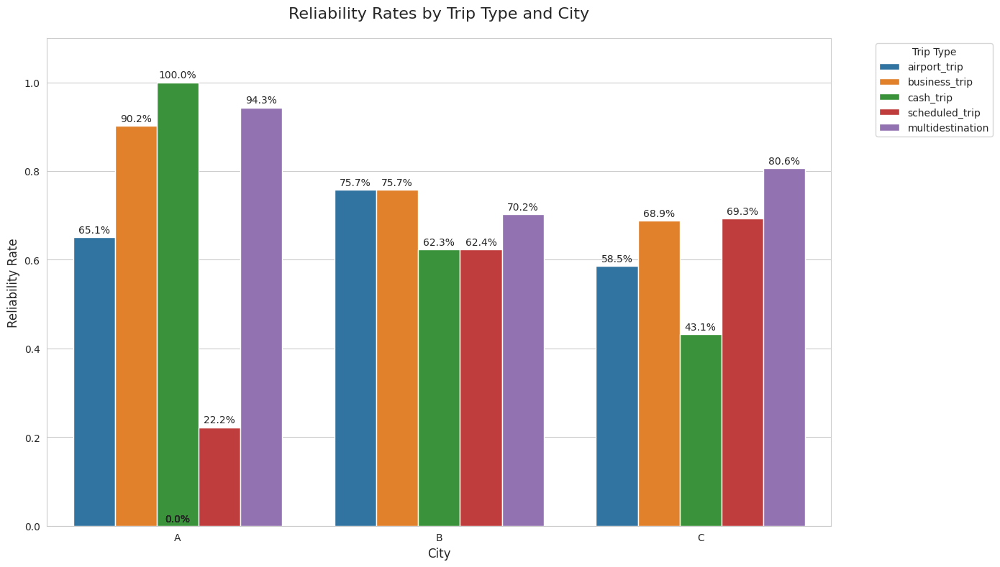

In [273]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare the data (using final_results from previous calculation)
plt.figure(figsize=(14, 8))
ax = sns.barplot(data=final_results, x='city', y='reliability_rate', hue='trip_type')

# Add values on top of each bar
for p in ax.patches:
    height = p.get_height()
    ax.text(x=p.get_x() + p.get_width()/2.,
            y=height + 0.01,
            s=f'{height:.1%}',
            ha='center',
            fontsize=10)

# Customize the plot
plt.title('Reliability Rates by Trip Type and City', pad=20, fontsize=16)
plt.ylabel('Reliability Rate', fontsize=12)
plt.xlabel('City', fontsize=12)
plt.ylim(0, 1.1)  # Leave space for value labels
plt.legend(title='Trip Type', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [270]:
rider_sessions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145447 entries, 0 to 145446
Data columns (total 31 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   rider_session_id                     145447 non-null  object        
 1   session_start_timestamp_local        142822 non-null  datetime64[ns]
 2   rider_id                             145447 non-null  object        
 3   city                                 145447 non-null  object        
 4   app_version                          145447 non-null  object        
 5   duration_ms                          145447 non-null  float64       
 6   session_last_eta                     130958 non-null  float64       
 7   session_last_surge_multiplier        134118 non-null  float64       
 8   session_last_fare_local              132932 non-null  float64       
 9   session_average_trip_distance_miles  145447 non-null  float64       
 

### XGBoost

In [256]:
final.columns

Index(['city', 'request_id', 'request_timestamp_local', 'hour_bin',
       'request_status', 'request_product_name', 'is_airport_trip',
       'is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
       'is_multidestination', 'is_matched', 'is_reliable_pickup',
       'reliability_status', 'hour', 'day_of_week',
       'request_client_fare_local', 'request_surge_multiplier',
       'post_dispatch_eta', 'ata', 'est_rider_fare_distance_miles',
       'trip_distance_miles', 'trip_duration_seconds',
       'cancellation_fee_local', 'active_drivers', 'requests', 'SDIR',
       'request_price_per_est_mile', 'offered_eta', 'dispatch_length_km',
       'matching_time_spend_sec', 'acceptance_count', 'decline_count',
       'cancellation_count', 'total_count', 'avg_unavailable_time_minutes',
       'avg_open_time_minutes'],
      dtype='object')

In [257]:
# Count NA values per column and sort in descending order
null_counts = final.isna().sum().sort_values(ascending=False)

# Display columns with nulls (excluding columns with 0 nulls)
print("Null counts per column (descending order):")
print(null_counts[null_counts > 0])

Null counts per column (descending order):
ata                              19956
post_dispatch_eta                 9450
dispatch_length_km                3127
offered_eta                       3127
matching_time_spend_sec           3127
est_rider_fare_distance_miles      615
request_price_per_est_mile         615
dtype: int64


In [258]:
# # predictors
# # 'city', 'request_product_name', 'is_airport_trip',
# 'is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
# 'is_multidestination','request_client_fare_local',
# 'request_surge_multiplier',  'hour',
#  'day_of_week','post_dispatch_eta', 'est_rider_fare_distance_miles',
# 'trip_distance_miles', 'trip_duration_seconds',
# 'cancellation_fee_local', 'active_drivers', 'requests', 'SDIR',
# 'request_price_per_est_mile', 'offered_eta', 'dispatch_length_km',
# 'matching_time_spend_sec', 'acceptance_count', 'decline_count',
# 'cancellation_count', 'total_count', 'avg_active_time_minutes',
# 'avg_enroute_time_minutes', 'avg_ontrip_time_minutes',
# 'avg_open_time_minutes', 'avg_unavailable_time_minutes',
# 'avg_enroute_ontrip_ratio', 'avg_active_open_ratio'

# #Predictor:  'is_reliable_pickup',]

In [278]:
final2 = final.copy()

final2 = final2[final2['post_dispatch_eta'].notna()]

In [279]:
final.groupby(['city', 'request_status']).size().unstack()

request_status,completed,driver_canceled,failed,rider_canceled,unfulfilled
city,,,,,
A,33754.0,185.0,NaN,2596.0,318.0
B,20218.0,464.0,1.0,6688.0,1406.0
C,10995.0,256.0,2.0,4679.0,732.0


In [280]:
final2.groupby(['city', 'request_status']).size().unstack()

request_status,completed,driver_canceled,rider_canceled,unfulfilled
city,,,,
A,33754,185,1367,7
B,20218,464,3822,188
C,10995,256,1510,78


In [281]:
final2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 72844 entries, 0 to 82292
Data columns (total 37 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   city                           72844 non-null  object        
 1   request_id                     72844 non-null  object        
 2   request_timestamp_local        72844 non-null  datetime64[ns]
 3   hour_bin                       72844 non-null  datetime64[ns]
 4   request_status                 72844 non-null  object        
 5   request_product_name           72844 non-null  object        
 6   is_airport_trip                72844 non-null  bool          
 7   is_business_trip               72844 non-null  bool          
 8   is_cash_trip                   72844 non-null  bool          
 9   is_scheduled_trip              72844 non-null  bool          
 10  is_multidestination            72844 non-null  bool          
 11  is_matched          

In [282]:
# Count NA values per column and sort in descending order
null_counts = final2.isna().sum().sort_values(ascending=False)

# Display columns with nulls (excluding columns with 0 nulls)
print("Null counts per column (descending order):")
print(null_counts[null_counts > 0])

Null counts per column (descending order):
ata                              10506
est_rider_fare_distance_miles      529
request_price_per_est_mile         529
offered_eta                         51
dispatch_length_km                  51
matching_time_spend_sec             51
dtype: int64


In [283]:
final2.request_status.unique()

array(['completed', 'rider_canceled', 'driver_canceled', 'unfulfilled'],
      dtype=object)

In [284]:
final2 = final2[final2['est_rider_fare_distance_miles'].notna()]

In [285]:
final2.groupby(['city', 'request_status']).size().unstack()

request_status,completed,driver_canceled,rider_canceled,unfulfilled
city,,,,
A,33282,180,1343,7
B,20213,462,3813,188
C,10993,254,1502,78


In [286]:
final2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 72315 entries, 0 to 82292
Data columns (total 37 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   city                           72315 non-null  object        
 1   request_id                     72315 non-null  object        
 2   request_timestamp_local        72315 non-null  datetime64[ns]
 3   hour_bin                       72315 non-null  datetime64[ns]
 4   request_status                 72315 non-null  object        
 5   request_product_name           72315 non-null  object        
 6   is_airport_trip                72315 non-null  bool          
 7   is_business_trip               72315 non-null  bool          
 8   is_cash_trip                   72315 non-null  bool          
 9   is_scheduled_trip              72315 non-null  bool          
 10  is_multidestination            72315 non-null  bool          
 11  is_matched          

In [287]:
# Count NA values per column and sort in descending order
null_counts = final2.isna().sum().sort_values(ascending=False)

# Display columns with nulls (excluding columns with 0 nulls)
print("Null counts per column (descending order):")
print(null_counts[null_counts > 0])

Null counts per column (descending order):
ata                        10435
offered_eta                   49
dispatch_length_km            49
matching_time_spend_sec       49
dtype: int64


In [288]:
final3 = final2[final2['offered_eta'].notna()]
# Count NA values per column and sort in descending order
null_counts = final3.isna().sum().sort_values(ascending=False)

# Display columns with nulls (excluding columns with 0 nulls)
print("Null counts per column (descending order):")
print(null_counts[null_counts > 0])


Null counts per column (descending order):
ata    10413
dtype: int64


In [289]:
final3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 72266 entries, 0 to 82292
Data columns (total 37 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   city                           72266 non-null  object        
 1   request_id                     72266 non-null  object        
 2   request_timestamp_local        72266 non-null  datetime64[ns]
 3   hour_bin                       72266 non-null  datetime64[ns]
 4   request_status                 72266 non-null  object        
 5   request_product_name           72266 non-null  object        
 6   is_airport_trip                72266 non-null  bool          
 7   is_business_trip               72266 non-null  bool          
 8   is_cash_trip                   72266 non-null  bool          
 9   is_scheduled_trip              72266 non-null  bool          
 10  is_multidestination            72266 non-null  bool          
 11  is_matched          

In [290]:
final3[['request_timestamp_local', 'hour' , 'day_of_week' ]]

,request_timestamp_local,hour,day_of_week
0,2023-04-05 00:46:22,00:00:00,2
1,2023-04-16 19:34:26,19:00:00,6
2,2023-04-15 20:35:11,20:00:00,5
3,2023-04-21 18:38:24,18:00:00,4
4,2023-04-20 19:54:24,19:00:00,3
...,...,...,...
82279,2023-04-15 14:57:23,14:00:00,5
82282,2023-04-02 01:41:02,01:00:00,6
82288,2023-04-11 20:22:58,20:00:00,1
82289,2023-04-18 12:01:56,12:00:00,1


In [291]:

final3['hour_int'] = pd.to_datetime(final3['hour'], errors='coerce').dt.hour

final3[['request_timestamp_local', 'hour' , 'hour_int' ]]

<ipython-input-291-e9280109d2c9>:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  final3['hour_int'] = pd.to_datetime(final3['hour'], errors='coerce').dt.hour
<ipython-input-291-e9280109d2c9>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final3['hour_int'] = pd.to_datetime(final3['hour'], errors='coerce').dt.hour


,request_timestamp_local,hour,hour_int
0,2023-04-05 00:46:22,00:00:00,0
1,2023-04-16 19:34:26,19:00:00,19
2,2023-04-15 20:35:11,20:00:00,20
3,2023-04-21 18:38:24,18:00:00,18
4,2023-04-20 19:54:24,19:00:00,19
...,...,...,...
82279,2023-04-15 14:57:23,14:00:00,14
82282,2023-04-02 01:41:02,01:00:00,1
82288,2023-04-11 20:22:58,20:00:00,20
82289,2023-04-18 12:01:56,12:00:00,12


In [292]:
#categorical : city,  request_product_name

final3.request_product_name.unique()

requested_rides2.groupby(['city', 'request_product_name']).size().unstack()

request_product_name,Black,Low Cost,Mid-Tier,RiderItemDelivery,SUV,UberX,UberXL,taxi
city,,,,,,,,
A,3.0,35.0,NaN,14.0,NaN,36803.0,NaN,NaN
B,3.0,NaN,4.0,10.0,NaN,28162.0,773.0,NaN
C,1.0,NaN,4.0,NaN,8.0,16803.0,NaN,1.0


In [293]:
city_mapping = {'A': 0, 'B': 1, 'C': 2}
final3['city_encoded'] = final3['city'].map(city_mapping)

<ipython-input-293-dd7c9ae76a54>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final3['city_encoded'] = final3['city'].map(city_mapping)


In [294]:
final3[['city', 'city_encoded']]

,city,city_encoded
0,C,2
1,B,1
2,C,2
3,A,0
4,A,0
...,...,...
82279,C,2
82282,C,2
82288,C,2
82289,C,2


In [295]:
product_mapping = {'UberX': 0, 'UberXL': 1 }
final3['product_type'] = final3['request_product_name'].map(product_mapping)

final3[final3['product_type'] ==1 ][['product_type', 'request_product_name']].head(5)

<ipython-input-295-2e9bc983c209>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final3['product_type'] = final3['request_product_name'].map(product_mapping)


,product_type,request_product_name
823,1,UberXL
1674,1,UberXL
3147,1,UberXL
4062,1,UberXL
4230,1,UberXL


In [296]:
final3.columns

Index(['city', 'request_id', 'request_timestamp_local', 'hour_bin',
       'request_status', 'request_product_name', 'is_airport_trip',
       'is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
       'is_multidestination', 'is_matched', 'is_reliable_pickup',
       'reliability_status', 'hour', 'day_of_week',
       'request_client_fare_local', 'request_surge_multiplier',
       'post_dispatch_eta', 'ata', 'est_rider_fare_distance_miles',
       'trip_distance_miles', 'trip_duration_seconds',
       'cancellation_fee_local', 'active_drivers', 'requests', 'SDIR',
       'request_price_per_est_mile', 'offered_eta', 'dispatch_length_km',
       'matching_time_spend_sec', 'acceptance_count', 'decline_count',
       'cancellation_count', 'total_count', 'avg_unavailable_time_minutes',
       'avg_open_time_minutes', 'hour_int', 'city_encoded', 'product_type'],
      dtype='object')

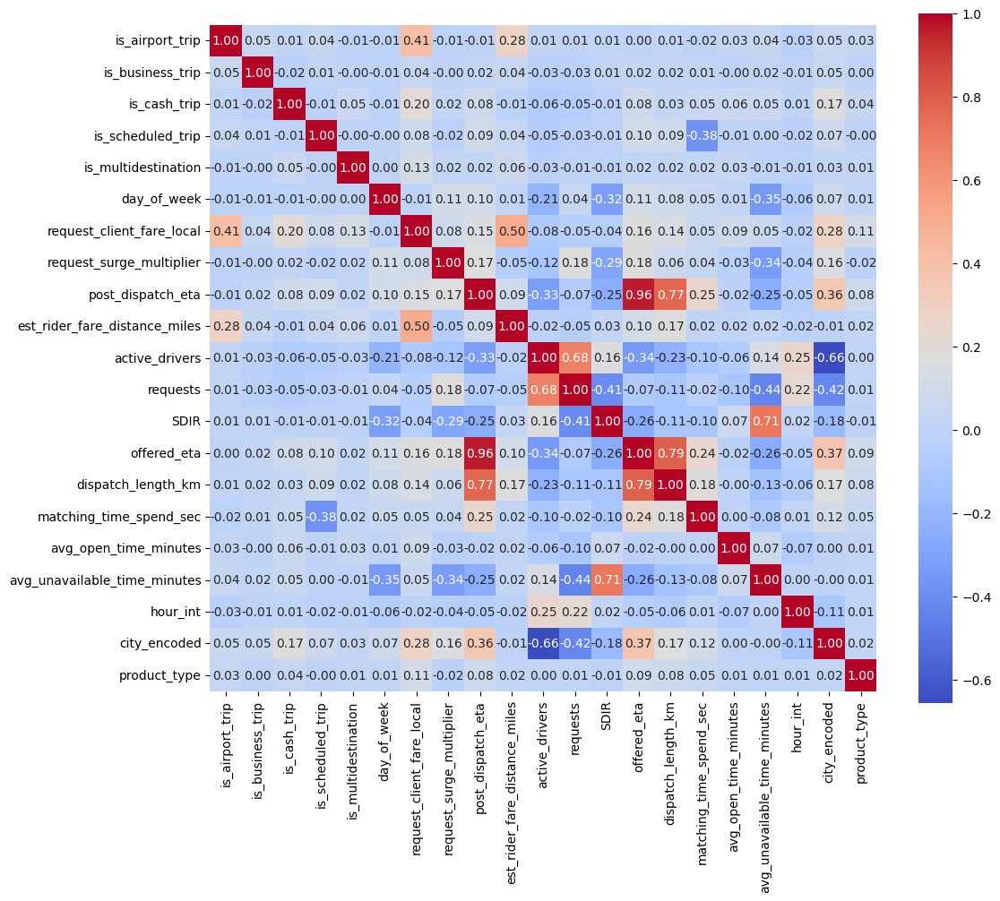

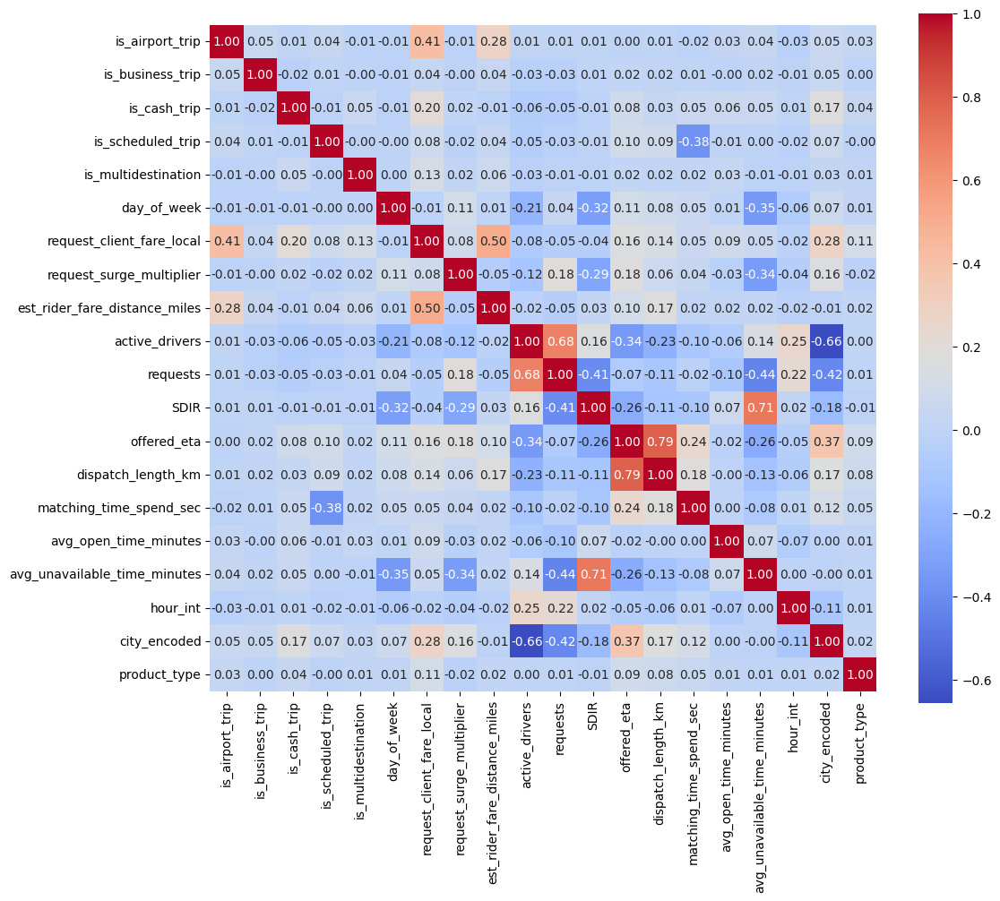

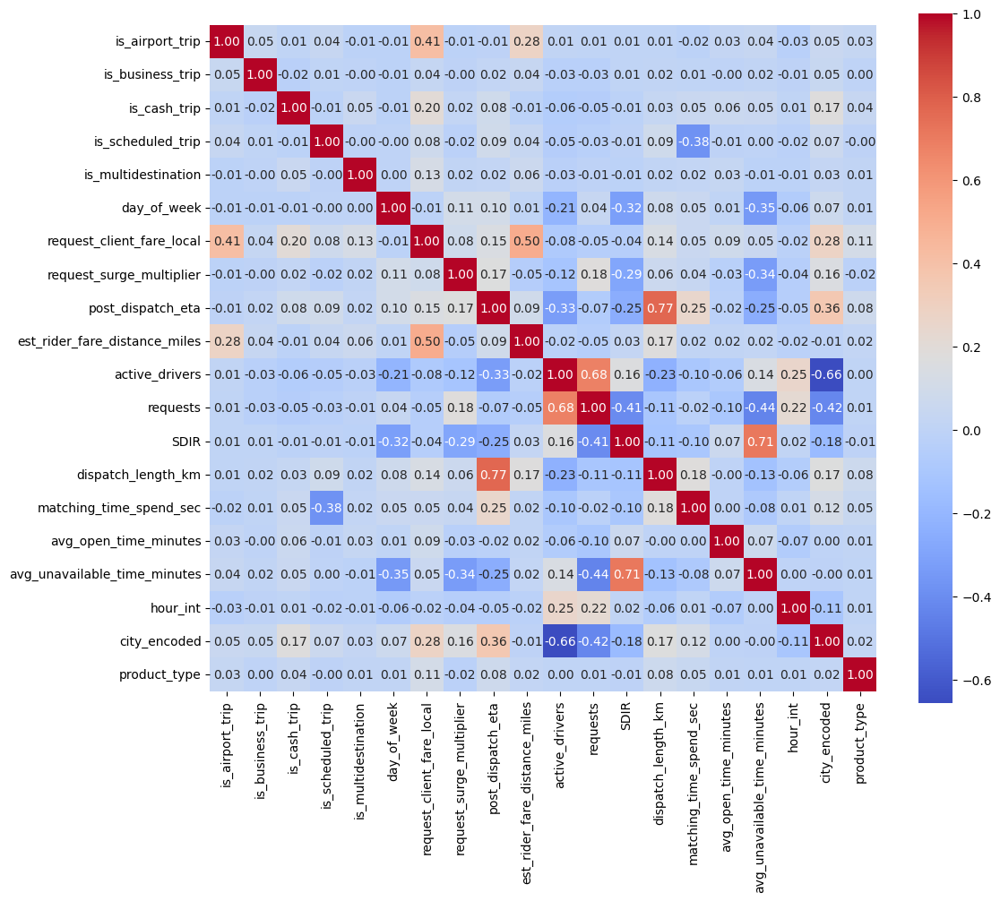

In [148]:
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor


def cor_mat(data):
  corr_matrix = data.corr()
  plt.figure(figsize=(12, 10))
  sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True)


X = final3[['is_airport_trip','is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
       'is_multidestination', 'day_of_week',
       'request_client_fare_local', 'request_surge_multiplier',
       'post_dispatch_eta', 'est_rider_fare_distance_miles',
       'active_drivers', 'requests', 'SDIR', 'offered_eta', 'dispatch_length_km',
       'matching_time_spend_sec', 'avg_open_time_minutes', 'avg_unavailable_time_minutes', 'hour_int',
       'city_encoded', 'product_type']]

cor_mat(X)



X2= final3[['is_airport_trip','is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
       'is_multidestination', 'day_of_week',
       'request_client_fare_local', 'request_surge_multiplier', 'est_rider_fare_distance_miles',
       'active_drivers', 'requests', 'SDIR', 'offered_eta', 'dispatch_length_km',
       'matching_time_spend_sec', 'avg_open_time_minutes', 'avg_unavailable_time_minutes', 'hour_int',
       'city_encoded', 'product_type']]


X3 = final3[['is_airport_trip','is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
       'is_multidestination', 'day_of_week',
       'request_client_fare_local', 'request_surge_multiplier',
       'post_dispatch_eta', 'est_rider_fare_distance_miles',
       'active_drivers', 'requests', 'SDIR', 'dispatch_length_km',
       'matching_time_spend_sec',
       'avg_open_time_minutes', 'avg_unavailable_time_minutes', 'hour_int',
       'city_encoded', 'product_type']]


cor_mat(X2)
cor_mat(X3)



y = final3['is_reliable_pickup']


In [138]:

X_train, X_test, y_train, y_test = train_test_split(X2, y, test_size=0.2, stratify=y, random_state=42)

In [139]:
import xgboost as xgb
from xgboost import plot_importance

model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model.fit(X_train, y_train)

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [13:47:00] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

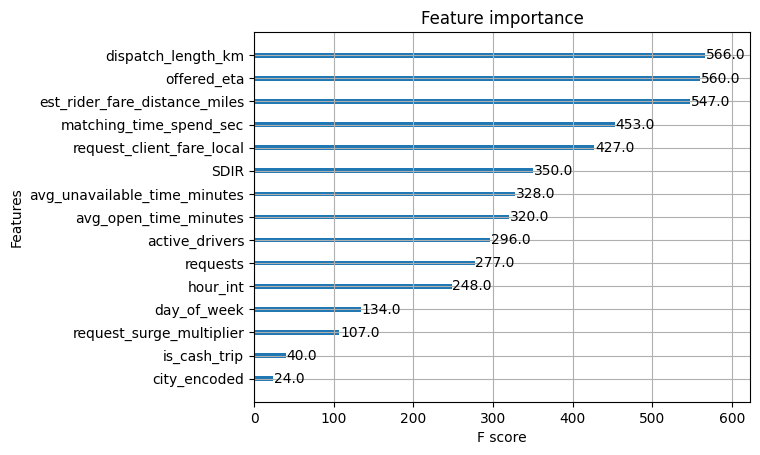

In [140]:
import matplotlib.pyplot as plt

plot_importance(model, max_num_features=15)
plt.show()

100%|===================| 57678/57812 [04:37<00:00]       

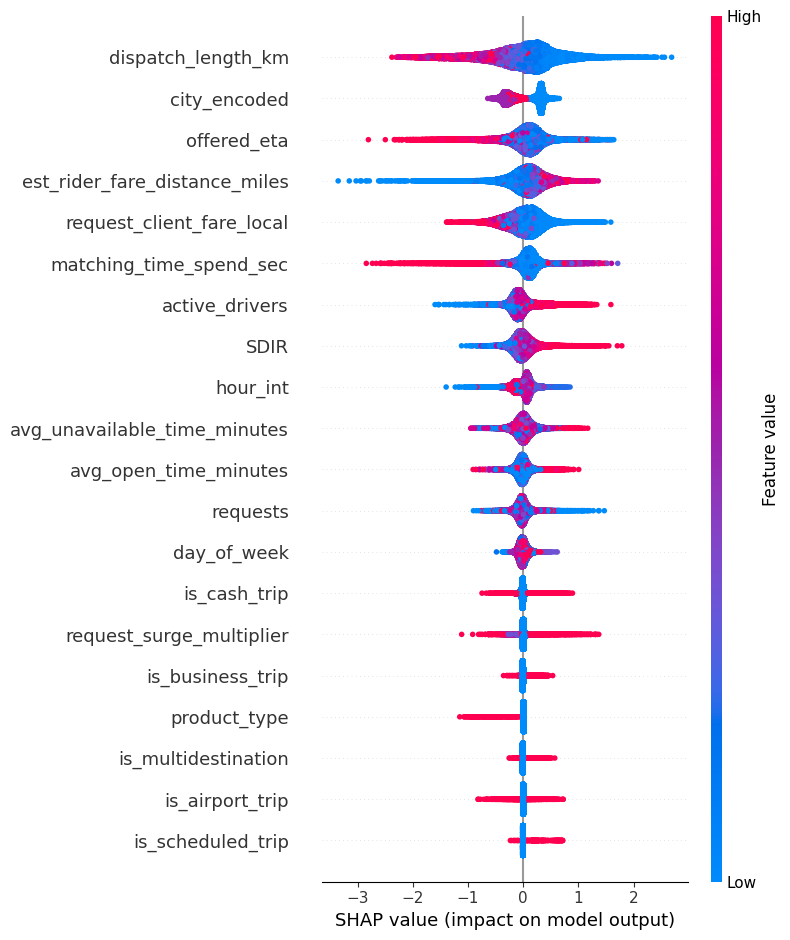

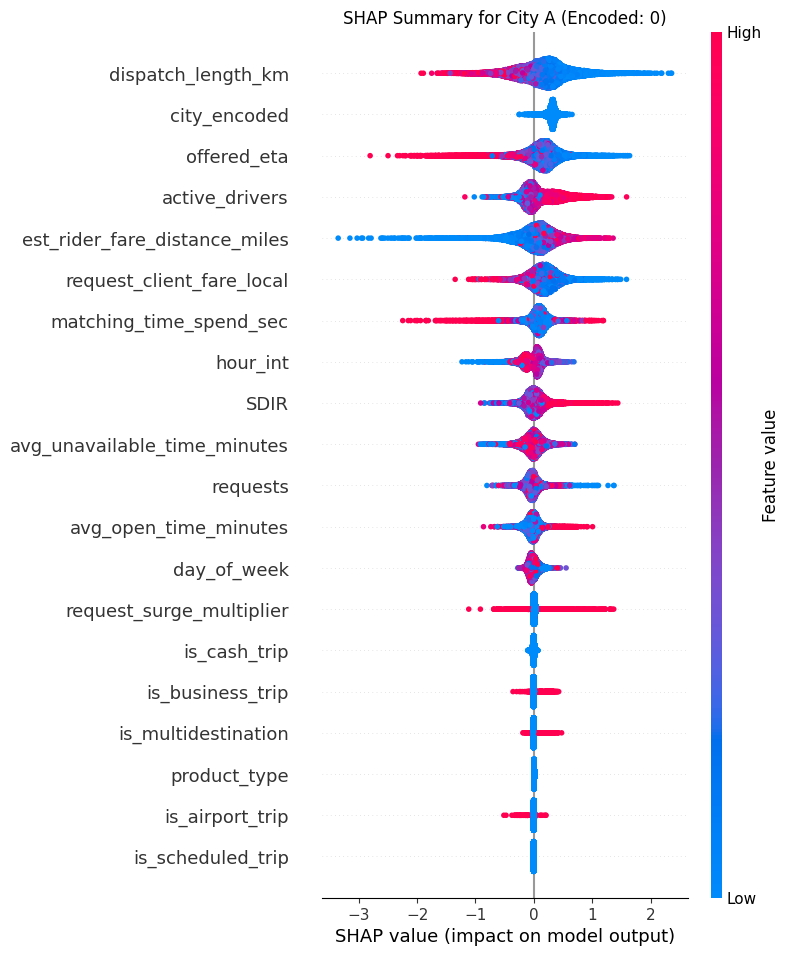

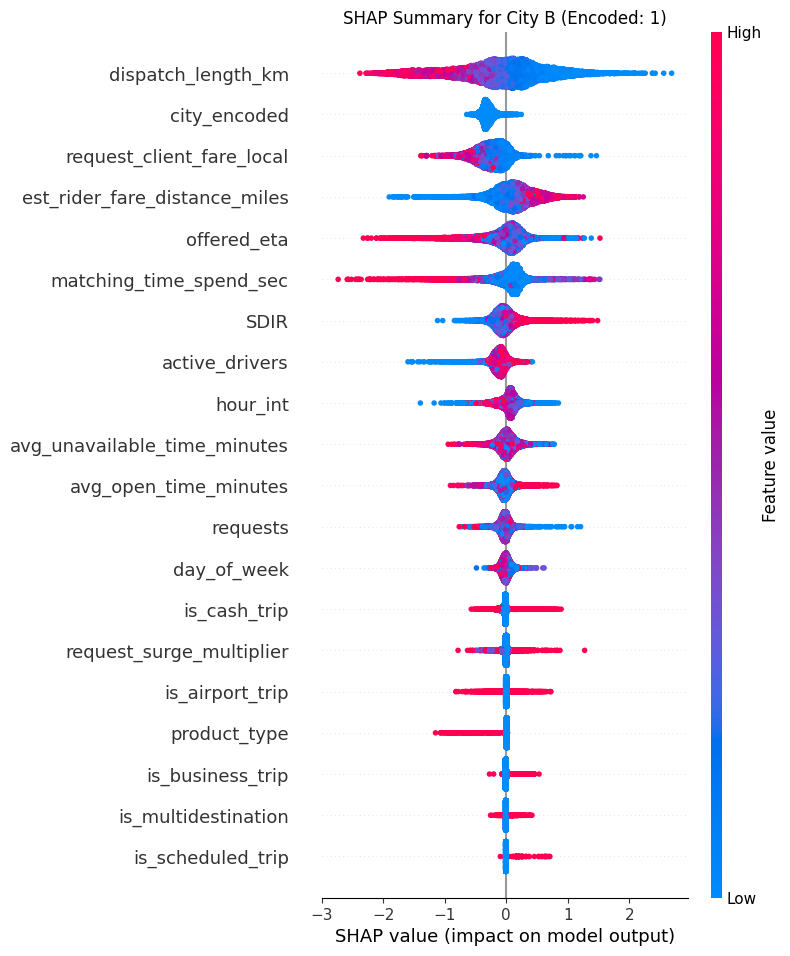

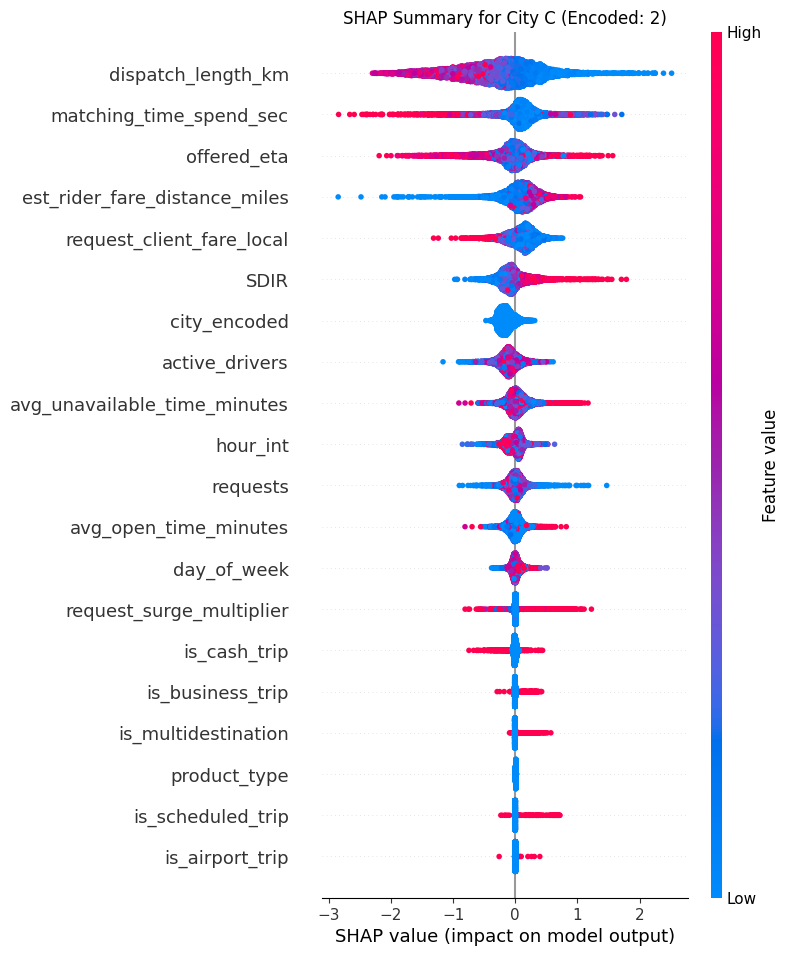

In [141]:
import shap

X_train = X_train.astype('float64')
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_train)

shap.summary_plot(shap_values, X_train)

city_mapping = {'A': 0, 'B': 1, 'C': 2}

# SHAP analysis per city using city_encoded
for city, code in city_mapping.items():
    city_idx = (X_train['city_encoded'] == code).values

    if sum(city_idx) > 0:  # Only plot if city exists in data
        shap.summary_plot(
            shap_values[city_idx],
            X_train.iloc[city_idx],
            show=False
        )
        plt.title(f"SHAP Summary for City {city} (Encoded: {code})")
        plt.show()

In [143]:
from sklearn.metrics import accuracy_score

# Predict on test set
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Print result
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9048


In [149]:
import xgboost as xgb
from xgboost import plot_importance
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import train_test_split
import shap
import matplotlib.pyplot as plt

def initial_model_training_testing_weighted(df, X_col, y_col, city):

  city_df = df[df['city'] == city]
  X = city_df[X_col]
  y = city_df[y_col]

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


  weight = sum(y== False) / sum(y == True)

  model = xgb.XGBClassifier(use_label_encoder=False,scale_pos_weight=weight, eval_metric='logloss')
  model.fit(X_train, y_train)


  # Select features based on importance
  selector = SelectFromModel(model, threshold='median', prefit=True)
  X_train_selected = selector.transform(X_train)
  X_test_selected = selector.transform(X_test)

  # Check selected features
  selected_features = X_train.columns[selector.get_support()]
  print(f"Best features for City {city} ")
  print(selected_features)

  plot_importance(model, max_num_features=15)
  plt.show()

  X_train = X_train.astype('float64')
  explainer = shap.Explainer(model, X_train)
  shap_values = explainer(X_train)

  print(f"SHAP Summary for City {city} ")
  shap.summary_plot(shap_values, X_train)

  # Predict on test set
  y_pred = model.predict(X_test)

  # Calculate accuracy
  accuracy = accuracy_score(y_test, y_pred)

  # Print result
  print(f"Accuracy for default XGBoost model: {accuracy:.4f}")

  return selected_features, X_train_selected, X_test_selected, y_train, y_test





<class 'pandas.core.frame.DataFrame'>
Index: 72266 entries, 0 to 82292
Data columns (total 40 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   city                           72266 non-null  object        
 1   request_id                     72266 non-null  object        
 2   request_timestamp_local        72266 non-null  datetime64[ns]
 3   hour_bin                       72266 non-null  datetime64[ns]
 4   request_status                 72266 non-null  object        
 5   request_product_name           72266 non-null  object        
 6   is_airport_trip                72266 non-null  boolean       
 7   is_business_trip               72266 non-null  boolean       
 8   is_cash_trip                   72266 non-null  boolean       
 9   is_scheduled_trip              72266 non-null  boolean       
 10  is_multidestination            72266 non-null  boolean       
 11  is_matched          

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [14:31:58] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


Best features for City A 
Index(['is_multidestination', 'day_of_week', 'request_client_fare_local',
       'est_rider_fare_distance_miles', 'active_drivers', 'SDIR',
       'offered_eta', 'matching_time_spend_sec',
       'avg_unavailable_time_minutes', 'hour_int'],
      dtype='object')


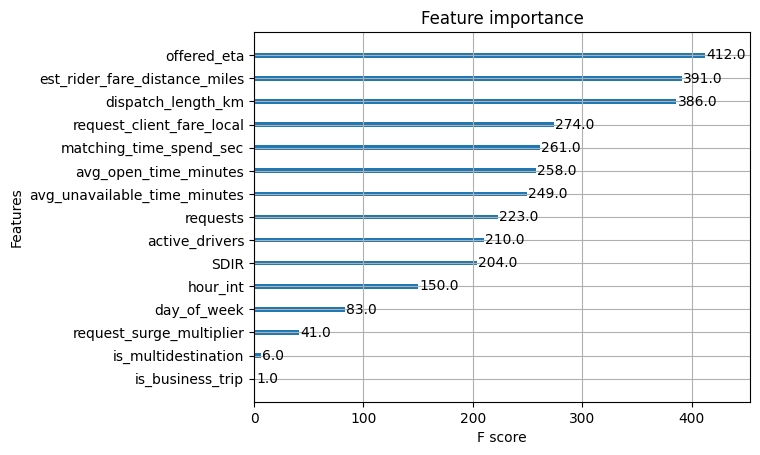

100%|===================| 27747/27838 [02:07<00:00]       

SHAP Summary for City A 


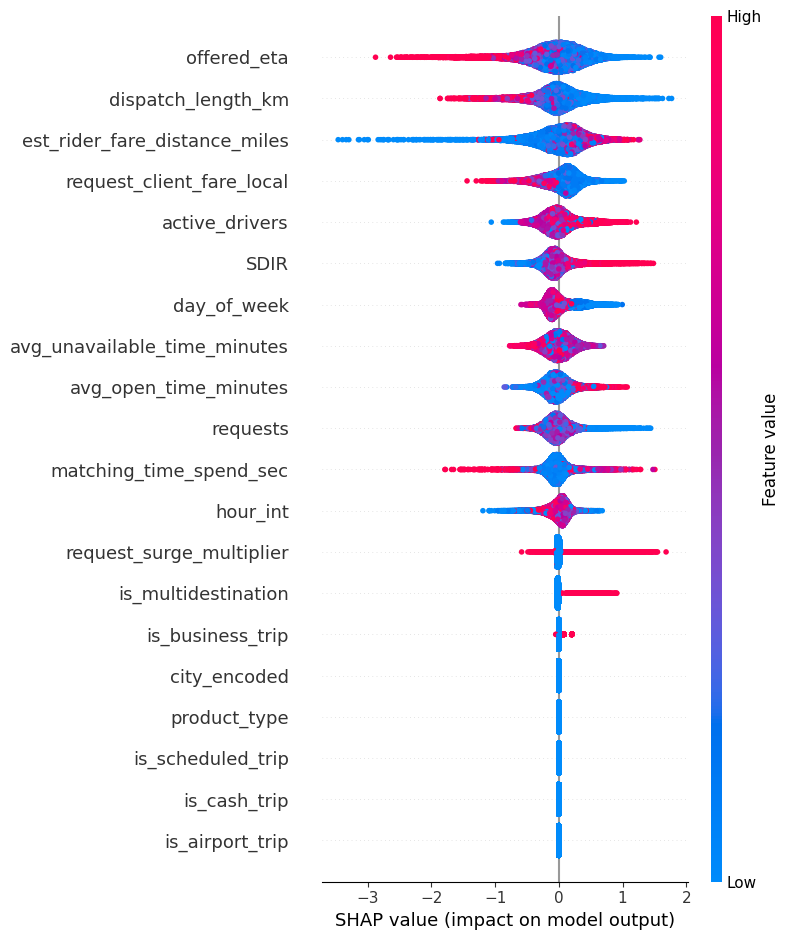

Accuracy for default XGBoost model: 0.8572


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [14:34:13] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


Best features for City B 
Index(['is_airport_trip', 'is_cash_trip', 'est_rider_fare_distance_miles',
       'active_drivers', 'SDIR', 'offered_eta', 'dispatch_length_km',
       'matching_time_spend_sec', 'hour_int', 'product_type'],
      dtype='object')


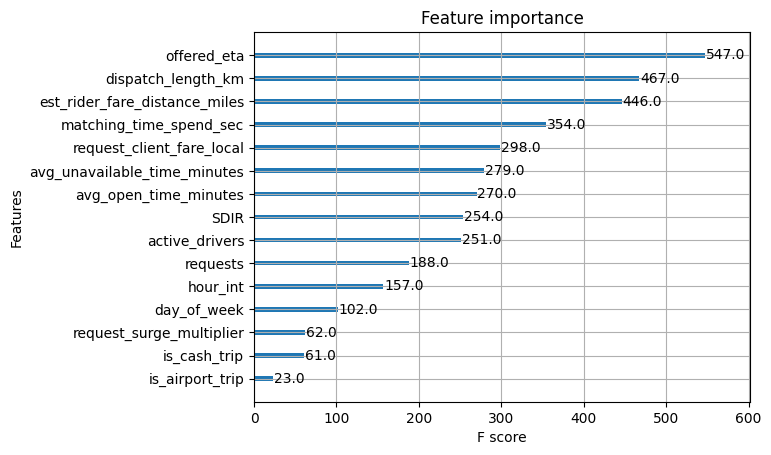

 99%|===================| 19591/19729 [01:29<00:00]       

SHAP Summary for City B 


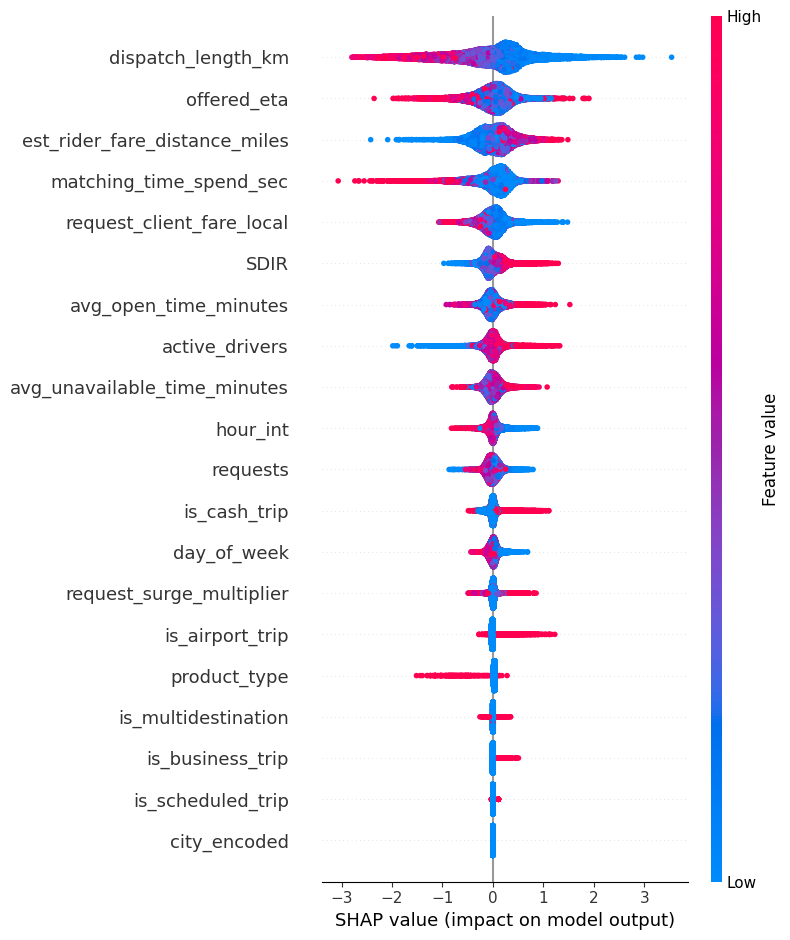

Accuracy for default XGBoost model: 0.7790


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [14:35:49] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


Best features for City C 
Index(['is_multidestination', 'day_of_week', 'request_client_fare_local',
       'est_rider_fare_distance_miles', 'active_drivers', 'SDIR',
       'offered_eta', 'dispatch_length_km', 'matching_time_spend_sec',
       'avg_unavailable_time_minutes'],
      dtype='object')


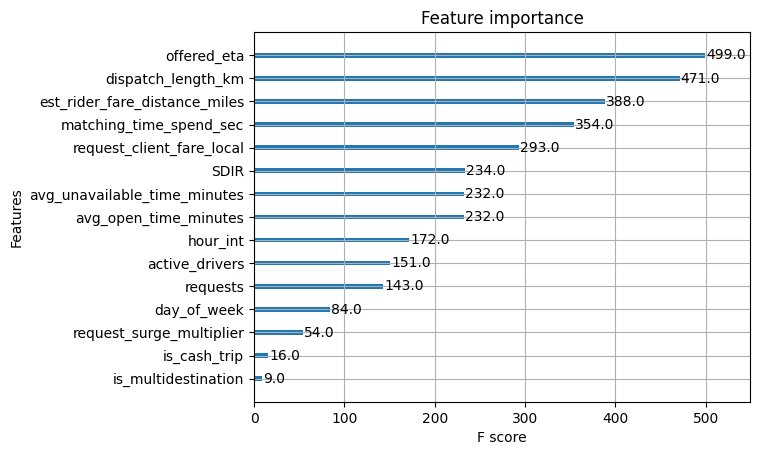

100%|===================| 10219/10244 [00:51<00:00]       

SHAP Summary for City C 


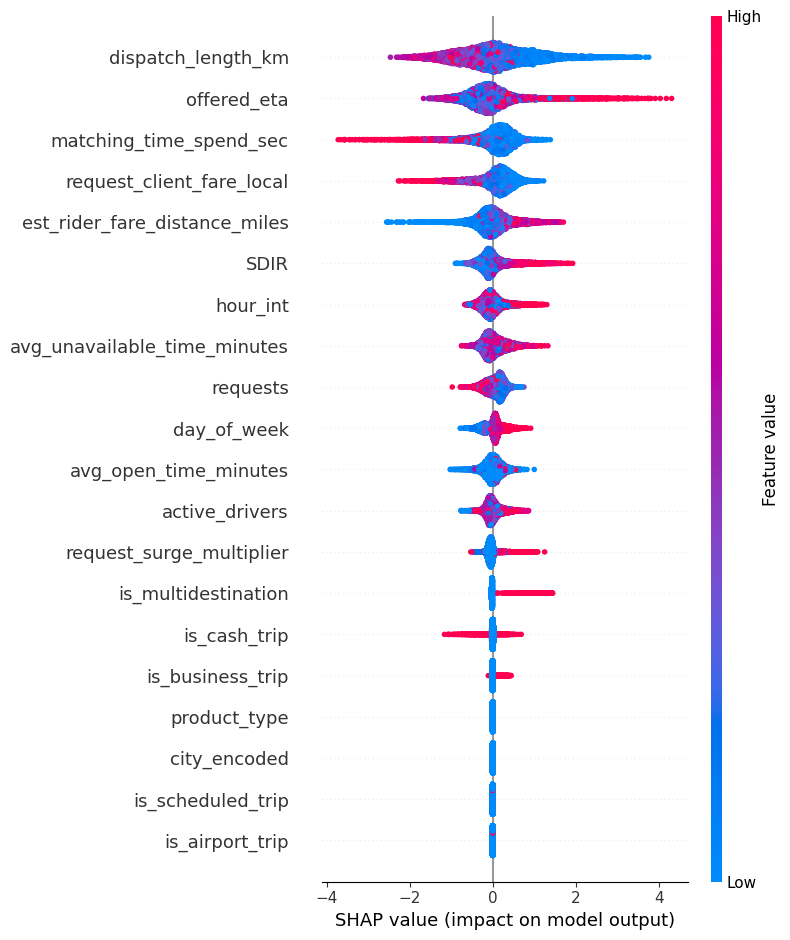

Accuracy for default XGBoost model: 0.8169


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [14:36:45] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


Best features for City A 
Index(['day_of_week', 'request_client_fare_local', 'post_dispatch_eta',
       'est_rider_fare_distance_miles', 'SDIR', 'dispatch_length_km',
       'matching_time_spend_sec', 'avg_open_time_minutes',
       'avg_unavailable_time_minutes', 'hour_int'],
      dtype='object')


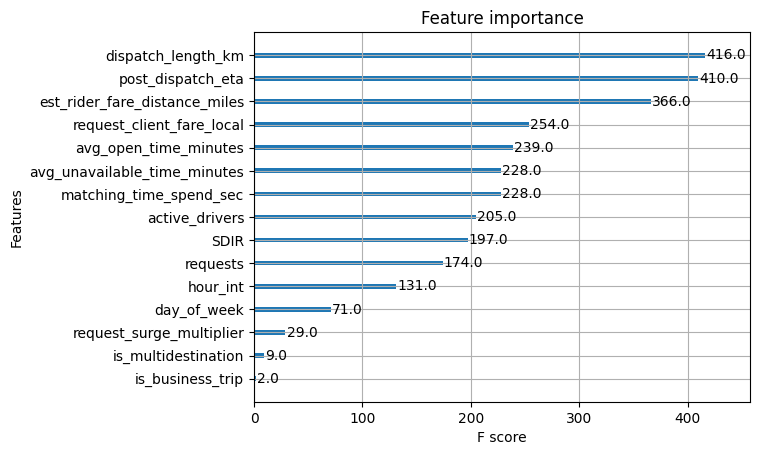

100%|===================| 27761/27838 [01:57<00:00]       

SHAP Summary for City A 


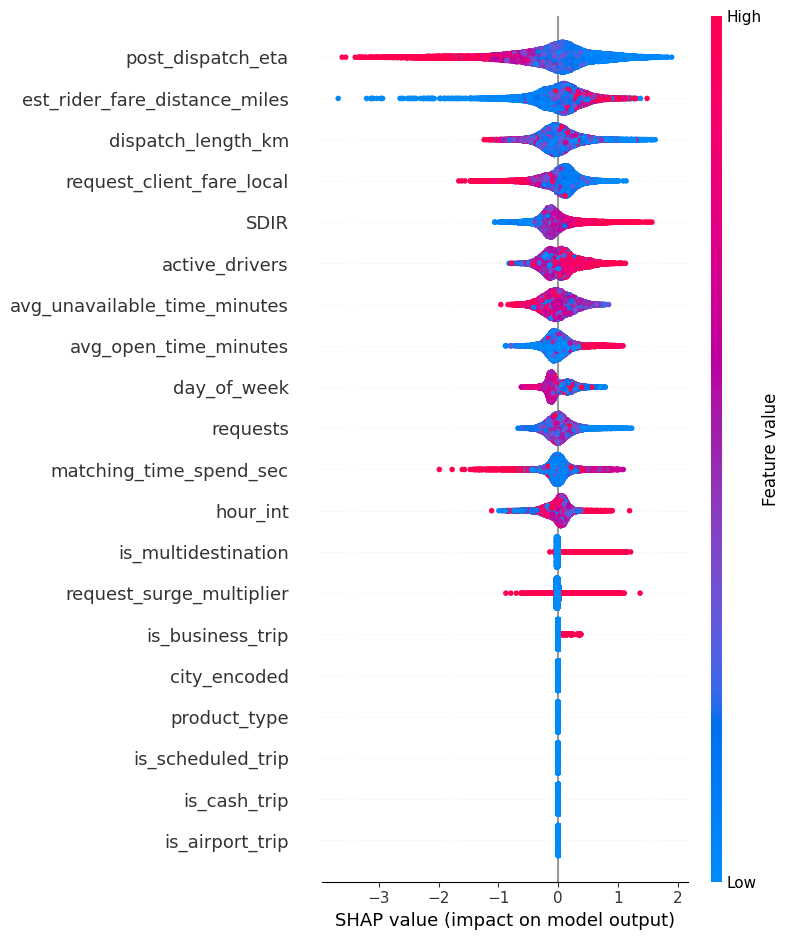

Accuracy for default XGBoost model: 0.8575


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [14:38:49] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


Best features for City B 
Index(['is_airport_trip', 'is_cash_trip', 'is_multidestination',
       'post_dispatch_eta', 'est_rider_fare_distance_miles', 'active_drivers',
       'dispatch_length_km', 'matching_time_spend_sec', 'hour_int',
       'product_type'],
      dtype='object')


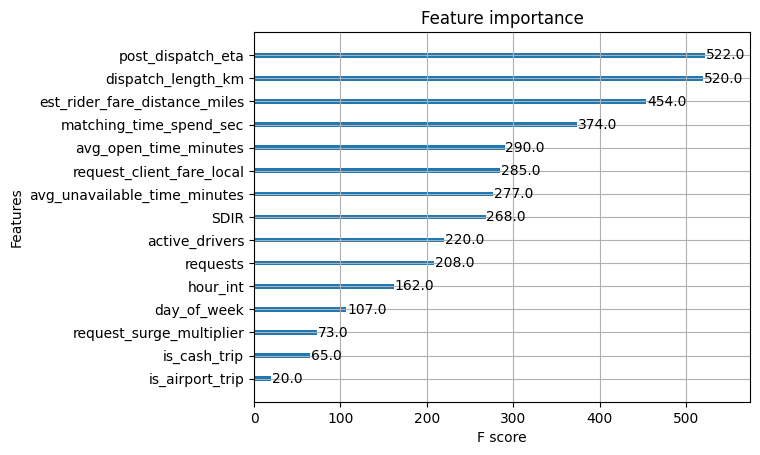

 99%|===================| 19627/19729 [01:31<00:00]       

SHAP Summary for City B 


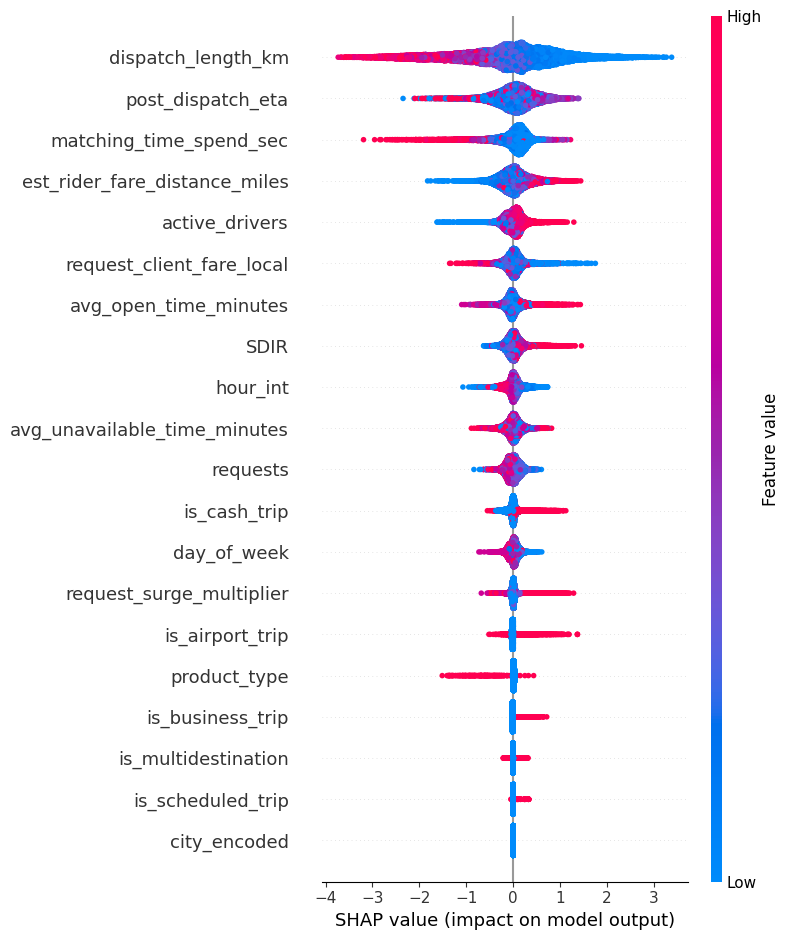

Accuracy for default XGBoost model: 0.7902


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [14:40:25] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


Best features for City C 
Index(['is_cash_trip', 'is_scheduled_trip', 'is_multidestination',
       'request_client_fare_local', 'post_dispatch_eta',
       'est_rider_fare_distance_miles', 'active_drivers', 'dispatch_length_km',
       'matching_time_spend_sec', 'avg_unavailable_time_minutes'],
      dtype='object')


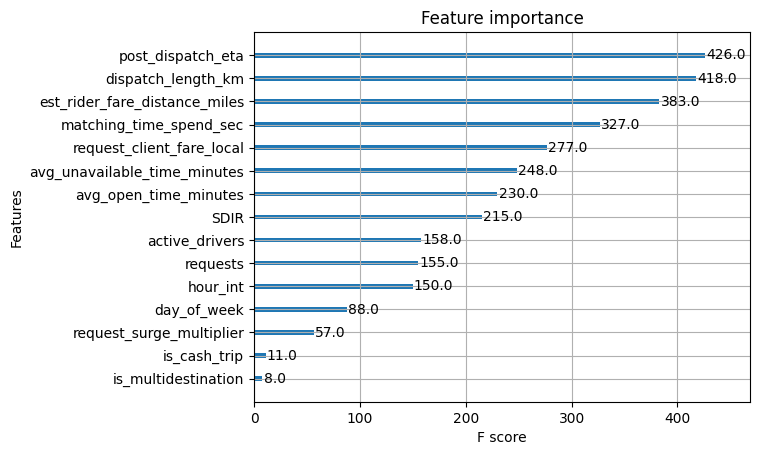

100%|===================| 10241/10244 [00:47<00:00]       

SHAP Summary for City C 


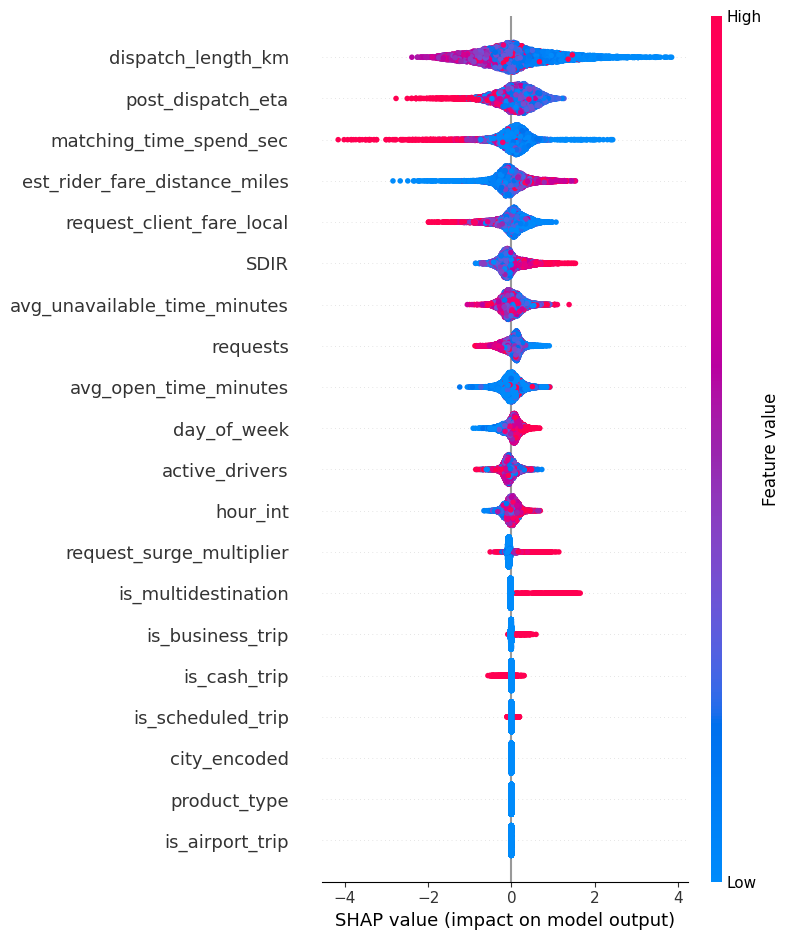

Accuracy for default XGBoost model: 0.8080


In [282]:

X2= ['is_airport_trip','is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
       'is_multidestination', 'day_of_week',
       'request_client_fare_local', 'request_surge_multiplier', 'est_rider_fare_distance_miles',
       'active_drivers', 'requests', 'SDIR', 'offered_eta', 'dispatch_length_km',
       'matching_time_spend_sec', 'avg_open_time_minutes', 'avg_unavailable_time_minutes', 'hour_int',
       'city_encoded', 'product_type']


X3 = ['is_airport_trip','is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
       'is_multidestination', 'day_of_week',
       'request_client_fare_local', 'request_surge_multiplier',
       'post_dispatch_eta', 'est_rider_fare_distance_miles',
       'active_drivers', 'requests', 'SDIR', 'dispatch_length_km',
       'matching_time_spend_sec',
       'avg_open_time_minutes', 'avg_unavailable_time_minutes', 'hour_int',
       'city_encoded', 'product_type']



y_col = 'is_reliable_pickup'

final3.info()

for city in ['A', 'B', 'C']:
  initial_model_training_testing_weighted(final3, X2, y_col, city)


for city in ['A', 'B', 'C']:
  initial_model_training_testing_weighted(final3, X3, y_col, city)

In [301]:
import xgboost as xgb
from xgboost import plot_importance
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import train_test_split
import shap
import matplotlib.pyplot as plt

def initial_model_training_testing(df, X_col, y_col):
  X = df[X_col]
  y = df[y_col]

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

  model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
  model.fit(X_train, y_train)


  # Select features based on importance
  selector = SelectFromModel(model, threshold='median', prefit=True)
  X_train_selected = selector.transform(X_train)
  X_test_selected = selector.transform(X_test)

  # Check selected features
  selected_features = X_train.columns[selector.get_support()]
  print(f"Best features for City {city} ")
  print(selected_features)

  plot_importance(model, max_num_features=15)
  plt.show()

  # X_train = X_train.astype('float64')
  # explainer = shap.Explainer(model, X_train)
  # shap_values = explainer(X_train)

  # print(f"SHAP Summary for City {city} ")
  # shap.summary_plot(shap_values, X_train)


  y_pred = model.predict(X_test)

  accuracy = accuracy_score(y_test, y_pred)

  print(f"Accuracy for default XGBoost model: {accuracy:.4f}")

  return selected_features, X_train_selected, X_test_selected, y_train, y_test







In [304]:

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint
from sklearn.metrics import accuracy_score


def parameter_tunning(X_train_selected, y_train):

  # Define model
  model = xgb.XGBClassifier(
    use_label_encoder=False,
    eval_metric='logloss',
    importance_type='gain'  # More stable than default 'weight'
)

  # Define hyperparameter grid
  param_dist = {
    'n_estimators': randint(50, 300),
    'max_depth': randint(3, 10),
    'learning_rate': uniform(0.01, 0.3),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4)}

  # Randomized Search
  random_search = RandomizedSearchCV(model, param_distributions=param_dist,
                                   n_iter=50, scoring='accuracy',
                                   cv=3, verbose=2, n_jobs=-1, random_state=42)

  random_search.fit(X_train_selected, y_train)
  best_model = random_search.best_estimator_

  # Best parameters
  print("Best Parameters: ", random_search.best_params_)
  return best_model

def best_model_eval(best_model, X_test_selected, y_test):


  y_pred = best_model.predict(X_test_selected)
  accuracy = accuracy_score(y_test, y_pred)
  print(f"Tuned Model Accuracy: {accuracy:.4f}")


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:21:11] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


Best features for City C 
Index(['is_airport_trip', 'is_cash_trip', 'is_scheduled_trip',
       'request_client_fare_local', 'post_dispatch_eta', 'offered_eta',
       'dispatch_length_km', 'matching_time_spend_sec', 'product_type',
       'city_encoded'],
      dtype='object')


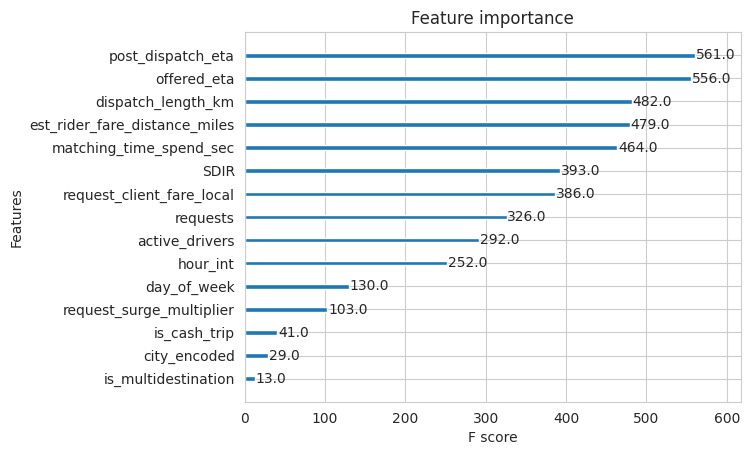

Accuracy for default XGBoost model: 0.9262
Fitting 3 folds for each of 50 candidates, totalling 150 fits


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:23:21] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Best Parameters:  {'colsample_bytree': np.float64(0.8118602313424026), 'learning_rate': np.float64(0.0825556872701355), 'max_depth': 8, 'n_estimators': 189, 'subsample': np.float64(0.8233173814428391)}
Tuned Model Accuracy: 0.9278


In [305]:



# X_col= ['is_airport_trip','is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
#        'is_multidestination', 'day_of_week',
#        'request_client_fare_local', 'request_surge_multiplier',
#        'post_dispatch_eta', 'est_rider_fare_distance_miles',
#        'active_drivers', 'requests', 'SDIR', 'offered_eta', 'dispatch_length_km',
#        'matching_time_spend_sec', 'acceptance_count', 'decline_count',
#        'cancellation_count', 'total_count', 'avg_active_time_minutes',
#        'avg_enroute_time_minutes', 'avg_ontrip_time_minutes',
#        'avg_open_time_minutes', 'avg_unavailable_time_minutes', 'hour_int',
#        'city_encoded', 'product_type']

# final3.info()


X_col= ['is_airport_trip','is_business_trip', 'is_cash_trip', 'is_scheduled_trip',
       'is_multidestination', 'day_of_week',
       'request_client_fare_local', 'request_surge_multiplier',
       'post_dispatch_eta', 'est_rider_fare_distance_miles',
       'active_drivers', 'requests', 'SDIR', 'offered_eta', 'dispatch_length_km',
       'matching_time_spend_sec', 'hour_int', 'product_type', 'city_encoded']

y_col = ['is_reliable_pickup']

selected_features, X_train_selected, X_test_selected, y_train, y_test = initial_model_training_testing(final3, X_col, y_col)
best_model = parameter_tunning(X_train_selected, y_train)
best_model_eval(best_model, X_test_selected, y_test)

##4. Marketplace health of cities

In [334]:
def stat_across_city(df, var):
    # Create dictionary for aggregation with dynamic column names
    agg_dict = {
        f'average_{var}': 'mean',
        f'median_{var}': 'median',
        f'min_{var}': 'min',
        f'max_{var}': 'max',
        'count': 'count'
    }

    # Calculate statistics
    stats_df = df.groupby('city')[var].agg(**agg_dict).reset_index()

    # Round numeric columns (excluding count)
    for col in stats_df.columns:
        if col not in ['city', 'count']:
            stats_df[col] = stats_df[col].round(2)

    return stats_df

In [335]:
completion_rate = (requested_rides2
                .groupby(['city', 'request_status'])
                .size()
                .unstack(fill_value=0))

# Calculate completion rate
completion_rate['completion_rate(%)'] = (completion_rate['completed'] /
                                     completion_rate.sum(axis=1) * 100).round(1)


completion_rate

request_status,completed,driver_canceled,failed,rider_canceled,unfulfilled,completion_rate(%)
city,,,,,,
A,33756,185,0,2596,318,91.6
B,20314,464,1,6718,1455,70.2
C,11146,256,2,4681,732,66.3


In [336]:
#Driver Acceptance Rate
# of Accepted Jobs / # of Jobs Offered

driver_acceptance_rate = (driver_dispatches
                         .groupby(['city', 'is_accept'])
                         .size()
                         .unstack(fill_value=0)
                         .rename(columns={True: 'accepted', False: 'rejected'}))

driver_acceptance_rate['acceptance_rate(%)'] = (
    driver_acceptance_rate['accepted'] /
    (driver_acceptance_rate['accepted'] + driver_acceptance_rate['rejected']) * 100
).round(1)

driver_acceptance_rate

is_accept,rejected,accepted,acceptance_rate(%)
city,,,
A,10087,36288,78.2
B,30977,28598,48.0
C,37845,13490,26.3


In [337]:
# dispatch_length_km

dispatch_length_km = stat_across_city(driver_dispatches, 'dispatch_length_km')
dispatch_length_km

,city,average_dispatch_length_km,median_dispatch_length_km,min_dispatch_length_km,max_dispatch_length_km,count
0,A,2.05,1.17,0.0,22.44,46375
1,B,3.23,2.45,0.0,23.07,59575
2,C,3.76,3.05,0.0,23.71,51335


In [338]:
hourly_driver_state_duration['enroute_ontrip_ratio'] = hourly_driver_state_duration['ontrip_time_ms'] / (hourly_driver_state_duration['ontrip_time_ms']+hourly_driver_state_duration['enroute_time_ms'])

In [339]:
enroute_ontrip_ratio=stat_across_city(hourly_driver_state_duration[hourly_driver_state_duration['ontrip_time_ms']>0], 'enroute_ontrip_ratio')
enroute_ontrip_ratio

,city,average_enroute_ontrip_ratio,median_enroute_ontrip_ratio,min_enroute_ontrip_ratio,max_enroute_ontrip_ratio,count
0,A,0.67,0.68,0.0,1.0,21822
1,B,0.63,0.63,0.0,1.0,14473
2,C,0.59,0.58,0.0,1.0,6959


In [340]:
accepted_jobs = driver_dispatches[driver_dispatches['is_accept'] == True]

cancel_rate = accepted_jobs.groupby('city').agg(
    total_accepted=('is_accept', 'count'),
    total_canceled=('is_cancel', 'sum'),
).reset_index()

cancel_rate['cancellation_rate(%)'] = (cancel_rate['total_canceled'] / cancel_rate['total_accepted'] * 100).round(1)

cancel_rate

,city,total_accepted,total_canceled,cancellation_rate(%)
0,A,36288,1241,3.4
1,B,28598,5386,18.8
2,C,13490,1212,9.0


In [341]:
rider_cancellation_rate = requested_rides2.groupby('city')['request_status'].agg(
    total_requests='count',
    cancelled_requests=lambda x: x.isin(['rider_canceled']).sum()
).reset_index()

# Calculate cancellation rate percentage
rider_cancellation_rate['cancellation_rate(%)'] = (
    rider_cancellation_rate['cancelled_requests'] /
    rider_cancellation_rate['total_requests'] * 100
).round(1)

rider_cancellation_rate

,city,total_requests,cancelled_requests,cancellation_rate(%)
0,A,36855,2596,7.0
1,B,28952,6718,23.2
2,C,16817,4681,27.8


In [342]:
sdir = stat_across_city(requested_rides_supply[
    requested_rides_supply['SDIR'].notna() &
    ~np.isinf(requested_rides_supply['SDIR'])
], 'SDIR')

sdir

,city,average_SDIR,median_SDIR,min_SDIR,max_SDIR,count
0,A,0.84,0.83,0.23,12.0,36855
1,B,0.76,0.73,0.00,9.0,28952
2,C,0.66,0.59,0.00,5.5,16817


In [343]:
#utilization rate

hourly_driver_state_duration['active_open_ratio'] = hourly_driver_state_duration['active_time_ms'] / (hourly_driver_state_duration['active_time_ms']+hourly_driver_state_duration['open_time_ms'])

utilization_rate = stat_across_city(hourly_driver_state_duration[hourly_driver_state_duration['open_time_ms']>0], 'active_open_ratio')
utilization_rate

,city,average_active_open_ratio,median_active_open_ratio,min_active_open_ratio,max_active_open_ratio,count
0,A,0.35,0.33,0.0,1.0,30922
1,B,0.38,0.38,0.0,1.0,22043
2,C,0.38,0.35,0.0,1.0,11029


In [ ]:
# rider_conversion_rate
# driver_acceptance_rate
# dispatch_length_km
# enroute_ontrip_ratio
# cancel_rate
# rider_cancellation_rate
# sdir
# utilization_rate

In [344]:
import pandas as pd

# List of all DataFrames with their merge keys (all should include 'city')
dataframes = {
    'conversion': completion_rate,
    'acceptance': driver_acceptance_rate,
    'dispatch': dispatch_length_km,
    'enroute': enroute_ontrip_ratio,
    'cancel': cancel_rate,
    'rider_cancel': rider_cancellation_rate,
    'sdir': sdir,
    'utilization': utilization_rate
}

# Initialize with first dataframe
merged = dataframes['conversion']

# Iteratively merge with inner join
for name, df in list(dataframes.items())[1:]:
    merged = pd.merge(
        merged,
        df,
        on='city',
        how='inner',
        suffixes=('', f'_{name}')  # Add suffix only to duplicate columns
    )

# Remove any duplicate columns (keeping original)
merged = merged.loc[:, ~merged.columns.duplicated()]

# Clean column names (remove any suffixes from the merge)
merged.columns = [col.split('_')[0] if '_conversion' in col else col
                 for col in merged.columns]


merged

,city,completed,driver_canceled,failed,rider_canceled,unfulfilled,completion_rate(%),rejected,accepted,acceptance_rate(%),...,average_SDIR,median_SDIR,min_SDIR,max_SDIR,count_sdir,average_active_open_ratio,median_active_open_ratio,min_active_open_ratio,max_active_open_ratio,count_utilization
0,A,33756,185,0,2596,318,91.6,10087,36288,78.2,...,0.84,0.83,0.23,12.0,36855,0.35,0.33,0.0,1.0,30922
1,B,20314,464,1,6718,1455,70.2,30977,28598,48.0,...,0.76,0.73,0.00,9.0,28952,0.38,0.38,0.0,1.0,22043
2,C,11146,256,2,4681,732,66.3,37845,13490,26.3,...,0.66,0.59,0.00,5.5,16817,0.38,0.35,0.0,1.0,11029


In [345]:
merged = merged[['city', 'completion_rate(%)',
                 'acceptance_rate(%)', 'median_dispatch_length_km',
                 'median_enroute_ontrip_ratio', 'cancellation_rate(%)',
                 'cancellation_rate(%)_rider_cancel', 'median_SDIR', 'median_active_open_ratio']]

merged

,city,completion_rate(%),acceptance_rate(%),median_dispatch_length_km,median_enroute_ontrip_ratio,cancellation_rate(%),cancellation_rate(%)_rider_cancel,median_SDIR,median_active_open_ratio
0,A,91.6,78.2,1.17,0.68,3.4,7.0,0.83,0.33
1,B,70.2,48.0,2.45,0.63,18.8,23.2,0.73,0.38
2,C,66.3,26.3,3.05,0.58,9.0,27.8,0.59,0.35


In [346]:
# driver_acceptance_rate

#rider conversion rate = requests/ sessions


rider_conversion_rate = rider_sessions.groupby('city').agg(
    total_sessions=('rider_session_id', 'count'),  # Count all sessions
    total_requests=('request_id', 'count'),        # Count non-null requests
    requests_per_session=('request_id', lambda x: x.notna().sum() / len(x))  # Ratio
).reset_index()


rider_conversion_rate['requests_per_session (%)'] = (rider_conversion_rate['requests_per_session'] * 100).round(1)

rider_conversion_rate

,city,total_sessions,total_requests,requests_per_session,requests_per_session (%)
0,A,68813,36855,0.535582,53.6
1,B,47127,28952,0.614340,61.4
2,C,29507,16817,0.569933,57.0


In [347]:
driver_acceptance_rate

is_accept,rejected,accepted,acceptance_rate(%)
city,,,
A,10087,36288,78.2
B,30977,28598,48.0
C,37845,13490,26.3


In [348]:
completion_rate

request_status,completed,driver_canceled,failed,rider_canceled,unfulfilled,completion_rate(%)
city,,,,,,
A,33756,185,0,2596,318,91.6
B,20314,464,1,6718,1455,70.2
C,11146,256,2,4681,732,66.3


In [349]:
avg_post_dispatch_eta = rider_sessions.groupby('city')['post_dispatch_eta'].mean()
avg_post_dispatch_eta

,post_dispatch_eta
city,
A,193.888688
B,294.718816
C,419.380754


In [350]:
hourly_driver_state_duration['utilization_ratio'] = (
    hourly_driver_state_duration['active_time_ms']
    / (hourly_driver_state_duration['active_time_ms'] + hourly_driver_state_duration['open_time_ms']))

hourly_driver_state_duration.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64812 entries, 0 to 64811
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   city                  64812 non-null  object        
 1   driver_id             64812 non-null  object        
 2   hour_bin              64812 non-null  datetime64[ns]
 3   active_time_ms        64812 non-null  int64         
 4   enroute_time_ms       64812 non-null  int64         
 5   ontrip_time_ms        64812 non-null  int64         
 6   open_time_ms          64812 non-null  int64         
 7   unavailable_time_ms   64812 non-null  int64         
 8   enroute_ontrip_ratio  47373 non-null  float64       
 9   active_open_ratio     64789 non-null  float64       
 10  utilization_ratio     64789 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(5), object(2)
memory usage: 5.4+ MB


In [351]:
# Group by city and calculate mean utilization
avg_utilization_by_city = (
    hourly_driver_state_duration
    .groupby('city')['utilization_ratio']
    .mean()
    .reset_index()
    .rename(columns={'utilization_ratio': 'avg_utilization'})
)

# Format as percentage (optional)
avg_utilization_by_city['avg_utilization_pct'] = (avg_utilization_by_city['avg_utilization'] * 100).round(1)


avg_utilization_by_city

,city,avg_utilization,avg_utilization_pct
0,A,0.351642,35.2
1,B,0.387446,38.7
2,C,0.395108,39.5


In [352]:
df = requested_rides_supply_drivers.copy()
df['quality_time_rider'] = df['matching_time_spend_sec']+df['post_dispatch_eta']
rider_quality_time = stat_across_city(df, 'quality_time_rider')
rider_quality_time

,city,average_quality_time_rider,median_quality_time_rider,min_quality_time_rider,max_quality_time_rider,count
0,A,268.38,183.0,2.0,6940.0,45583
1,B,538.43,428.0,-1738.0,7789.0,51779
2,C,675.01,606.0,-1759.0,3889.0,36677


In [353]:
dataframes = {
    'rider request rate': rider_conversion_rate,
    'completion rate': completion_rate,
    'driver acceptance rate': driver_acceptance_rate,
    'utilization_ratio': avg_utilization_by_city,
    'post_dispatch_eta': avg_post_dispatch_eta

}

# Initialize with first dataframe
merged = dataframes['rider request rate']

# Iteratively merge with inner join
for name, df in list(dataframes.items())[1:]:
    merged = pd.merge(
        merged,
        df,
        on='city',
        how='inner',
        suffixes=('', f'_{name}')  # Add suffix only to duplicate columns
    )

# Remove any duplicate columns (keeping original)
merged = merged.loc[:, ~merged.columns.duplicated()]

# Clean column names (remove any suffixes from the merge)
merged.columns = [col.split('_')[0] if '_conversion' in col else col
                 for col in merged.columns]

In [354]:
merged

,city,total_sessions,total_requests,requests_per_session,requests_per_session (%),completed,driver_canceled,failed,rider_canceled,unfulfilled,completion_rate(%),rejected,accepted,acceptance_rate(%),avg_utilization,avg_utilization_pct,post_dispatch_eta
0,A,68813,36855,0.535582,53.6,33756,185,0,2596,318,91.6,10087,36288,78.2,0.351642,35.2,193.888688
1,B,47127,28952,0.614340,61.4,20314,464,1,6718,1455,70.2,30977,28598,48.0,0.387446,38.7,294.718816
2,C,29507,16817,0.569933,57.0,11146,256,2,4681,732,66.3,37845,13490,26.3,0.395108,39.5,419.380754


In [355]:
merged['completed_rate_over_sessions'] = merged['completed']/merged['total_sessions']

In [356]:
merged.columns

Index(['city', 'total_sessions', 'total_requests', 'requests_per_session',
       'requests_per_session (%)', 'completed', 'driver_canceled', 'failed',
       'rider_canceled', 'unfulfilled', 'completion_rate(%)', 'rejected',
       'accepted', 'acceptance_rate(%)', 'avg_utilization',
       'avg_utilization_pct', 'post_dispatch_eta',
       'completed_rate_over_sessions'],
      dtype='object')

In [357]:
merged

,city,total_sessions,total_requests,requests_per_session,requests_per_session (%),completed,driver_canceled,failed,rider_canceled,unfulfilled,completion_rate(%),rejected,accepted,acceptance_rate(%),avg_utilization,avg_utilization_pct,post_dispatch_eta,completed_rate_over_sessions
0,A,68813,36855,0.535582,53.6,33756,185,0,2596,318,91.6,10087,36288,78.2,0.351642,35.2,193.888688,0.490547
1,B,47127,28952,0.614340,61.4,20314,464,1,6718,1455,70.2,30977,28598,48.0,0.387446,38.7,294.718816,0.431048
2,C,29507,16817,0.569933,57.0,11146,256,2,4681,732,66.3,37845,13490,26.3,0.395108,39.5,419.380754,0.377741


In [492]:
merged[['city', 'requests_per_session (%)', 'completion_rate(%)', 'completed_rate_over_sessions']]

,city,requests_per_session (%),completion_rate(%),completed_rate_over_sessions
0,A,53.6,91.6,0.490547
1,B,61.4,70.2,0.431048
2,C,57.0,66.3,0.377741


In [358]:
merged2 = merged[['city','requests_per_session (%)', 'completion_rate(%)', 'completed_rate_over_sessions', 'post_dispatch_eta',
                  'acceptance_rate(%)', 'avg_utilization_pct']]

In [359]:
merged2

,city,requests_per_session (%),completion_rate(%),completed_rate_over_sessions,post_dispatch_eta,acceptance_rate(%),avg_utilization_pct
0,A,53.6,91.6,0.490547,193.888688,78.2,35.2
1,B,61.4,70.2,0.431048,294.718816,48.0,38.7
2,C,57.0,66.3,0.377741,419.380754,26.3,39.5


In [360]:
merged3 = merged2.drop(columns=['completed_rate_over_sessions'])

In [508]:
# rider_sessions.groupby('city').est_rider_fare_distance_miles

stat_across_city(rider_sessions, 'est_rider_fare_distance_miles')

,city,average_est_rider_fare_distance_miles,median_est_rider_fare_distance_miles,min_est_rider_fare_distance_miles,max_est_rider_fare_distance_miles,count
0,A,3.76,2.25,0.0,203.49,36282
1,B,3.91,2.87,0.0,196.09,28931
2,C,3.76,2.40,0.0,171.34,16796


In [510]:
stat_across_city(rider_sessions[rider_sessions['request_status'] == 'completed'], 'est_rider_fare_distance_miles')

,city,average_est_rider_fare_distance_miles,median_est_rider_fare_distance_miles,min_est_rider_fare_distance_miles,max_est_rider_fare_distance_miles,count
0,A,3.55,2.21,0.00,203.49,33285
1,B,3.71,2.81,0.00,196.09,20309
2,C,3.55,2.44,0.01,171.34,11143


In [361]:
stat_across_city(rider_sessions[(rider_sessions['request_status'] != 'completed')&(rider_sessions['request_id'].notna())], 'est_rider_fare_distance_miles')

,city,average_est_rider_fare_distance_miles,median_est_rider_fare_distance_miles,min_est_rider_fare_distance_miles,max_est_rider_fare_distance_miles,count
0,A,6.04,3.19,0.0,163.99,2997
1,B,4.40,3.04,0.0,142.57,8622
2,C,4.18,2.29,0.0,114.67,5653


In [512]:
stat_across_city(rider_sessions[rider_sessions['request_status'] == 'completed'], 'post_dispatch_eta')

,city,average_post_dispatch_eta,median_post_dispatch_eta,min_post_dispatch_eta,max_post_dispatch_eta,count
0,A,187.66,137.0,1.0,1138.0,33756
1,B,255.63,207.0,1.0,2934.0,20314
2,C,393.39,337.0,1.0,3264.0,11146


In [513]:
stat_across_city(rider_sessions[rider_sessions['request_status'] != 'completed'], 'post_dispatch_eta')

,city,average_post_dispatch_eta,median_post_dispatch_eta,min_post_dispatch_eta,max_post_dispatch_eta,count
0,A,328.75,257.0,1.0,1623.0,1559
1,B,472.22,434.0,1.0,7390.0,4474
2,C,576.49,550.0,1.0,3471.0,1844


In [364]:
# merged3.columns

merged3

,city,requests_per_session (%),completion_rate(%),post_dispatch_eta,acceptance_rate(%),avg_utilization_pct
0,A,53.6,91.6,193.888688,78.2,35.2
1,B,61.4,70.2,294.718816,48.0,38.7
2,C,57.0,66.3,419.380754,26.3,39.5


In [372]:
merged2


,city,requests_per_session (%),completion_rate(%),completed_rate_over_sessions,post_dispatch_eta,acceptance_rate(%),avg_utilization_pct
0,A,53.6,91.6,0.490547,193.888688,78.2,35.2
1,B,61.4,70.2,0.431048,294.718816,48.0,38.7
2,C,57.0,66.3,0.377741,419.380754,26.3,39.5


In [373]:
merged3

,city,requests_per_session (%),completion_rate(%),post_dispatch_eta,acceptance_rate(%),avg_utilization_pct
0,A,53.6,91.6,193.888688,78.2,35.2
1,B,61.4,70.2,294.718816,48.0,38.7
2,C,57.0,66.3,419.380754,26.3,39.5


In [391]:
import pandas as pd

df = merged3
df = df.rename(columns={'requests_per_session (%)': 'requests_per_session_pct',
                        'completion_rate(%)': 'completion_rate_pct',
                        'acceptance_rate(%)': 'acceptance_rate_pct'
                        })


percent_diff_df = df[['city']].copy()


for col in df.columns[1:]:
    if 'eta' in col.lower():  # For ETA, lower is better
        best_value = df[col].min()
        percent_diff_df[col + '_diff'] = (df[col] / best_value - 1) * 100
    else:  # For other metrics, higher is better
        best_value = df[col].max()
        percent_diff_df[col + '_diff'] = (df[col] / best_value - 1) * 100


print(percent_diff_df.round(2))


  city  requests_per_session_pct_diff  completion_rate_pct_diff  \
0    A                         -12.70                      0.00   
1    B                           0.00                    -23.36   
2    C                          -7.17                    -27.62   

   post_dispatch_eta_diff  acceptance_rate_pct_diff  avg_utilization_pct_diff  
0                     0.0                      0.00                    -10.89  
1                    52.0                    -38.62                     -2.03  
2                   116.3                    -66.37                      0.00  


In [392]:
merged3

,city,requests_per_session (%),completion_rate(%),post_dispatch_eta,acceptance_rate(%),avg_utilization_pct
0,A,53.6,91.6,193.888688,78.2,35.2
1,B,61.4,70.2,294.718816,48.0,38.7
2,C,57.0,66.3,419.380754,26.3,39.5


In [393]:
percent_diff_df

,city,requests_per_session_pct_diff,completion_rate_pct_diff,post_dispatch_eta_diff,acceptance_rate_pct_diff,avg_utilization_pct_diff
0,A,-12.703583,0.000000,0.000000,0.000000,-10.886076
1,B,0.000000,-23.362445,52.004132,-38.618926,-2.025316
2,C,-7.166124,-27.620087,116.299754,-66.368286,0.000000


In [394]:
weight = [1,1,-1,1,1]

weighted_df = percent_diff_df[percent_diff_df.columns[1:]] * weight
weighted_df

,requests_per_session_pct_diff,completion_rate_pct_diff,post_dispatch_eta_diff,acceptance_rate_pct_diff,avg_utilization_pct_diff
0,-12.703583,0.000000,-0.000000,0.000000,-10.886076
1,0.000000,-23.362445,-52.004132,-38.618926,-2.025316
2,-7.166124,-27.620087,-116.299754,-66.368286,0.000000


In [395]:
weighted_df['average_percent'] = weighted_df.mean(axis=1)

weighted_df['city'] = percent_diff_df['city']

cols = weighted_df.columns.tolist()

cols = ['city'] + [col for col in cols if col != 'city']

weighted_df = weighted_df[cols]
weighted_df

,city,requests_per_session_pct_diff,completion_rate_pct_diff,post_dispatch_eta_diff,acceptance_rate_pct_diff,avg_utilization_pct_diff,average_percent
0,A,-12.703583,0.000000,-0.000000,0.000000,-10.886076,-4.717932
1,B,0.000000,-23.362445,-52.004132,-38.618926,-2.025316,-23.202164
2,C,-7.166124,-27.620087,-116.299754,-66.368286,0.000000,-43.490850


In [366]:
#Ranking

# Higher is better
rank=pd.DataFrame()
rank['city'] = merged3['city']

# rank['rank_requests_per_session'] = merged3['requests_per_session (%)'].rank(ascending=True)
# rank['rank_completed_rate'] = merged3['completion_rate(%)'].rank(ascending=True)
rank['rank_completed_rate_over_sessions'] = merged3['completed_rate_over_sessions'].rank(ascending=True)

# Lower is better
# rank['rank_quality_time'] = merged2['median_quality_time_rider'].rank(ascending=False)
rank['rank_post_dispatch_eta'] = merged3['post_dispatch_eta'].rank(ascending=False)

# Higher is better
rank['rank_acceptance_rate'] = merged3['acceptance_rate(%)'].rank(ascending=True)
rank['rank_utilization'] = merged3['avg_utilization_pct'].rank(ascending=True)


rank

,city,rank_requests_per_session,rank_completed_rate,rank_post_dispatch_eta,rank_acceptance_rate,rank_utilization
0,A,1.0,3.0,3.0,3.0,1.0
1,B,3.0,2.0,2.0,2.0,2.0
2,C,2.0,1.0,1.0,1.0,3.0


In [367]:
rank.columns

Index(['city', 'rank_requests_per_session', 'rank_completed_rate',
       'rank_post_dispatch_eta', 'rank_acceptance_rate', 'rank_utilization'],
      dtype='object')

In [368]:
rank['total_score'] = rank[rank.columns[1:]].sum(axis=1)
rank = rank.sort_values(by='total_score', ascending=False)
rank

,city,rank_requests_per_session,rank_completed_rate,rank_post_dispatch_eta,rank_acceptance_rate,rank_utilization,total_score
0,A,1.0,3.0,3.0,3.0,1.0,11.0
1,B,3.0,2.0,2.0,2.0,2.0,11.0
2,C,2.0,1.0,1.0,1.0,3.0,8.0
